# Laguna Miscanti como control natural: ¿responde el área al clima cuando nadie la maneja?
**Proyecto de Data Science – Magíster** · Juan Pablo Maureira

Réplica del análisis de la Laguna Torca en la **Laguna Miscanti** (RN Los Flamencos, Antofagasta; ~23.73 °S, 67.77 °O; 4 140 m s.n.m.; endorreica; ~1 350 ha). En la Torca, la superficie depende de un canal artificial y del manejo de la barra de Llico, y el clima no supera a la persistencia. Miscanti no tiene canal, barra ni extracción documentada en su cuenca: es el caso de control.

Plantilla: `Claude outputs/Laguna_Torca_v2_CR2MET_corregido_2026-11-08.ipynb` (corregida y ejecutada de punta a punta). Se cambió solo lo necesario; cada cambio está en la tabla de la celda siguiente.

**Se ejecuta en dos etapas:**
1. **Etapa 1 (diagnóstico).** "Ejecutar todo" en Colab: verifica el polígono, baja de GEE la serie Landsat, JRC y ERA5-Land, extrae CR2MET, muestra la evidencia para cada decisión y **se detiene a propósito en la "Puerta de decisiones"** (después de la sección 3).
2. **Etapa 2 (análisis).** Completar el bloque *Decisiones de criterio* de la sección 0 y volver a "Ejecutar todo". Con los CSV en caché ya no se necesita GEE.

| Sección | Contenido |
|---|---|
| 0 | Configuración, parámetros y decisiones pendientes |
| 1 | GEE: verificación del polígono (1.0), serie Landsat (1.1) y JRC Monthly History (1.2) |
| 2 | Curación, estacionalidad (2.1), sesgo L7 − L5 y salto NDWI vs JRC (2.2) |
| 3 | Clima: CR2MET v2.0, extensión ERA5-Land (3.1), proyecciones (3.2, pendiente) · **Puerta de decisiones** |
| 4-7 | Base mensual, variación, correlaciones, modelos, Diebold-Mariano (7c) y hold-out (7d) |
| 8 | Proyección mensual (pendiente de la fuente) |
| 11 | Exportación |
| 12 | Modelo anual: objetivos por año hidrológico, SPEI, validación un año adelante, hold-out (12.6b) |
| 13 | Comparación Torca vs Miscanti |

Etiquetas del texto: **[Verificado]** comprobado con datos o código · **[Fuente]** documentación externa · **[Inferencia]** deducción · **[Especulación]** hipótesis por confirmar.

## Registro de cambios respecto de la plantilla de Torca

| # | Dónde | Cambio | Por qué |
|---|---|---|---|
| 1 | 0 | `NUBOSIDAD_MAX` 20 → 80 (solo pre-filtro de escena); `VALIDO_MIN = 0.95` (movido desde 12.1); `AREA_MIN_HA = None` (se deriva en 2); `FECHAS_AUDITADAS = []`; bloque **Decisiones de criterio** | Auditoría: el filtro de nubes debe medirse dentro del polígono y no en la escena. Las 44 ha y las fechas auditadas eran de la Torca |
| 2 | 1 | Polígono de Miscanti; caché `serie_laguna_miscanti_bruta.csv`; `MISIONES` agrega la banda SWIR1; función `cache_o_gee` | Cachés con "miscanti" para no mezclar lagunas (el error de Aculeo) |
| 3 | 1.0 (nueva) | Verificación del polígono con JRC (`max_extent` vectorizado e imagen de `occurrence`) | Confirmar que contiene todo Miscanti y no incluye Miñiques |
| 4 | 1.1 | Descarga: factores de escala C2 (×0.0000275 − 0.2); máscara QA con bits 0 (relleno), 1, 2, 3, 4 y 5; hectáreas válidas en el polígono y en la zona del lago; NDWI y MNDWI (> 0 evaluado como verde > NIR / SWIR1, porque `normalizedDifference` enmascara reflectancias negativas); nieve; path/row; una consulta por misión y tramo | Lecciones de la auditoría (bits 1 y 2, escala) y riesgo de hielo y nieve en el altiplano |
| 5 | 1.2 (movida desde 12.1) | JRC Monthly History v1.4 (1984-2021) + extensión v1.5 (2022-2024); caché `serie_laguna_miscanti_jrc.csv` | Clasificador único para comparar el salto L5/L7 → L8/L9 |
| 6 | 2 | Regla 0 (escenas con < 95 % del polígono válido) antes de las 5 reglas; `AREA_MIN_HA` = Q1 − 3·IQR de las escenas válidas. Reglas 1-5 **sin cambios** | Pedido explícito; umbral propio de Miscanti |
| 7 | 2.1 (nueva) | Estacionalidad del área y de las escenas descartadas, nieve, MNDWI − NDWI y JRC por mes | Evidencia para `MESES_USO` y el año hidrológico |
| 8 | 2.2 (nueva) | Sesgo L7 − L5 con pares (funciones movidas desde 12.2) y salto NDWI vs JRC en los mismos meses | Evidencia para `CORREGIR_SALTO_JRC` |
| 8b | 2.3 (nueva) | Diagnóstico de la máscara QA: hectáreas por bit y cuatro variantes de máscara frente a JRC | La primera ejecución mostró que la máscara con bits 1-5 marca como nube cientos de hectáreas de orilla en escenas despejadas |
| 9 | 3 | `LAT/LON` de Miscanti; caché `clima_cr2met_laguna_miscanti_mensual_1979_2019.csv`; patrón con "miscanti"; verificación del píxel (coordenadas, unidades, NaN, dominio, entorno 5×5); climatología mensual | Pedido explícito; evitar el error de Aculeo |
| 10 | 3.1 (nueva) | ERA5-Land (`ECMWF/ERA5_LAND/DAILY_AGGR`, a mensual) calibrado por mes contra CR2MET → clima 2020-2024 para el hold-out | CR2MET v2.0 termina en 2019 |
| 11 | 3.2 | Ya no se cargan los `proyeccin-de-la-*.csv` (son de la Torca). Opción A (decidida 2026-11-08): `proyeccion_cr2_miscanti_{precip,tmax,tmin}_mes.csv`, con control de ubicación (r ≥ 0.9 entre la lluvia del CSV y CR2MET en Miscanti: mes a mes si trae "producto-observacional"; si no, ciclo estacional 1986-2005) | El notebook de Aculeo usó las proyecciones de la Torca |
| 12 | Puerta (nueva) | Detiene la ejecución mientras falte una decisión | Las decisiones de criterio son tuyas |
| 13 | 4 | `anio_hidro()`, filtro `MESES_USO`, corrección opcional del salto con JRC, clima extendido en la base, títulos | Régimen altiplánico |
| 14 | 5 | Variación anual por año hidrológico; Kruskal-Wallis solo con los meses usados | Régimen altiplánico |
| 15 | 7c (nueva) | `epoca` por pliegue, Diebold-Mariano con HLN (h = 1 y h = 12) y bootstrap pareado por bloques | Misma exigencia que la auditoría de Torca |
| 16 | 7d (nueva) | Hold-out mensual 2020-2024 | Prueba fuera de muestra real |
| 17 | 8 y 12.7 | Proyecciones con el código de la plantilla (método delta por GCM y control), con meses de `MESES_USO` y año hidrológico; 12.7 proyecta los tres objetivos. Se omiten sin error si faltan los CSV | Opción A; sigue siendo un análisis de sensibilidad |
| 18 | 9 y 10 | **Eliminadas** (MICE y modelo anual del notebook original de Torca) | Responden a errores del notebook original de Torca; la 10 usa las proyecciones CR2 de Torca |
| 19 | 11 y 12.8 | Exportación con sufijo `miscanti_v1` | No sobrescribir los CSV de Torca (`anual12_*.csv`, etc.) |
| 20 | 12.1 | Serie extendida opcional con geometría y caché de Miscanti, máscara QA de bits 0-5 y agua como verde > NIR / SWIR1; JRC se movió a 1.2 | Coherencia con 1.1 |
| 21 | 12.2 y 12.3 | Año hidrológico, `MESES_USO` y JRC con extensión | Régimen altiplánico |
| 22 | 12.4 | Objetivos anuales por `OBJETIVOS_ANUALES` y año hidrológico (antes: "mínimo de enero-abril" y clima al 31-dic); `Tx` = Tmax media de los meses del objetivo | No copiar el objetivo mediterráneo de Torca |
| 23 | 12.6 y 12.6b | Años con `epoca` no identificada, DM-HLN y hold-out anual | Pedido explícito |
| 23b | 12.6c (nueva) | Repetición del análisis anual (correlaciones, validación, DM-HLN y hold-out) con JRC como segunda fuente | Decisión del 2026-11-08: JRC tiene mucho menos ruido que el NDWI por escena |
| 4b | 0 y 1.1 | `BITS_QA = (3, 4, 5)`; la caché lleva los bits en el nombre (`..._bruta_b345.csv`) | Decisión del 2026-11-08 con la evidencia de 2.3 |
| 24 | 13 (nueva) | Tabla Torca vs Miscanti (cifras de Torca leídas de `corrida_corregida_2026-11-08`) | Pedido explícito |
| 25 | 7 y 12.6 | Ejes con valores enteros en "RMSE por pliegue" y "Pronóstico a 1 año" | Solo formato: salían pliegues como 1.25 y años como 2002.5 |

### Decisiones de criterio (tuyas)

| Decisión | Parámetro (sección 0) | Valor | Evidencia |
|---|---|---|---|
| Polígono final | `POLIGONO_CONFIRMADO` | `True` (decidido 2026-11-08) | 1.0 |
| Máscara QA y serie de área | `BITS_QA` + 12.6c | Bits 3-5; JRC como segunda fuente (decidido 2026-11-08) | 2.3 |
| Meses que entran al análisis | `MESES_USO` | Octubre a abril (decidido 2026-11-08) | 2.1 |
| Año hidrológico | `MES_INICIO_HIDRO` | 7, julio-junio (decidido 2026-11-08) | 2.1 y 3 |
| Objetivos anuales | `OBJETIVOS_ANUALES` | Mínimo oct-dic, máximo mar-abr, media oct-abr (decidido 2026-11-08) | 2.1 y 12.4 |
| ¿Corregir el salto con JRC? | `CORREGIR_SALTO_JRC` | `True` (decidido 2026-11-08) | 2.2 |
| Fuente de proyecciones | `FUENTE_PROY` | `"A"`: CR2, CMIP5 (decidido 2026-11-08) | 3.2 |

## 0. Configuración e imports

In [1]:
import io
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.signal import savgol_filter
from scipy.stats import kendalltau, kruskal, spearmanr, theilslopes
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

In [2]:
# ----------------------------- Parámetros del proyecto -----------------------------
SEMILLA = 42
GEE_PROYECTO = "master-chess-412203"

FECHA_INICIO, FECHA_FIN = "1984-01-01", "2024-12-31"   # ventana de descarga Landsat
PERIODO_INFORME = ("2004", "2023")                      # periodo de las preguntas de investigación (área satelital)
NUBOSIDAD_MAX = 80                                      # % CLOUD_COVER máximo por escena (solo pre-filtro; Miscanti: el filtro real es VALIDO_MIN)
VALIDO_MIN = 0.95                                       # fracción mínima del polígono válida (sin relleno, nube, sombra, cirrus ni nieve)
AREA_MIN_HA = None                                      # Miscanti: se deriva en la sección 2 de la distribución de la serie (no las 44 ha de Torca)
FALLA_SLC_L7 = "2003-05-31"                             # Landsat 7 SLC-off
QUIEBRE_SENSOR = "2012-06-01"                           # 2012 no tiene escenas válidas: antes L5/L7, después L8/L9
FECHAS_AUDITADAS = []                                   # Miscanti: ninguna escena revisada visualmente todavía

FORZAR_DESCARGA = False          # True = vuelve a bajar las series desde GEE (ignora la caché)
COL_AREA = "area_hectareas"

# ----------------------------- Decisiones de criterio (tuyas; None = pendiente) -----------------------------
# La ejecución se detiene en la "Puerta de decisiones" (después de la sección 3) mientras falte alguna.
# Todas las decisiones de este bloque se tomaron el 2026-11-08 con la evidencia de la etapa 1 (ver resultados_miscanti_2026-11-08.md)
POLIGONO_CONFIRMADO = True       # DECIDIDO: JRC confirma Miscanti 100 % dentro y Miñiques 0 % (1.0)
BITS_QA = (3, 4, 5)              # DECIDIDO: máscara QA con bits 3 (nube), 4 (sombra) y 5 (nieve); sin 1 ni 2 (evidencia en 2.3)
MESES_USO = (10, 11, 12, 1, 2, 3, 4)   # DECIDIDO: oct-abr; may-sep con nieve/hielo y JRC sin dato (2.1)
MES_INICIO_HIDRO = 7             # DECIDIDO: año hidrológico julio-junio (lluvias dic-mar dentro del mismo año)
OBJETIVOS_ANUALES = {            # DECIDIDO (formato en el texto de 12.4)
    "min_pre_lluvia":  {"meses": (10, 11, 12), "agregacion": "min", "mes_corte": 9},                    # fin de la estación seca
    "max_post_lluvia": {"meses": (3, 4), "agregacion": "max", "mes_corte": 2},                          # después de dic-feb (59 % de la lluvia)
    "media_temporada": {"meses": (10, 11, 12, 1, 2, 3, 4), "agregacion": "mean", "mes_corte": 4, "min_meses": 3},
}
CORREGIR_SALTO_JRC = True        # DECIDIDO: restar a L8/L9 el desfase NDWI − JRC de 2.2 (−18.9 ha); `epoca` se mantiene en los modelos
FUENTE_PROY = "A"                # DECIDIDO: CSV del explorador CR2 (CMIP5, RCP 2.6/8.5) para el punto de Miscanti (ver 3.2)

# ----------------------------- Rutas -----------------------------
def resolver_base():
    """Colab: carpeta del proyecto en Drive. Local: busca una carpeta 'data' junto al notebook."""
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/Predicción laguna torca/data")
    for candidata in (Path("data"), Path("../data"), Path("../../data")):
        if candidata.exists():
            return candidata
    return Path("data")


BASE = resolver_base()
DIR_RAW, DIR_PROC = BASE / "raw", BASE / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)


def buscar_archivo(patron, carpetas=(DIR_PROC, DIR_RAW)):
    """Primer archivo que coincide con el patrón (tolera diferencias de espacios/guiones en los nombres)."""
    for carpeta in carpetas:
        hallados = sorted(carpeta.glob(patron))
        if hallados:
            return hallados[0]
    return None


print("Carpeta de datos:", BASE.resolve())

Carpeta de datos: C:\Users\jp200\Escritorio\Predicción laguna torca\data


## 1. Google Earth Engine: polígono, serie Landsat y JRC

Las cuatro misiones Landsat se procesan con una sola función parametrizada por las bandas (verde, NIR y SWIR1). Las descargas se guardan en `data/processed` con nombres que incluyen "miscanti"; si el CSV ya existe, **no se necesita GEE**.

Polígono (WGS84) entregado por ti: unas 3 210 ha, más del doble del lago. [Verificado, OpenStreetMap, sin fecha] Con los contornos de OSM, Miscanti (≈ 1 292 ha) queda entera dentro, a ≥ 439 m del borde, y Miñiques (≈ 140 ha) queda entera fuera, a ≥ 617 m. La sección 1.0 lo comprueba con JRC.

In [3]:
COORDENADAS_MISCANTI = [
    [-67.7335066, -23.7054993], [-67.7793207, -23.6935134], [-67.8002643, -23.7499704],
    [-67.7569227, -23.7638147], [-67.7335066, -23.7054993],
]
CUERPOS = {   # el nombre de la caché incluye los bits QA: cambiar BITS_QA obliga a una descarga nueva
    "miscanti": {"coords": COORDENADAS_MISCANTI, "cache": f"serie_laguna_miscanti_bruta_b{''.join(map(str, BITS_QA))}.csv"},
}
CUERPO = "miscanti"

# colección -> (banda verde, banda NIR, banda SWIR1)
MISIONES = {
    "LANDSAT/LT05/C02/T1_L2": ("SR_B2", "SR_B4", "SR_B5"),
    "LANDSAT/LE07/C02/T1_L2": ("SR_B2", "SR_B4", "SR_B5"),
    "LANDSAT/LC08/C02/T1_L2": ("SR_B3", "SR_B5", "SR_B6"),
    "LANDSAT/LC09/C02/T1_L2": ("SR_B3", "SR_B5", "SR_B6"),
}


def iniciar_gee():
    import ee
    try:
        ee.Initialize(project=GEE_PROYECTO)
    except Exception:
        # modo 'notebook': muestra un enlace y una casilla para pegar el código (el modo por defecto de Colab abre una ventana emergente)
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=GEE_PROYECTO)
    return ee


def geometria(ee, cuerpo):
    return ee.Geometry.Polygon(CUERPOS[cuerpo]["coords"])


def cache_o_gee(nombre, funcion):
    """Lee `nombre` desde data/processed o data/raw; si no existe (o FORZAR_DESCARGA), lo calcula con GEE y lo guarda."""
    ruta = buscar_archivo(nombre)
    if ruta is not None and not FORZAR_DESCARGA:
        print(f"{nombre}: cargado desde caché")
        return pd.read_csv(ruta)
    print(f"{nombre}: calculando en Google Earth Engine (puede tardar varios minutos)...")
    df = funcion()
    df.to_csv(DIR_PROC / nombre, index=False)
    return df

### 1.0 Verificación del polígono (antes de cualquier análisis)

Se vectoriza el agua máxima de JRC (`max_extent`: agua al menos una vez entre 1984 y 2021) en un rectángulo de 3 km alrededor del polígono, y para cada cuerpo de agua se calcula su área y cuánta queda dentro. La prueba pasa si Miscanti está dentro en un 100 % y Miñiques (al sur, alimentada por filtración desde Miscanti) aporta menos de 0.5 ha. Se muestra además la imagen de `occurrence` con el polígono en rojo, para revisarla a ojo.

Si la prueba falla, **no sigas**: hay que proponer un polígono recortado y lo decides tú.

In [4]:
from IPython.display import Image as ImagenIPy

CACHE_POLIGONO = "verificacion_poligono_miscanti.csv"
BBOX_MINIQUES = (-67.7969, -23.7736, -67.7844, -23.7587)   # lon_min, lat_min, lon_max, lat_max (OpenStreetMap, way 52490908)
URL_POLIGONO = None


def verificar_poligono():
    """Cuerpos de agua de JRC (agua al menos una vez en 1984-2021, max_extent) en un rectángulo de 3 km alrededor del
    polígono: área total, área dentro del polígono y centroide de cada uno."""
    global URL_POLIGONO
    ee = iniciar_gee()
    geom = geometria(ee, CUERPO)
    region = geom.buffer(3000).bounds()
    gsw = ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
    agua = gsw.select("max_extent").eq(1).selfMask()
    vectores = agua.reduceToVectors(geometry=region, scale=30, geometryType="polygon", eightConnected=True,
                                    maxPixels=1e9, labelProperty="agua")

    def medir(f):
        g = f.geometry()
        c = g.centroid(1).coordinates()
        return f.set({"area_ha": g.area(1).divide(1e4), "dentro_ha": g.intersection(geom, 1).area(1).divide(1e4),
                      "lon": c.get(0), "lat": c.get(1)})

    feats = vectores.map(medir).filter(ee.Filter.gt("area_ha", 1)).getInfo()["features"]
    df = pd.DataFrame([f["properties"] for f in feats]).drop(columns=["agua"], errors="ignore")
    df["frac_dentro"] = df["dentro_ha"] / df["area_ha"]
    df["poligono_ha"] = geom.area(1).getInfo() / 1e4
    contorno = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(geom)]), 1, 2).visualize(palette=["ff0000"])
    URL_POLIGONO = (gsw.select("occurrence").unmask(0).visualize(min=0, max=100, palette=["f7f7f7", "08306b"])
                    .blend(contorno).getThumbURL({"region": region, "dimensions": 700, "format": "png"}))
    return df.sort_values("area_ha", ascending=False).reset_index(drop=True)


ver_pol = cache_o_gee(CACHE_POLIGONO, verificar_poligono)
display(ver_pol.round(3))
if URL_POLIGONO:
    print("Ocurrencia de agua JRC (azul = siempre agua) y polígono (rojo):", URL_POLIGONO)
    display(ImagenIPy(url=URL_POLIGONO))

mis = ver_pol.iloc[0]
en_miniques = ver_pol["lon"].between(BBOX_MINIQUES[0] - 0.005, BBOX_MINIQUES[2] + 0.005) & \
              ver_pol["lat"].between(BBOX_MINIQUES[1] - 0.005, BBOX_MINIQUES[3] + 0.005)
otros_dentro = ver_pol.iloc[1:].query("dentro_ha > 0.5")
print(f"Polígono: {ver_pol['poligono_ha'].iloc[0]:.0f} ha")
print(f"Mayor cuerpo de agua (Miscanti): {mis['area_ha']:.0f} ha de agua máxima JRC, {mis['frac_dentro']:.1%} dentro del polígono "
      f"(centroide {mis['lat']:.3f}, {mis['lon']:.3f})")
if en_miniques.any():
    m = ver_pol[en_miniques].iloc[0]
    print(f"Miñiques: {m['area_ha']:.0f} ha, {m['dentro_ha']:.1f} ha dentro del polígono")
else:
    print("No se encontró un cuerpo de agua JRC en la zona de Miñiques (revisar la imagen)")
print(f"Otros cuerpos de agua con > 0.5 ha dentro del polígono: {len(otros_dentro)}")
POLIGONO_OK = bool(mis["frac_dentro"] > 0.999 and (not en_miniques.any() or ver_pol[en_miniques]["dentro_ha"].max() < 0.5))
print("→ " + ("El polígono contiene todo Miscanti y nada de Miñiques. Si la imagen lo confirma, fija POLIGONO_CONFIRMADO = True."
              if POLIGONO_OK else "El polígono NO cumple: hay que recortarlo o ampliarlo antes de seguir (decisión tuya)."))

verificacion_poligono_miscanti.csv: cargado desde caché


,area_ha,count,dentro_ha,lat,lon,frac_dentro,poligono_ha
0,1319.368,16049,1319.368,-23.727,-67.768,1.0,3219.863
1,143.739,1749,0.000,-23.766,-67.792,0.0,3219.863
2,2.056,25,0.000,-23.676,-67.764,0.0,3219.863


Polígono: 3220 ha
Mayor cuerpo de agua (Miscanti): 1319 ha de agua máxima JRC, 100.0% dentro del polígono (centroide -23.727, -67.768)
Miñiques: 144 ha, 0.0 ha dentro del polígono
Otros cuerpos de agua con > 0.5 ha dentro del polígono: 0
→ El polígono contiene todo Miscanti y nada de Miñiques. Si la imagen lo confirma, fija POLIGONO_CONFIRMADO = True.


### 1.1 Serie Landsat por escena

Cambios respecto de la Torca, todos dentro de la descarga:

- **Factores de escala de Collection 2** (`SR = DN × 0.0000275 − 0.2`) antes de calcular índices [Fuente: USGS].
- **Máscara QA_PIXEL** con el bit 0 (relleno, incluye las franjas SLC-off) y los bits de `BITS_QA` [Fuente: catálogo GEE y guía LSDS-1619]. **Decisión del 2026-11-08: bits 3 (nube), 4 (sombra) y 5 (nieve).** El pedido original incluía también el 1 (nube dilatada) y el 2 (cirrus, solo en L8/L9). En Miscanti, la nube dilatada marcaba entre 39 y 91 ha de la zona del lago en escenas despejadas, y con los bits 1-5 pasaban 244 escenas en vez de 445 (sección 2.3). La caché lleva los bits en el nombre (`serie_laguna_miscanti_bruta_b345.csv`).
- **Fracción válida dentro del polígono** (`valido_ha / poligono_ha`) y en la **zona del lago** (agua alguna vez en JRC + 90 m). La regla de 0.95 se aplica al polígono, como pediste. La columna de la zona del lago sirve para ver si el 5 % inválido cae justo sobre el agua.
- **NDWI y MNDWI** (> 0, solo sobre píxeles válidos), evaluados como verde > NIR y verde > SWIR1. [Fuente: documentación de `ee.Image.normalizedDifference`] Esa función enmascara el píxel si alguna banda es negativa. [Verificado, 2026-11-08] Tras la escala, el NIR del agua oscura de Miscanti es negativo en 64 a 331 ha de lago por escena en L8/L9, y en ≤ 1.4 ha en L5. Con `normalizedDifference`, ese agua desaparecía y se fabricaba un salto de sensor de unos −100 a −300 ha. La regla verde > NIR da el mismo signo que el NDWI con DN de la Torca. La serie principal sigue siendo NDWI, como en la Torca. El MNDWI queda para comparar: es más sensible a la nieve y al hielo, porque su SWIR es muy bajo [Inferencia].
- `CLOUD_COVER < 80` es solo un pre-filtro: el filtro que decide es la fracción válida. El efecto de relajarlo se mide en 2.1.

In [5]:
TRAMOS = (("1984-01-01", "1995-01-01"), ("1995-01-01", "2006-01-01"), ("2006-01-01", "2016-01-01"), ("2016-01-01", "2025-01-01"))


def descargar_serie_landsat(cuerpo):
    """Una fila por escena con hectáreas dentro del polígono: con dato, válidas, agua NDWI > 0 y MNDWI > 0 (solo píxeles
    válidos), nieve y nube; y las mismas hectáreas válidas en la zona del lago (agua alguna vez en JRC + 90 m)."""
    ee = iniciar_gee()
    geom = geometria(ee, cuerpo)
    px_ha = ee.Image.pixelArea().divide(1e4)
    zona_lago = (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent").unmask(0)
                 .focalMax(radius=90, units="meters").gt(0))

    def procesar_con(verde, nir, swir):
        def procesar(img):
            qa = img.select("QA_PIXEL")

            def bit(k):
                return qa.bitwiseAnd(1 << k).neq(0)

            con_dato = bit(0).Not()                                  # bit 0 = relleno (incluye las franjas SLC-off de L7)
            # BITS_QA (sección 0): 1 nube dilatada, 2 cirrus (solo L8/L9), 3 nube, 4 sombra, 5 nieve
            nube = qa.bitwiseAnd(sum(1 << k for k in BITS_QA if k < 5)).neq(0)
            nieve = bit(5)                                           # se registra siempre; enmascara solo si 5 está en BITS_QA
            valido = con_dato.And(qa.bitwiseAnd(sum(1 << k for k in BITS_QA)).eq(0))
            sr = img.select([verde, nir, swir], ["verde", "nir", "swir1"]).multiply(0.0000275).add(-0.2)   # escala Collection 2
            # NDWI > 0 se evalúa como verde > NIR (MNDWI > 0: verde > SWIR1). normalizedDifference ENMASCARA los píxeles con
            # reflectancia negativa, y el NIR del agua oscura en L8/L9 suele quedar < 0 tras la escala (verificado 2026-11-08).
            # El signo de verde − NIR es el mismo con DN o con reflectancia escalada (misma pendiente en ambas bandas).
            agua_ndwi = sr.select("verde").gt(sr.select("nir"))
            agua_mndwi = sr.select("verde").gt(sr.select("swir1"))
            capas = ee.Image.cat([
                ee.Image.constant(1).rename("poligono_ha"),
                con_dato.rename("con_dato_ha"),
                valido.rename("valido_ha"),
                valido.And(agua_ndwi).rename("ndwi_ha"),
                valido.And(agua_mndwi).rename("mndwi_ha"),
                con_dato.And(nieve).rename("nieve_ha"),
                con_dato.And(nube).rename("nube_ha"),
                zona_lago.rename("lago_ha"),
                valido.And(zona_lago).rename("valido_lago_ha"),
            ]).multiply(px_ha)
            suma = capas.reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9)
            wrs = (ee.Number(img.get("WRS_PATH")).format("%03d").cat("/")
                   .cat(ee.Number(img.get("WRS_ROW")).format("%03d")))
            return ee.Feature(None, suma).set({"fecha": img.date().format("YYYY-MM-dd"),
                                               "satelite": img.get("SPACECRAFT_ID"),
                                               "cloud_cover": img.get("CLOUD_COVER"), "wrs": wrs})
        return procesar

    filas = []
    for id_coleccion, (verde, nir, swir) in MISIONES.items():   # una consulta por misión y tramo (límite de getInfo)
        n = 0
        for ini, fin in TRAMOS:
            ini, fin = max(ini, FECHA_INICIO), min(fin, FECHA_FIN)
            if ini >= fin:
                continue
            col = (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(ini, fin)
                   .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(procesar_con(verde, nir, swir)))
            feats = col.getInfo()["features"]
            filas += [f["properties"] for f in feats]
            n += len(feats)
        print(f"  {id_coleccion}: {n} escenas")
    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df[COL_AREA] = df["ndwi_ha"]                                 # serie principal: NDWI > 0 (como en Torca)
    return df.sort_values("fecha").reset_index(drop=True)


def cargar_serie_bruta(cuerpo):
    ruta = buscar_archivo(CUERPOS[cuerpo]["cache"])
    if ruta is not None and not FORZAR_DESCARGA:
        df = pd.read_csv(ruta, parse_dates=["fecha"])
        print(f"[{cuerpo}] serie cargada desde caché: {ruta.name}")
    else:
        print(f"[{cuerpo}] descargando desde Google Earth Engine (puede tardar varios minutos)...")
        df = descargar_serie_landsat(cuerpo)
        df.to_csv(DIR_PROC / CUERPOS[cuerpo]["cache"], index=False)
    df = (df.drop_duplicates(subset=["fecha", "satelite", "wrs"])
            .sort_values("fecha").reset_index(drop=True))
    print(f"[{cuerpo}] {len(df)} observaciones | {df['fecha'].min().date()} → {df['fecha'].max().date()}")
    return df


df_sat = cargar_serie_bruta(CUERPO)
df_sat["frac_valida"] = df_sat["valido_ha"] / df_sat["poligono_ha"]
df_sat["frac_valida_lago"] = df_sat["valido_lago_ha"] / df_sat["lago_ha"]
df_sat["frac_con_dato"] = df_sat["con_dato_ha"] / df_sat["poligono_ha"]
print(df_sat["satelite"].value_counts().to_string())
print("Órbitas (path/row):", df_sat["wrs"].value_counts().to_dict())
print(f"Escenas con ≥ {VALIDO_MIN:.0%} del polígono válido: {(df_sat['frac_valida'] >= VALIDO_MIN).sum()} de {len(df_sat)} | "
      f"con el polígono incompleto por el borde de la escena o relleno (< 99 % con dato): {(df_sat['frac_con_dato'] < 0.99).sum()}")
display(df_sat.head())

[miscanti] serie cargada desde caché: serie_laguna_miscanti_bruta_b345.csv
[miscanti] 1506 observaciones | 1984-10-14 → 2024-12-30
satelite
LANDSAT_7    606
LANDSAT_5    563
LANDSAT_8    267
LANDSAT_9     70
Órbitas (path/row): {'233/076': 1223, '232/077': 140, '232/076': 135, '233/077': 8}
Escenas con ≥ 95% del polígono válido: 455 de 1506 | con el polígono incompleto por el borde de la escena o relleno (< 99 % con dato): 679


,cloud_cover,con_dato_ha,fecha,lago_ha,mndwi_ha,ndwi_ha,nieve_ha,nube_ha,poligono_ha,satelite,valido_ha,valido_lago_ha,wrs,area_hectareas,frac_valida,frac_valida_lago,frac_con_dato
0,2.0,511.966170,1984-10-14,1438.36731,51.685430,41.584865,0.00000,11.826649,3212.341003,LANDSAT_5,500.139521,48.884320,232/076,41.584865,0.155693,0.033986,0.159375
1,11.0,518.180903,1984-10-14,1438.36731,53.648022,42.084775,0.00000,8.365830,3212.341003,LANDSAT_5,509.815073,48.966332,232/077,42.084775,0.158705,0.034043,0.161309
2,1.0,3212.341003,1985-01-25,1438.36731,1181.822303,1181.330383,0.00000,196.170649,3212.341003,LANDSAT_5,3016.170355,1288.039234,233/076,1181.330383,0.938932,0.895487,1.000000
3,1.0,3212.341003,1985-08-05,1438.36731,1097.144531,1091.443094,148.85372,128.264237,3212.341003,LANDSAT_5,2935.223047,1180.025213,233/076,1091.443094,0.913733,0.820392,1.000000
4,1.0,3212.341003,1986-01-12,1438.36731,1182.264538,1175.617865,0.00000,162.219771,3212.341003,LANDSAT_5,3050.121232,1294.107439,233/076,1175.617865,0.949501,0.899706,1.000000


### 1.2 JRC Monthly History (movida desde 12.1)

JRC aplica el **mismo clasificador** a Landsat 5, 7 y 8 en 1984-2021, así que su salto entre épocas no viene de un cambio de algoritmo. Es la referencia para calibrar el salto de NDWI [Fuente: catálogo GEE de JRC/GSW1_4].

[Fuente: global-surface-water.appspot.com/download] La extensión 2022-2024 (`projects/JRC/GSW1_5/MonthlyHistory_2022_2024`) se calculó con **Landsat Collection 2** (L8-9), mientras que la v1.4 usó Collection 1. Por eso puede haber un pequeño quiebre propio de JRC en 2022, y el desfase del salto de 2012 se estima solo con la v1.4. [Verificado en GEE, 2026-11-08] La extensión tiene 36 imágenes, con la banda `water` y los mismos valores 0/1/2 dentro del polígono; se asume la misma codificación de la v1.4 (0 = sin dato, 1 = tierra, 2 = agua). Sus imágenes **no** tienen `system:time_start`, así que la fecha se arma con las propiedades `year` y `month`.

In [6]:
CACHE_JRC = "serie_laguna_miscanti_jrc.csv"
JRC_COLECCIONES = {"v1.4": "JRC/GSW1_4/MonthlyHistory",                       # 1984-2021, Landsat Collection 1 (L5, L7, L8)
                   "v1.5": "projects/JRC/GSW1_5/MonthlyHistory_2022_2024"}    # 2022-2024, Landsat Collection 2 (L8, L9)


def descargar_jrc():
    """JRC Monthly Water History: hectáreas de agua (valor 2) y sin dato (valor 0) dentro del polígono, por mes."""
    ee = iniciar_gee()
    geom = geometria(ee, CUERPO)
    px_ha = ee.Image.pixelArea().divide(1e4)

    def procesar(img):
        w = img.select("water")
        suma = (ee.Image.cat([w.eq(2).rename("agua_ha"), w.eq(0).rename("sin_dato_ha"), w.gte(0).rename("poligono_ha")])
                .multiply(px_ha).reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9))
        # la extensión 2022-2024 no trae system:time_start: la fecha se arma con las propiedades year y month (las dos versiones las tienen)
        fecha = ee.Date.fromYMD(ee.Number(img.get("year")), ee.Number(img.get("month")), 1)
        return ee.Feature(None, suma).set("fecha", fecha.format("YYYY-MM-01"))

    filas = []
    for version, id_coleccion in JRC_COLECCIONES.items():
        col = ee.ImageCollection(id_coleccion).filterBounds(geom)
        print(f"  {version}: bandas {col.first().bandNames().getInfo()}")
        feats = col.map(procesar).getInfo()["features"]
        filas += [dict(f["properties"], version=version) for f in feats]
        print(f"  {version} ({id_coleccion}): {len(feats)} meses")
    return pd.DataFrame(filas)


df_jrc = cache_o_gee(CACHE_JRC, descargar_jrc)
df_jrc["fecha"] = pd.to_datetime(df_jrc["fecha"])
df_jrc = df_jrc.drop_duplicates(subset=["fecha", "version"]).sort_values("fecha").reset_index(drop=True)
df_jrc["frac_sin_dato"] = df_jrc["sin_dato_ha"] / df_jrc["poligono_ha"]
print(f"JRC: {len(df_jrc)} meses | {df_jrc['fecha'].min().date()} → {df_jrc['fecha'].max().date()} | "
      f"meses con < 5 % del polígono sin dato: {(df_jrc['frac_sin_dato'] < 0.05).sum()}")
display(df_jrc.groupby("version")[["agua_ha", "frac_sin_dato"]].describe().round(2).T)

serie_laguna_miscanti_jrc.csv: cargado desde caché
JRC: 490 meses | 1984-03-01 → 2024-12-01 | meses con < 5 % del polígono sin dato: 217


version                 v1.4     v1.5
agua_ha       count   454.00    36.00
              mean   1105.91  1264.83
              std     415.10    10.61
              min       0.00  1216.43
              25%    1260.80  1261.11
              50%    1281.18  1266.38
              75%    1295.39  1270.91
              max    1311.16  1278.27
frac_sin_dato count   454.00    36.00
              mean      0.24     0.08
              std       0.32     0.12
              min       0.00     0.00
              25%       0.02     0.00
              50%       0.11     0.02
              75%       0.27     0.13
              max       1.00     0.61

## 2. Curación de la serie satelital

0. **(Nueva)** Escenas con menos del 95 % del polígono válido (relleno, nube, sombra, cirrus o nieve) → se anulan.
1. Landsat 7 posterior a la falla del SLC (31-may-2003) → se anula (exclusión que se mantiene en la serie principal).
2. Área bajo el umbral físico `AREA_MIN_HA` → se anula. En Miscanti se deriva de su propia distribución: Q1 − 3·IQR de las escenas válidas sin L7 SLC-off (la "cerca muy lejana" de Tukey). No se reutilizan las 44 ha de la Torca.
3. Caída > 15 % respecto de la mediana móvil local → se anula.
4. "Valles" abruptos (< 45 días a cada lado) → se anulan.
5. Fechas auditadas manualmente → ninguna todavía.

[Inferencia] Las reglas 3 y 4 usan umbrales relativos pensados para una laguna de unas 125 ha. En Miscanti, un 15 % son unas 195 ha, más que todo su rango natural (≈ 94 ha según fuentes secundarias), así que casi no van a actuar. Las dejo sin cambios y la tabla de curación muestra cuántas escenas anula cada una. Si quieres umbrales propios, es una decisión tuya.

**Importante:** esta limpieza no corrige el cambio de sensor. Eso se analiza en 2.2 y 12.2.

Regla 0: 1051 de 1506 escenas con < 95% del polígono válido (relleno, nube, sombra, cirrus o nieve).
AREA_MIN_HA = Q1 − 3·IQR = 1196 − 3·62 = 1009 ha (cerca 'muy lejana' de Tukey sobre 450 escenas válidas sin L7 SLC-off; mediana 1224 ha). Lo que queda debajo no es compatible con la variación natural de la laguna: nube o hielo no marcados por QA, sombra o error de clasificación.
Escenas válidas bajo AREA_MIN_HA: 5


,registros anulados
0. Polígono válido < 95%,1051
1. Landsat 7 SLC-off,5
2. Área < 1009 ha,5
3. Caída > 15% vs mediana móvil,0
4. Valles abruptos,0
5. Fechas auditadas en GEE,0


Observaciones válidas: 445 de 1506


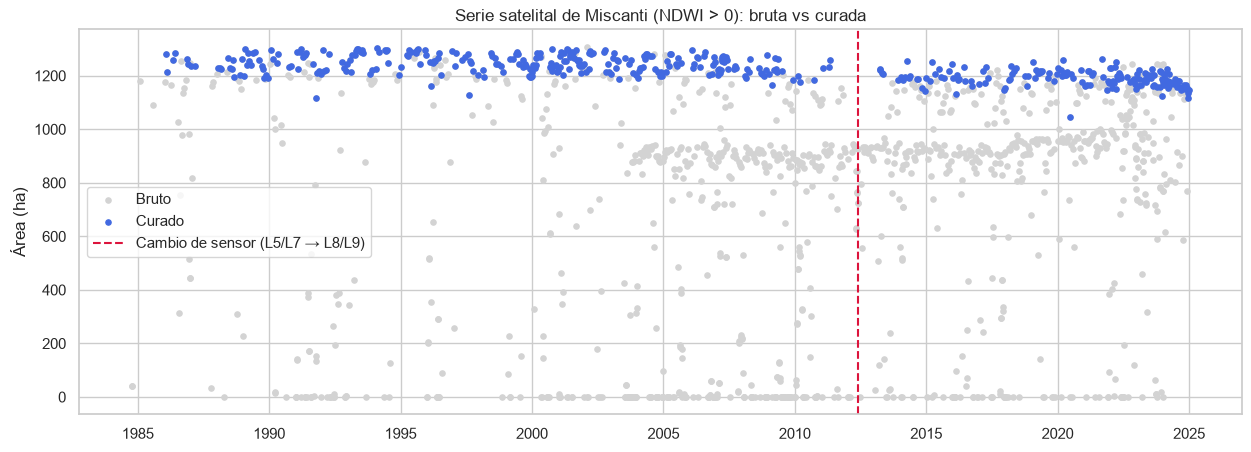

Área por sensor (escenas válidas):


,count,mean,std,min,max
sensor,,,,,
L5,233,1245.2,34.5,1116.7,1304.2
L7,49,1252.3,30.2,1187.6,1300.2
L8,123,1195.0,29.9,1045.6,1263.7
L9,40,1178.0,25.9,1116.8,1229.1


,count,mean,std
epoca,,,
L5/L7,282,1246.4,33.8
L8/L9,163,1190.9,29.8


Diferencia de nivel entre épocas: -55.5 ha (-1.6 desviaciones estándar de la época L5/L7).
Esta diferencia mezcla cambio de sensor y cambio real; con los datos actuales NO se pueden separar.


In [7]:
# ---- Regla 0 (Miscanti): escenas con menos de VALIDO_MIN del polígono válido se descartan antes de las 5 reglas
df_sat0 = df_sat.copy()
descarte_0 = df_sat0["frac_valida"] < VALIDO_MIN
df_sat0.loc[descarte_0, COL_AREA] = np.nan
print(f"Regla 0: {int(descarte_0.sum())} de {len(df_sat0)} escenas con < {VALIDO_MIN:.0%} del polígono válido "
      f"(relleno, nube, sombra, cirrus o nieve).")

# ---- AREA_MIN_HA derivada de la distribución de Miscanti (si no la fijaste a mano en la sección 0)
es_slc_off = df_sat0["satelite"].str.contains("LANDSAT_7", na=False) & (df_sat0["fecha"] > pd.Timestamp(FALLA_SLC_L7))
ref_area = df_sat0.loc[df_sat0[COL_AREA].notna() & ~es_slc_off, COL_AREA]
q1, q3 = ref_area.quantile([0.25, 0.75])
if AREA_MIN_HA is None:
    AREA_MIN_HA = float(q1 - 3 * (q3 - q1))
    print(f"AREA_MIN_HA = Q1 − 3·IQR = {q1:.0f} − 3·{q3 - q1:.0f} = {AREA_MIN_HA:.0f} ha (cerca 'muy lejana' de Tukey sobre "
          f"{len(ref_area)} escenas válidas sin L7 SLC-off; mediana {ref_area.median():.0f} ha). Lo que queda debajo no es "
          f"compatible con la variación natural de la laguna: nube o hielo no marcados por QA, sombra o error de clasificación.")
print(f"Escenas válidas bajo AREA_MIN_HA: {int((ref_area < AREA_MIN_HA).sum())}")


def curar_serie(df, area_min=AREA_MIN_HA, fechas_auditadas=()):
    """Aplica las 5 reglas de curación. Devuelve (serie curada indexada por fecha, resumen)."""
    s = df.set_index("fecha").copy()
    resumen = {}

    def anular(mascara, nombre):
        antes = s[COL_AREA].notna().sum()
        s.loc[np.asarray(mascara), COL_AREA] = np.nan
        resumen[nombre] = int(antes - s[COL_AREA].notna().sum())

    anular(s["satelite"].str.contains("LANDSAT_7", case=False, na=False) & (s.index > FALLA_SLC_L7),
           "1. Landsat 7 SLC-off")
    anular(s[COL_AREA] < area_min, f"2. Área < {area_min:.0f} ha")
    mediana = s[COL_AREA].rolling(window=7, center=True, min_periods=3).median()
    anular(s[COL_AREA] < mediana * 0.85, "3. Caída > 15% vs mediana móvil")

    v = s[s[COL_AREA].notna()]
    fechas = v.index.to_series()
    dias_prev, dias_next = fechas.diff().dt.days, (-fechas.diff(-1)).dt.days
    var_prev = v[COL_AREA].pct_change(fill_method=None)
    var_next = v[COL_AREA].pct_change(periods=-1, fill_method=None)
    es_valle = (var_prev < -0.15) & (var_next < -0.15) & (dias_prev <= 45) & (dias_next <= 45)
    anular(s.index.isin(v.index[es_valle.values]), "4. Valles abruptos")

    anular(s.index.isin(pd.to_datetime(list(fechas_auditadas))), "5. Fechas auditadas en GEE")
    return s, pd.Series(resumen, name="registros anulados")


serie_curada, resumen_curacion = curar_serie(df_sat0, AREA_MIN_HA, FECHAS_AUDITADAS)
resumen_curacion = pd.concat([pd.Series({f"0. Polígono válido < {VALIDO_MIN:.0%}": int(descarte_0.sum())}),
                              resumen_curacion]).rename("registros anulados")
display(resumen_curacion.to_frame())
print(f"Observaciones válidas: {serie_curada[COL_AREA].notna().sum()} de {len(serie_curada)}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.scatter(df_sat["fecha"], df_sat[COL_AREA], s=14, color="lightgray", label="Bruto")
ax.scatter(serie_curada.index, serie_curada[COL_AREA], s=14, color="royalblue", label="Curado")
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor (L5/L7 → L8/L9)")
ax.set(title="Serie satelital de Miscanti (NDWI > 0): bruta vs curada", ylabel="Área (ha)")
ax.legend()
plt.show()

# ---- Diagnóstico del cambio de sensor
valido = serie_curada[serie_curada[COL_AREA].notna()].copy()
valido["sensor"] = valido["satelite"].str.replace("LANDSAT_", "L", regex=False)
valido["epoca"] = np.where(valido.index > pd.Timestamp(QUIEBRE_SENSOR), "L8/L9", "L5/L7")
print("Área por sensor (escenas válidas):")
display(valido.groupby("sensor")[COL_AREA].agg(["count", "mean", "std", "min", "max"]).round(1))
por_epoca = valido.groupby("epoca")[COL_AREA].agg(["count", "mean", "std"]).round(1)
display(por_epoca)
SALTO_SENSOR_HA = por_epoca.loc["L8/L9", "mean"] - por_epoca.loc["L5/L7", "mean"]
print(f"Diferencia de nivel entre épocas: {SALTO_SENSOR_HA:+.1f} ha "
      f"({SALTO_SENSOR_HA / por_epoca.loc['L5/L7', 'std']:.1f} desviaciones estándar de la época L5/L7).")
print("Esta diferencia mezcla cambio de sensor y cambio real; con los datos actuales NO se pueden separar.")

serie_mensual = serie_curada[COL_AREA].resample("MS").mean()   # meses sin dato válido quedan en NaN (no se imputan)

### 2.1 ¿Qué meses usar? Estacionalidad del área y de las escenas descartadas

Riesgos propios del altiplano: hielo invernal sobre el lago, nieve en las orillas y costras salinas. La tabla por mes (sin L7 SLC-off) cruza cuántas escenas se descartan, cuánta nieve marca QA, cómo se aleja el área NDWI y MNDWI de la mediana de su época y qué ve JRC.

**Esta celda no decide nada.** Con su salida eliges `MESES_USO` y `MES_INICIO_HIDRO` en la sección 0.

,escenas,validas,validas_cc<20,frac_valida_mediana,nieve_mediana_ha,nieve_p90_ha,nube_mediana_ha,ndwi_anom_mediana_ha,ndwi_anom_p10_ha,mndwi_anom_mediana_ha,mndwi_menos_ndwi_ha,descartadas_%,jrc_sin_dato_%,jrc_agua_mediana_ha
mes,,,,,,,,,,,,,,
1,87,38,36,0.9,0.0,1.0,143.2,-14.6,-40.0,-16.5,6.6,56.3,11.3,1286.7
2,71,45,41,1.0,0.0,0.4,109.9,-15.5,-50.1,-10.2,6.0,36.6,11.9,1285.2
3,77,55,54,1.0,0.0,5.1,97.6,10.3,-29.7,9.9,7.5,28.6,17.8,1278.0
4,71,51,49,1.0,0.0,2.5,70.0,19.7,-7.7,19.5,6.4,28.2,22.1,1279.9
5,80,40,40,0.9,1.8,12.2,108.7,17.0,-14.1,22.5,4.0,50.0,32.1,NaN
6,75,30,30,0.6,4.3,1687.5,104.4,28.7,-15.8,24.2,6.2,60.0,44.2,NaN
7,91,28,28,0.6,5.3,1742.7,132.2,9.1,-24.1,15.5,4.8,69.2,39.6,NaN
8,78,24,24,0.9,9.4,1301.6,188.4,2.1,-43.5,3.7,1.1,69.2,36.8,NaN
9,89,31,31,0.9,0.6,461.7,159.3,-1.9,-45.4,-5.5,5.4,65.2,20.1,1285.7


Escenas que pasan VALIDO_MIN en el polígono pero tienen < 95% válido en la zona del lago: 247 (meses: {1: 24, 2: 27, 3: 25, 4: 15, 5: 19, 6: 9, 7: 16, 8: 13, 9: 20, 10: 23, 11: 28, 12: 28})
Escenas válidas que agrega relajar CLOUD_COVER de < 20 a < 80: 14
Cómo leerla: 'descartadas_%' y 'nieve_p90_ha' altos indican nieve o hielo marcados por QA; 'ndwi_anom_p10_ha' muy negativo con nieve baja indica hielo o costra NO marcados (el NDWI los cuenta como tierra); 'mndwi_menos_ndwi_ha' grande indica superficies que el MNDWI llama agua y el NDWI no (hielo, nieve, sal). 'jrc_sin_dato_%' alto = JRC tampoco clasifica ese mes.


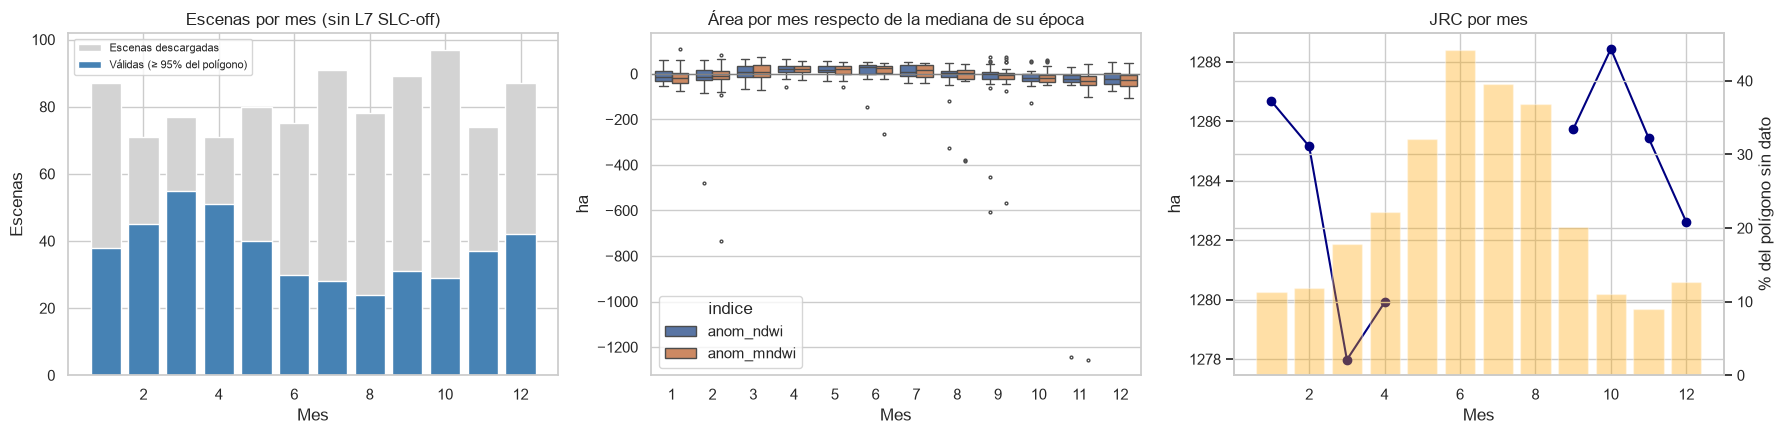

In [8]:
# ---- 2.1 Estacionalidad del área y de las escenas descartadas (evidencia para MESES_USO y el año hidrológico)
d21 = df_sat.copy()
d21["mes"] = d21["fecha"].dt.month
d21["epoca"] = (d21["fecha"] > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
d21 = d21[~(d21["satelite"].str.contains("LANDSAT_7", na=False) & (d21["fecha"] > pd.Timestamp(FALLA_SLC_L7)))]   # sin L7 SLC-off
v21 = d21[d21["frac_valida"] >= VALIDO_MIN].copy()
v21["anom_ndwi"] = v21[COL_AREA] - v21.groupby("epoca")[COL_AREA].transform("median")
v21["anom_mndwi"] = v21["mndwi_ha"] - v21.groupby("epoca")["mndwi_ha"].transform("median")
g21, gv = d21.groupby("mes"), v21.groupby("mes")
estac = pd.DataFrame({
    "escenas": g21.size(),
    "validas": gv.size(),
    "validas_cc<20": v21[v21["cloud_cover"] < 20].groupby("mes").size(),
    "frac_valida_mediana": g21["frac_valida"].median(),
    "nieve_mediana_ha": g21["nieve_ha"].median(),
    "nieve_p90_ha": g21["nieve_ha"].quantile(0.9),
    "nube_mediana_ha": g21["nube_ha"].median(),
    "ndwi_anom_mediana_ha": gv["anom_ndwi"].median(),
    "ndwi_anom_p10_ha": gv["anom_ndwi"].quantile(0.1),
    "mndwi_anom_mediana_ha": gv["anom_mndwi"].median(),
    "mndwi_menos_ndwi_ha": (v21["mndwi_ha"] - v21[COL_AREA]).groupby(v21["mes"]).median(),
}).reindex(range(1, 13))
estac["descartadas_%"] = 100 * (1 - estac["validas"].fillna(0) / estac["escenas"])
jrc_mes = df_jrc.assign(mes=df_jrc["fecha"].dt.month)
estac["jrc_sin_dato_%"] = 100 * jrc_mes.groupby("mes")["frac_sin_dato"].mean()
estac["jrc_agua_mediana_ha"] = jrc_mes[jrc_mes["frac_sin_dato"] < 0.05].groupby("mes")["agua_ha"].median()
estac.index.name = "mes"
display(estac.round(1))

riesgo = v21[v21["frac_valida_lago"] < VALIDO_MIN]
print(f"Escenas que pasan VALIDO_MIN en el polígono pero tienen < {VALIDO_MIN:.0%} válido en la zona del lago: {len(riesgo)} "
      f"(meses: {riesgo['mes'].value_counts().sort_index().to_dict()})")
print(f"Escenas válidas que agrega relajar CLOUD_COVER de < 20 a < {NUBOSIDAD_MAX}: "
      f"{int((estac['validas'] - estac['validas_cc<20']).sum())}")
print("Cómo leerla: 'descartadas_%' y 'nieve_p90_ha' altos indican nieve o hielo marcados por QA; 'ndwi_anom_p10_ha' muy negativo "
      "con nieve baja indica hielo o costra NO marcados (el NDWI los cuenta como tierra); 'mndwi_menos_ndwi_ha' grande indica "
      "superficies que el MNDWI llama agua y el NDWI no (hielo, nieve, sal). 'jrc_sin_dato_%' alto = JRC tampoco clasifica ese mes.")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(estac.index, estac["escenas"], color="lightgray", label="Escenas descargadas")
axes[0].bar(estac.index, estac["validas"], color="steelblue", label=f"Válidas (≥ {VALIDO_MIN:.0%} del polígono)")
axes[0].set(title="Escenas por mes (sin L7 SLC-off)", xlabel="Mes", ylabel="Escenas")
axes[0].legend(fontsize=8)
largo = v21.melt(id_vars="mes", value_vars=["anom_ndwi", "anom_mndwi"], var_name="indice", value_name="ha")
sns.boxplot(data=largo, x="mes", y="ha", hue="indice", ax=axes[1], fliersize=2)
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(title="Área por mes respecto de la mediana de su época", xlabel="Mes", ylabel="ha")
axes[2].plot(estac.index, estac["jrc_agua_mediana_ha"], "o-", color="navy", label="JRC agua (mediana, ha)")
ax2 = axes[2].twinx()
ax2.bar(estac.index, estac["jrc_sin_dato_%"], color="orange", alpha=0.35, label="JRC sin dato (%)")
axes[2].set(title="JRC por mes", xlabel="Mes", ylabel="ha")
ax2.set_ylabel("% del polígono sin dato")
plt.tight_layout()
plt.show()

### 2.2 Sesgo L7 − L5 y salto entre épocas con JRC

- **L7 vs L5** (igual que la sección 12.2 de la Torca): cada escena L7 válida se compara con la L5 válida más cercana (≤ 8 días). La mediana de las diferencias estima el sesgo de L7. Las funciones se movieron aquí desde 12.2, que las sigue usando.
- **Salto L5/L7 → L8/L9 con un clasificador único.** En los meses en que hay NDWI y JRC v1.4 a la vez, el desfase `mediana(NDWI − JRC | L8/L9) − mediana(NDWI − JRC | L5/L7)` es la parte del salto que JRC no ve, es decir, atribuible al sensor o al método NDWI. Es la evidencia para `CORREGIR_SALTO_JRC`.

[NDWI, serie curada] 25 pares L7–L5 (≤ 8 días): mediana L7 − L5 = +8.7 ha (IC 95 % bootstrap -4.3 a +31.2)
Diferencia L7 − L5 por mes del par (¿depende de la estación?):


fecha,1,2,3,4,6,7,9,10,11,12
count,2.0,2.0,2.0,2.0,2.0,2.0,5.0,3.0,3.0,2.0
median,41.2,8.3,70.7,-13.2,31.7,2.2,-3.5,-16.3,-4.3,25.0


meses  ndwi_media  jrc_media  dif_mediana  dif_desv
epoca version_jrc                                                     
L5/L7 v1.4 (C1)      111      1233.1     1292.4        -60.8      27.8
L8/L9 v1.4 (C1)       43      1194.5     1276.9        -79.8      25.6
      v1.5 (C2)       19      1175.1     1267.2        -86.4      18.8

Mismos meses, JRC v1.4 (1984-2021): salto NDWI -38.6 ha | salto JRC -15.5 ha
Desfase atribuible al sensor o al método (mediana de NDWI − JRC en L8/L9 menos en L5/L7): -18.9 ha (IC 95 % bootstrap -37.8 a -7.3; 111 y 43 meses)
Lectura: si el desfase ≈ salto NDWI, el salto es del sensor (JRC no lo ve); si ≈ 0, JRC también ve el salto (cambio real o artefacto común a ambos). Esto es la evidencia para CORREGIR_SALTO_JRC.


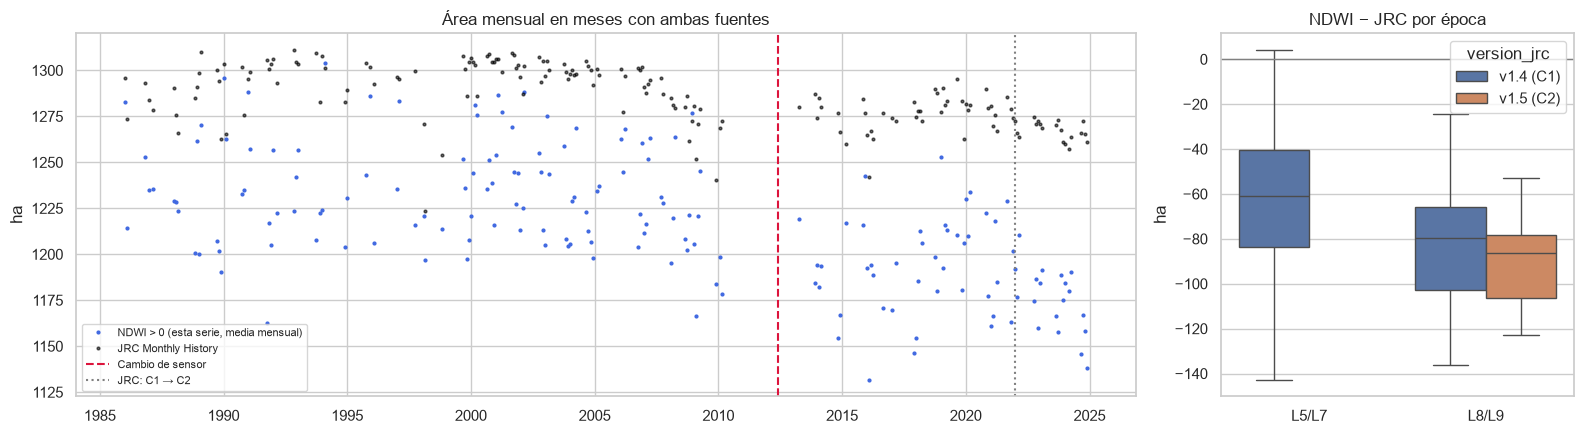

In [9]:
# ---- 2.2 Sesgo Landsat 7 − Landsat 5 (pares de escenas, como en 12.2) y salto entre épocas con un clasificador único (JRC)
CORREGIR_L7 = True              # (movido desde 12.1) llevar Landsat 7 al nivel de Landsat 5 con pares de escenas cercanas (12.2)
DIAS_PAR = 8                    # (movido desde 12.1) separación máxima (días) entre una escena L7 y una L5 para formar un par


def pares_l5_l7(curada, dias=DIAS_PAR):
    """Cada escena L7 válida con la escena L5 válida más cercana, si están a ≤ `dias` días."""
    v = curada[curada[COL_AREA].notna()]
    l5 = v.loc[v["satelite"].str.contains("LANDSAT_5", na=False), COL_AREA]
    l7 = v.loc[v["satelite"].str.contains("LANDSAT_7", na=False), COL_AREA]
    filas = []
    for fecha, a7 in l7.items():
        dist = np.abs((l5.index - fecha).days)
        if len(dist) and dist.min() <= dias:
            filas.append((fecha, a7, l5.iloc[dist.argmin()]))
    pares = pd.DataFrame(filas, columns=["fecha", "L7", "L5"])
    pares["dif_L7_menos_L5"] = pares["L7"] - pares["L5"]
    return pares


def calibrar_l7(curada, etiqueta):
    """Sesgo de L7 (mediana de L7 − L5 en pares) con IC bootstrap; si CORREGIR_L7, se resta a las escenas L7."""
    pares = pares_l5_l7(curada)
    if len(pares) < 5:
        print(f"[{etiqueta}] solo {len(pares)} pares L7–L5: no se calibra L7.")
        return curada, np.nan, pares
    rng = np.random.default_rng(SEMILLA)
    boot = [np.median(rng.choice(pares["dif_L7_menos_L5"].values, len(pares))) for _ in range(2000)]
    sesgo = pares["dif_L7_menos_L5"].median()
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"[{etiqueta}] {len(pares)} pares L7–L5 (≤ {DIAS_PAR} días): mediana L7 − L5 = {sesgo:+.1f} ha "
          f"(IC 95 % bootstrap {lo:+.1f} a {hi:+.1f})")
    out = curada.copy()
    if CORREGIR_L7:
        es_l7 = out["satelite"].str.contains("LANDSAT_7", na=False)
        out.loc[es_l7, COL_AREA] = out.loc[es_l7, COL_AREA] - sesgo
    return out, sesgo, pares


_, SESGO_L7_NDWI, pares_ndwi = calibrar_l7(serie_curada, "NDWI, serie curada")
if len(pares_ndwi):
    print("Diferencia L7 − L5 por mes del par (¿depende de la estación?):")
    display(pares_ndwi.groupby(pares_ndwi["fecha"].dt.month)["dif_L7_menos_L5"].agg(["count", "median"]).round(1).T)

# ---- Salto entre épocas: NDWI (esta serie) vs JRC (mismo clasificador para L5, L7 y L8), en los mismos meses
DELTA_SALTO_JRC = np.nan
jrc_m = df_jrc.set_index("fecha")["agua_ha"].where(df_jrc.set_index("fecha")["frac_sin_dato"] < 0.05).resample("MS").mean()
par = pd.DataFrame({"ndwi": serie_curada[COL_AREA].resample("MS").mean(), "jrc": jrc_m}).dropna()
par["dif"] = par["ndwi"] - par["jrc"]
par["epoca"] = np.where(par.index > pd.Timestamp(QUIEBRE_SENSOR), "L8/L9", "L5/L7")
par["version_jrc"] = np.where(par.index.year <= 2021, "v1.4 (C1)", "v1.5 (C2)")
display(par.groupby(["epoca", "version_jrc"]).agg(meses=("dif", "size"), ndwi_media=("ndwi", "mean"), jrc_media=("jrc", "mean"),
                                                   dif_mediana=("dif", "median"), dif_desv=("dif", "std")).round(1))
v14 = par[par["version_jrc"].str.startswith("v1.4")]
e0, e1 = v14[v14["epoca"] == "L5/L7"], v14[v14["epoca"] == "L8/L9"]
if min(len(e0), len(e1)) >= 5:
    DELTA_SALTO_JRC = e1["dif"].median() - e0["dif"].median()
    rng = np.random.default_rng(SEMILLA)
    boot = [np.median(rng.choice(e1["dif"].values, len(e1))) - np.median(rng.choice(e0["dif"].values, len(e0)))
            for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    SALTO_NDWI_PAREADO, SALTO_JRC_PAREADO = e1["ndwi"].mean() - e0["ndwi"].mean(), e1["jrc"].mean() - e0["jrc"].mean()
    print(f"Mismos meses, JRC v1.4 (1984-2021): salto NDWI {SALTO_NDWI_PAREADO:+.1f} ha | salto JRC {SALTO_JRC_PAREADO:+.1f} ha")
    print(f"Desfase atribuible al sensor o al método (mediana de NDWI − JRC en L8/L9 menos en L5/L7): {DELTA_SALTO_JRC:+.1f} ha "
          f"(IC 95 % bootstrap {lo:+.1f} a {hi:+.1f}; {len(e0)} y {len(e1)} meses)")
    print("Lectura: si el desfase ≈ salto NDWI, el salto es del sensor (JRC no lo ve); si ≈ 0, JRC también ve el salto "
          "(cambio real o artefacto común a ambos). Esto es la evidencia para CORREGIR_SALTO_JRC.")
else:
    SALTO_NDWI_PAREADO = SALTO_JRC_PAREADO = np.nan
    print(f"Meses pareados insuficientes por época ({len(e0)} L5/L7, {len(e1)} L8/L9): no se estima el desfase.")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(par.index, par["ndwi"], ".", ms=4, color="royalblue", label="NDWI > 0 (esta serie, media mensual)")
axes[0].plot(par.index, par["jrc"], ".", ms=4, color="black", alpha=0.6, label="JRC Monthly History")
axes[0].axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor")
axes[0].axvline(pd.Timestamp("2022-01-01"), color="gray", ls=":", label="JRC: C1 → C2")
axes[0].set(title="Área mensual en meses con ambas fuentes", ylabel="ha")
axes[0].legend(fontsize=8)
sns.boxplot(data=par.reset_index(), x="epoca", y="dif", hue="version_jrc", ax=axes[1])
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(title="NDWI − JRC por época", ylabel="ha", xlabel="")
plt.tight_layout()
plt.show()

### 2.3 ¿Qué marca la máscara QA en la orilla? (diagnóstico de la etapa 1)

[Verificado, 2026-11-08] Con los bits 1 a 5, incluso escenas con < 5 % de nubes en la escena tienen cientos de hectáreas marcadas dentro del polígono, en todos los meses. La regla de 0.95 descarta el 83 % de las escenas. En Landsat se ven costras blancas en las orillas este y sur, y el lago es muy oscuro. [Inferencia] CFMask confunde la costra con nube (bits 1 y 3) y el agua oscura con sombra (bit 4). Así, parte del lago queda fuera del conteo de agua.

Esta celda mide, en cada escena, las hectáreas que marca cada bit (en el polígono y en la zona del lago) y compara cuatro variantes de máscara:

| Variante | Bits enmascarados |
|---|---|
| `b12345` | 1, 2, 3, 4, 5 (la pedida) |
| `b345` | 3, 4, 5 (sin nube dilatada ni cirrus) |
| `b34` | 3, 4 (la de la Torca) |
| `b0` | solo relleno (sin máscara de nube) |

Para cada variante se calculan: cuántas escenas pasan la regla de 0.95, el área NDWI por sensor y el desfase NDWI − JRC entre épocas (como en 2.2). **No cambia la serie del análisis:** la variante es una decisión tuya.

In [10]:
CACHE_DIAG_QA = "diagnostico_qa_miscanti.csv"
VARIANTES_QA = {"b12345": (1, 2, 3, 4, 5), "b345": (3, 4, 5), "b34": (3, 4), "b0": ()}


def descargar_diagnostico_qa():
    """Por escena: hectáreas marcadas por cada bit QA (1-5) en el polígono y en la zona del lago, y para cada variante de
    máscara las hectáreas válidas y de agua NDWI > 0."""
    ee = iniciar_gee()
    geom = geometria(ee, CUERPO)
    px_ha = ee.Image.pixelArea().divide(1e4)
    zona_lago = (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent").unmask(0)
                 .focalMax(radius=90, units="meters").gt(0))

    def procesar_con(verde, nir):
        def procesar(img):
            qa = img.select("QA_PIXEL")
            con_dato = qa.bitwiseAnd(1).eq(0)
            sr = img.select([verde, nir], ["verde", "nir"]).multiply(0.0000275).add(-0.2)
            agua = sr.select("verde").gt(sr.select("nir"))      # NDWI > 0 sin el enmascarado de valores negativos (ver 1.1)
            capas = []
            for k in (1, 2, 3, 4, 5):
                b = qa.bitwiseAnd(1 << k).neq(0).And(con_dato)
                capas += [b.rename(f"bit{k}_ha"), b.And(zona_lago).rename(f"bit{k}_lago_ha")]
            for nombre, bits in VARIANTES_QA.items():
                mascara = sum(1 << k for k in bits)
                valido = con_dato.And(qa.bitwiseAnd(mascara).eq(0)) if bits else con_dato
                capas += [valido.rename(f"valido_{nombre}_ha"), valido.And(agua).rename(f"ndwi_{nombre}_ha")]
            suma = ee.Image.cat(capas).multiply(px_ha).reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9)
            return ee.Feature(None, suma).set({"fecha": img.date().format("YYYY-MM-dd"), "satelite": img.get("SPACECRAFT_ID"),
                                               "wrs": ee.Number(img.get("WRS_PATH")).format("%03d").cat("/")
                                               .cat(ee.Number(img.get("WRS_ROW")).format("%03d"))})
        return procesar

    filas = []
    for id_coleccion, (verde, nir, _) in MISIONES.items():
        for ini, fin in TRAMOS:
            ini, fin = max(ini, FECHA_INICIO), min(fin, FECHA_FIN)
            if ini >= fin:
                continue
            col = (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(ini, fin)
                   .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(procesar_con(verde, nir)))
            filas += [f["properties"] for f in col.getInfo()["features"]]
    return pd.DataFrame(filas)


dqa = cache_o_gee(CACHE_DIAG_QA, descargar_diagnostico_qa)
dqa["fecha"] = pd.to_datetime(dqa["fecha"])
dqa = (dqa.drop_duplicates(subset=["fecha", "satelite", "wrs"])
          .merge(df_sat[["fecha", "satelite", "wrs", "poligono_ha", "lago_ha", "cloud_cover"]], on=["fecha", "satelite", "wrs"]))
dqa["sensor"] = dqa["satelite"].str.replace("LANDSAT_", "L", regex=False)
slc_off = (dqa["sensor"] == "L7") & (dqa["fecha"] > pd.Timestamp(FALLA_SLC_L7))
dqa = dqa[~slc_off & (dqa["wrs"] == dqa["wrs"].mode()[0])].copy()          # sin L7 SLC-off; solo la órbita principal (cubre todo el polígono)
dqa["epoca"] = np.where(dqa["fecha"] > pd.Timestamp(QUIEBRE_SENSOR), "L8/L9", "L5/L7")

# ---- a) Qué marca cada bit en escenas casi despejadas (CLOUD_COVER < 5 % en la escena)
desp = dqa[dqa["cloud_cover"] < 5]
cols_bits = [f"bit{k}_ha" for k in range(1, 6)] + [f"bit{k}_lago_ha" for k in range(1, 6)]
print(f"a) Mediana de hectáreas marcadas por cada bit en escenas con CLOUD_COVER < 5 % (n por sensor: "
      f"{desp['sensor'].value_counts().to_dict()})")
display(desp.groupby("sensor")[cols_bits].median().round(1))

# ---- b) Cada variante de máscara: escenas que pasan 0.95, área NDWI por sensor y desfase NDWI − JRC entre épocas
jrc_ok = df_jrc.set_index("fecha")
jrc_ok = jrc_ok["agua_ha"].where((jrc_ok["frac_sin_dato"] < 0.05) & (jrc_ok.index.year <= 2021)).resample("MS").mean()
filas = []
for nombre in VARIANTES_QA:
    v = dqa[dqa[f"valido_{nombre}_ha"] / dqa["poligono_ha"] >= VALIDO_MIN]
    med = v.groupby("sensor")[f"ndwi_{nombre}_ha"].median()
    m = v.set_index("fecha")[f"ndwi_{nombre}_ha"].resample("MS").mean()
    p = pd.DataFrame({"ndwi": m, "jrc": jrc_ok}).dropna()
    p["dif"] = p["ndwi"] - p["jrc"]
    ep = np.where(p.index > pd.Timestamp(QUIEBRE_SENSOR), "L8/L9", "L5/L7")
    d0, d1 = p["dif"][ep == "L5/L7"], p["dif"][ep == "L8/L9"]
    filas.append({"variante": nombre, "escenas_validas": len(v),
                  **{f"ndwi_mediana_{s}": med.get(s, np.nan) for s in ("L5", "L7", "L8", "L9")},
                  "meses_pareados_L5L7": len(d0), "meses_pareados_L8L9": len(d1),
                  "NDWI_menos_JRC_L5L7": d0.median(), "NDWI_menos_JRC_L8L9": d1.median(),
                  "desfase_entre_epocas": d1.median() - d0.median()})
tabla_qa = pd.DataFrame(filas).set_index("variante")
print(f"b) Variantes de máscara (escenas con ≥ {VALIDO_MIN:.0%} del polígono válido, órbita principal, sin L7 SLC-off; "
      "JRC v1.4 con < 5 % sin dato):")
display(tabla_qa.round(1))
print("Lectura: la mejor variante deja pasar escenas despejadas sin recortar el borde del agua. Eso se ve en un desfase entre "
      "épocas cercano a 0 y en un NDWI − JRC parecido en L5/L7 y L8/L9. 'b0' no enmascara nubes: solo sirve si la regla de "
      "fracción válida se mide de otra forma (es una decisión tuya).")

diagnostico_qa_miscanti.csv: cargado desde caché
a) Mediana de hectáreas marcadas por cada bit en escenas con CLOUD_COVER < 5 % (n por sensor: {'L5': 311, 'L8': 211, 'L9': 58, 'L7': 48})


,bit1_ha,bit2_ha,bit3_ha,bit4_ha,bit5_ha,bit1_lago_ha,bit2_lago_ha,bit3_lago_ha,bit4_lago_ha,bit5_lago_ha
sensor,,,,,,,,,,
L5,78.0,0.0,20.9,97.6,0.1,44.3,0.0,16.6,76.3,0.1
L7,70.0,0.0,17.3,78.2,0.0,38.6,0.0,13.7,62.8,0.0
L8,131.5,0.0,33.7,119.8,0.0,89.9,0.0,27.8,104.2,0.0
L9,126.6,0.0,28.6,112.8,0.0,91.3,0.0,27.6,93.3,0.0


b) Variantes de máscara (escenas con ≥ 95% del polígono válido, órbita principal, sin L7 SLC-off; JRC v1.4 con < 5 % sin dato):


,escenas_validas,ndwi_mediana_L5,ndwi_mediana_L7,ndwi_mediana_L8,ndwi_mediana_L9,meses_pareados_L5L7,meses_pareados_L8L9,NDWI_menos_JRC_L5L7,NDWI_menos_JRC_L8L9,desfase_entre_epocas
variante,,,,,,,,,,
b12345,244,1255.3,1260.2,1210.4,1185.6,67,23,-57.3,-67.5,-10.2
b345,445,1244.1,1254.8,1196.8,1184.5,111,43,-61.1,-77.8,-16.7
b34,462,1247.7,1252.4,1196.8,1183.5,111,43,-61.0,-77.8,-16.9
b0,806,1294.6,1292.1,1256.2,1244.5,134,56,-6.6,-20.2,-13.6


Lectura: la mejor variante deja pasar escenas despejadas sin recortar el borde del agua. Eso se ve en un desfase entre épocas cercano a 0 y en un NDWI − JRC parecido en L5/L7 y L8/L9. 'b0' no enmascara nubes: solo sirve si la regla de fracción válida se mide de otra forma (es una decisión tuya).


## 3. Clima: CR2MET (histórico), extensión ERA5-Land y proyecciones

**CR2MET v2.0** (grilla 0.05°, mensual 1979-2019) se extrae en el píxel más cercano a la laguna, desde los `.nc` de `data/raw`. La celda imprime el píxel, las unidades, los NaN y el entorno 5×5, y se detiene si Miscanti queda fuera del dominio o el píxel está vacío.

[Verificado localmente, 2026-11-08] Píxel lat −23.725, lon −67.775 (≈ 0.8 km del punto; cubre la mayor parte del lago); unidades mm y °C; 0 NaN en los 492 meses; lluvia media 176 mm/año (CV 0.59); el 71 % cae entre diciembre y marzo. La Tmin media de ese píxel (−0.6 °C) es entre 0.7 y 5.2 °C más alta que la de sus 8 vecinos. [Inferencia] Puede ser un efecto del lago en los predictores de CR2MET. Afecta el rango diurno que usa Hargreaves, pero no las anomalías.

[Inferencia] CR2MET se apoya en estaciones, y en el altiplano hay pocas, así que en Miscanti es menos confiable que en la Torca. No hay estación cercana para validarlo.

Caché: `clima_cr2met_laguna_miscanti_mensual_1979_2019.csv` (patrón de búsqueda con "miscanti").

In [11]:
LAT_LAGUNA, LON_LAGUNA = -23.73, -67.77                 # centro de Miscanti
CACHE_CR2MET = "clima_cr2met_laguna_miscanti_mensual_1979_2019.csv"
NC_CR2MET = {"precip": "CR2MET_pr_v2.0_mon_1979_2019_005deg.nc",
             "tmax": "CR2MET_tmax_v2.0_mon_1979_2019_005deg.nc",
             "tmin": "CR2MET_tmin_v2.0_mon_1979_2019_005deg.nc"}
VAR_NC = {"precip": "pr", "tmax": "tmax", "tmin": "tmin"}


def extraer_cr2met_desde_nc():
    """Serie mensual del píxel más cercano a la laguna. El tiempo viene como 'months since 1978-12-15', que xarray no
    decodifica: se abre con decode_times=False y se construyen las fechas a mano (492 meses desde 1979-01)."""
    import xarray as xr
    fechas = pd.date_range("1979-01-01", periods=492, freq="MS")
    cols = {}
    for var, nombre in NC_CR2MET.items():
        ruta = buscar_archivo(nombre, (DIR_RAW,))
        if ruta is None:
            raise FileNotFoundError(f"Falta {nombre} en {DIR_RAW}")
        ds = xr.open_dataset(ruta, decode_times=False)
        px = ds[VAR_NC[var]].sel(lat=LAT_LAGUNA, lon=LON_LAGUNA, method="nearest")
        assert len(px) == len(fechas), "el número de meses del .nc no coincide con lo esperado"
        cols[var] = pd.Series(px.values.astype(float), index=fechas)
        print(f"{var}: píxel lat={float(px.lat):.3f}, lon={float(px.lon):.3f}")
    df = pd.DataFrame(cols).rename_axis("fecha")
    df.rename(columns={"precip": "precip_mm", "tmax": "tmax_c", "tmin": "tmin_c"}).to_csv(DIR_PROC / CACHE_CR2MET)
    return df


def verificar_pixel_cr2met():
    """Píxel usado, distancia al punto, unidades, NaN, dominio y entorno 5x5 (media 1979-2019) de cada variable."""
    import xarray as xr
    for var, nombre in NC_CR2MET.items():
        ruta = buscar_archivo(nombre, (DIR_RAW,))
        if ruta is None:
            print(f"Falta {nombre} en {DIR_RAW}: no se puede verificar el píxel (se usa el CSV en caché).")
            return
        ds = xr.open_dataset(ruta, decode_times=False)
        da = ds[VAR_NC[var]]
        dentro = (float(ds.lat.min()) <= LAT_LAGUNA <= float(ds.lat.max())
                  and float(ds.lon.min()) <= LON_LAGUNA <= float(ds.lon.max()))
        px = da.sel(lat=LAT_LAGUNA, lon=LON_LAGUNA, method="nearest")
        dist_km = np.hypot((float(px.lat) - LAT_LAGUNA) * 110.6,
                           (float(px.lon) - LON_LAGUNA) * 111.3 * np.cos(np.radians(LAT_LAGUNA)))
        n_nan = int(px.isnull().sum())
        print(f"{var}: píxel lat={float(px.lat):.3f}, lon={float(px.lon):.3f} (a {dist_km:.1f} km del punto) | "
              f"unidades='{da.attrs.get('units', 's/d')}' | NaN={n_nan} de {px.size} | punto dentro del dominio: {dentro}")
        assert dentro and n_nan < px.size, "Miscanti queda fuera del dominio de CR2MET o el píxel está vacío"
        il, jl = int(np.abs(ds.lat.values - LAT_LAGUNA).argmin()), int(np.abs(ds.lon.values - LON_LAGUNA).argmin())
        vec = da.isel(lat=slice(il - 2, il + 3), lon=slice(jl - 2, jl + 3)).mean("time").to_pandas()
        print("   media 1979-2019 del entorno 5x5 (norte arriba; el centro es el píxel usado):")
        print(vec.iloc[::-1].round(1).to_string())
        ds.close()


def cargar_cr2met():
    ruta = buscar_archivo("clima_cr2met_laguna_miscanti*mensual*.csv")   # el patrón incluye "miscanti": no repetir el error de Aculeo
    if ruta is not None:
        df = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha")
        df = df.rename(columns={"precip_mm": "precip", "tmax_c": "tmax", "tmin_c": "tmin"})
        print("CR2MET cargado desde", ruta.name)
        return df
    print("No hay CSV de CR2MET: extrayendo desde los .nc ...")
    return extraer_cr2met_desde_nc()


verificar_pixel_cr2met()
df_clima = cargar_cr2met()[["precip", "tmax", "tmin"]].sort_index()
FIN_CLIMA = df_clima.index.max()
print(f"CR2MET: {len(df_clima)} meses | {df_clima.index.min().date()} → {FIN_CLIMA.date()} | "
      f"faltantes: {int(df_clima.isna().sum().sum())}")
display(df_clima.describe().round(2))

# ---- Estacionalidad del clima (evidencia para el año hidrológico)
clim_mes = df_clima.groupby(df_clima.index.month).mean()
clim_mes["precip_%_anual"] = 100 * clim_mes["precip"] / clim_mes["precip"].sum()
clim_mes["frac_meses_tmin<0"] = df_clima["tmin"].lt(0).groupby(df_clima.index.month).mean()
print("Climatología mensual CR2MET 1979-2019 en el píxel de Miscanti:")
display(clim_mes.round(2).T)
lluvia_anual_cal = df_clima["precip"].resample("YS").sum()
print(f"Lluvia anual: media {lluvia_anual_cal.mean():.0f} mm, CV {lluvia_anual_cal.std() / lluvia_anual_cal.mean():.2f} | "
      f"dic-mar = {clim_mes.loc[[12, 1, 2, 3], 'precip'].sum() / clim_mes['precip'].sum():.0%} de la lluvia anual")

precip: píxel lat=-23.725, lon=-67.775 (a 0.8 km del punto) | unidades='mm' | NaN=0 de 492 | punto dentro del dominio: True
   media 1979-2019 del entorno 5x5 (norte arriba; el centro es el píxel usado):
lon      -67.875  -67.825    -67.775    -67.725    -67.675
lat                                                       
-23.625     11.0     14.5  17.200001  19.299999  20.500000
-23.675     11.2     13.6  17.600000  18.900000  19.799999
-23.725     11.5     12.7  14.600000  16.600000  19.500000
-23.775     11.8     14.0  16.500000  16.100000  16.400000
-23.825     12.3     15.7  17.900000  14.700000  16.799999
tmax: píxel lat=-23.725, lon=-67.775 (a 0.8 km del punto) | unidades='Celsius' | NaN=0 de 492 | punto dentro del dominio: True
   media 1979-2019 del entorno 5x5 (norte arriba; el centro es el píxel usado):
lon      -67.875  -67.825  -67.775  -67.725  -67.675
lat                                                 
-23.625     15.5     11.6      7.7      5.7      3.5
-23.675     13.2 

,precip,tmax,tmin
count,492.00,492.00,492.00
mean,14.63,7.59,-0.59
std,28.34,3.62,2.86
min,0.00,-2.04,-6.91
25%,0.00,4.74,-3.13
50%,2.56,8.48,-0.15
75%,13.92,10.76,1.84
max,175.50,14.04,4.43


Climatología mensual CR2MET 1979-2019 en el píxel de Miscanti:


fecha,1,2,3,4,5,6,7,8,9,10,11,12
precip,47.56,46.33,20.99,4.78,10.99,12.27,9.86,4.57,5.17,2.39,0.77,9.91
tmax,11.39,11.63,11.03,9.07,3.96,2.42,3.13,4.27,5.67,7.90,9.85,10.78
tmin,2.22,2.42,3.12,1.06,-1.56,-2.99,-5.11,-4.61,-3.14,-1.31,1.12,1.69
precip_%_anual,27.08,26.39,11.95,2.72,6.26,6.99,5.62,2.60,2.94,1.36,0.44,5.64
frac_meses_tmin<0,0.00,0.00,0.00,0.05,1.00,1.00,1.00,1.00,1.00,0.95,0.02,0.00


Lluvia anual: media 176 mm, CV 0.59 | dic-mar = 71% de la lluvia anual


### 3.1 Extensión 2020-2024 con ERA5-Land (hold-out)

[Fuente: catálogo GEE] `ECMWF/ERA5_LAND/DAILY_AGGR` trae Tmax y Tmin **diarias** y lluvia diaria (m) hasta 2026, a ~11 km. Se usa el agregado diario y no `MONTHLY_AGGR` porque en este último `temperature_2m_min/max` son el mínimo y el máximo **del mes**, que no se comparan con las medias de Tmax y Tmin diarias de CR2MET.

ERA5-Land se calibra por mes calendario contra CR2MET (lluvia × cociente de medias; temperatura + diferencia de medias). La calibración se prueba primero entrenando con 1979-2009 y validando en 2010-2019. Solo se usa para 2020-2024, como **hold-out**: ningún modelo se elige ni se ajusta con esos años.

No incluí CR2MET v2.5 (Zenodo 10.5281/zenodo.7529682). Según la investigación previa termina en 2021, así que solo agregaría dos años, y obliga a descargar archivos grandes fuera de GEE.

In [12]:
CACHE_ERA5 = "clima_era5land_laguna_miscanti_mensual_1979_2024.csv"
EXTENDER_CLIMA = True           # False = solo CR2MET (hasta 2019) y sin hold-out


def descargar_era5_land():
    """ERA5-Land diario agregado (GEE) llevado a mensual en el punto de la laguna: lluvia (suma, mm), Tmax y Tmin
    (promedio de los máximos y mínimos diarios, °C). Así se compara con CR2MET (medias de Tmax/Tmin diarias)."""
    ee = iniciar_gee()
    punto = ee.Geometry.Point([LON_LAGUNA, LAT_LAGUNA])
    col = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").select(
        ["total_precipitation_sum", "temperature_2m_max", "temperature_2m_min"])

    def mes(fecha):
        ini = ee.Date(fecha)
        c = col.filterDate(ini, ini.advance(1, "month"))
        img = ee.Image.cat([c.select("total_precipitation_sum").sum().multiply(1000).rename("precip"),
                            c.select("temperature_2m_max").mean().subtract(273.15).rename("tmax"),
                            c.select("temperature_2m_min").mean().subtract(273.15).rename("tmin")])
        val = img.reduceRegion(reducer=ee.Reducer.first(), geometry=punto, scale=11132)
        return ee.Feature(None, val).set({"fecha": ini.format("YYYY-MM-01"), "n_dias": c.size()})

    filas = []
    for a, b in ((1979, 1990), (1990, 2001), (2001, 2012), (2012, 2025)):
        meses = ee.List([f"{y}-{m:02d}-01" for y in range(a, b) for m in range(1, 13)])
        filas += [f["properties"] for f in ee.FeatureCollection(meses.map(mes)).getInfo()["features"]]
        print(f"  ERA5-Land {a}-{b - 1}: listo")
    return pd.DataFrame(filas)


df_clima_ext, FIN_CLIMA_EXT = df_clima.copy(), FIN_CLIMA
if EXTENDER_CLIMA:
    era5 = cache_o_gee(CACHE_ERA5, descargar_era5_land)
    era5 = era5.assign(fecha=pd.to_datetime(era5["fecha"])).set_index("fecha").sort_index()
    era5 = era5[era5["n_dias"] == era5.index.days_in_month][["precip", "tmax", "tmin"]]   # solo meses completos
    comun = df_clima.index.intersection(era5.index)

    # Calibración por mes calendario contra CR2MET: lluvia × cociente de medias; temperaturas + diferencia de medias.
    # Se valida entrenando con 1979-2009 y probando en 2010-2019 antes de aplicarla con todo 1979-2019.
    def calibrar(base, desde, hasta):
        c = df_clima.loc[desde:hasta].groupby(df_clima.loc[desde:hasta].index.month).mean()
        e = era5.loc[desde:hasta].groupby(era5.loc[desde:hasta].index.month).mean()
        m = base.index.month
        return pd.DataFrame({"precip": base["precip"].values * (c["precip"] / e["precip"].clip(lower=0.1)).clip(0, 5).reindex(m).values,
                             "tmax": base["tmax"].values + (c["tmax"] - e["tmax"]).reindex(m).values,
                             "tmin": base["tmin"].values + (c["tmin"] - e["tmin"]).reindex(m).values}, index=base.index)

    prueba = calibrar(era5.loc["2010":"2019"], "1979", "2009")
    filas = []
    for v in ("precip", "tmax", "tmin"):
        ab = pd.concat([df_clima.loc["2010":"2019", v], prueba[v]], axis=1, keys=["cr2met", "era5"]).dropna()
        a, b = ab["cr2met"], ab["era5"]
        r_mes = spearmanr(a - a.groupby(a.index.month).transform("mean"), b - b.groupby(b.index.month).transform("mean"))[0]
        agg = "sum" if v == "precip" else "mean"
        r_anual = spearmanr(a.resample("YS").agg(agg), b.resample("YS").agg(agg))[0]
        filas.append((v, df_clima.loc[comun, v].mean(), era5.loc[comun, v].mean(), r_mes, r_anual,
                      np.sqrt(((a - b) ** 2).mean())))
    tabla_era5 = pd.DataFrame(filas, columns=["variable", "media_CR2MET_1979_2019", "media_ERA5_1979_2019",
                                              "rho_anomalia_mensual_2010_2019", "rho_anual_2010_2019",
                                              "RMSE_mensual_calibrado_2010_2019"]).set_index("variable").round(2)
    display(tabla_era5)
    era5_cal = calibrar(era5, "1979", "2019")
    extension = era5_cal.loc[FIN_CLIMA + pd.offsets.MonthBegin(1):]
    df_clima_ext = pd.concat([df_clima, extension]).sort_index()
    FIN_CLIMA_EXT = df_clima_ext.index.max()
    print(f"Clima extendido con ERA5-Land calibrado: {len(extension)} meses ({extension.index.min():%Y-%m} → {FIN_CLIMA_EXT:%Y-%m}). "
          "Se usa solo como hold-out (7d y 12.6b); toda la validación y la selección de modelos usan CR2MET hasta 2019.")
    if tabla_era5.loc["precip", "rho_anual_2010_2019"] < 0.5:
        print("ADVERTENCIA: ERA5-Land reproduce mal la lluvia anual de CR2MET en 2010-2019 (rho < 0.5). El hold-out medirá en "
              "parte el desacuerdo entre productos de clima, no solo la capacidad del modelo.")
else:
    print("Sin extensión de clima: el análisis con clima termina en 2019 y no hay hold-out.")

clima_era5land_laguna_miscanti_mensual_1979_2024.csv: cargado desde caché


,media_CR2MET_1979_2019,media_ERA5_1979_2019,rho_anomalia_mensual_2010_2019,rho_anual_2010_2019,RMSE_mensual_calibrado_2010_2019
variable,,,,,
precip,14.63,26.01,0.96,0.96,5.17
tmax,7.59,9.73,0.97,0.82,0.45
tmin,-0.59,-0.56,0.73,0.77,0.73


Clima extendido con ERA5-Land calibrado: 60 meses (2020-01 → 2024-12). Se usa solo como hold-out (7d y 12.6b); toda la validación y la selección de modelos usan CR2MET hasta 2019.


### 3.2 Proyecciones CR2, CMIP5 (opción A, decidida el 2026-11-08)

Los CSV `proyeccin-de-la-*.csv` de `data/raw` son de la **Torca** y no se usan. Para Miscanti se bajan los CSV equivalentes del explorador del CR2 para el punto del lago. Así se mantiene la comparación directa con la Torca: CMIP5, RCP 2.6 y 8.5, método delta por GCM y corrida de control.

**Cómo bajarlos (tú):**

1. Entra a <https://simulaciones.cr2.cl/>. Al cargar aparece un aviso sobre el modelo regional RegCM4: léelo y ciérralo tú.
2. Deja "Preselecciones modelos" en **CMIP-5** y "Periodo del año" en **Año completo** (valores por defecto).
3. En "Ingresar las coordenadas manualmente", elige **Punto**, escribe **Latitud −23.73** y **Longitud −67.77**, y pulsa **Localizar punto**.
4. En GRÁFICOS, abre la pestaña **Proyección** y, en sus controles:
   - cambia el intervalo de **anual** a **mensual** (viene en anual por defecto);
   - en escenarios, deja marcados Histórico, RCP26 y RCP85, y **marca también "Producto observacional"**;
   - deja la normalización en **Sesgo**, que da las mismas unidades que Torca: lluvia como índice con 1986-2005 = 100 y temperatura como anomalía.
5. En "Variable" elige **Precipitación** y, en el menú del gráfico (≡, arriba a la derecha), elige **Download CSV**. Repite con **Temperatura máxima** y **Temperatura mínima**. Cada archivo debería pesar ~1 MB y tener ~1 750 filas mensuales (1950-2095).
6. Guarda los tres archivos en `data/raw` con estos nombres: `proyeccion_cr2_miscanti_precip_mes.csv`, `proyeccion_cr2_miscanti_tmax_mes.csv` y `proyeccion_cr2_miscanti_tmin_mes.csv`.

[Verificado en el sitio, 2026-11-08] Existen el menú Variable (Precipitación, Temperatura máxima, Temperatura mínima), el selector de periodo del año, el intervalo "anual | mensual", el selector múltiple de escenarios (Histórico, RCP26, RCP85, Evaluación, Producto observacional), la normalización ("Sin Normalización | Sesgo") y el módulo de exportación de Highcharts.

[Verificado, primera descarga del 2026-11-08] Con el intervalo por defecto, los CSV salen **anuales** (146 filas) y sin la serie observacional. Esos archivos no son de la Torca (la lluvia tiene r = −0.03 con la de la Torca), pero no sirven para el método mensual. Quedan en `data/raw` sin uso. La celda se detiene con un mensaje si recibe ese formato.

[Verificado, segunda descarga del 2026-11-08] Los archivos `_mes` son mensuales (1 752 meses, 1950-2095; 45/42/43 GCMs con RCP 2.6 para lluvia/Tmax/Tmin y 47/42/43 con RCP 8.5) y vienen sin la serie "producto-observacional". Esa serie solo se usa para el control de ubicación, no en el método delta.

**Control de ubicación.** Si el CSV trae la lluvia "producto-observacional", la celda la compara mes a mes con CR2MET en Miscanti; con los CSV de Torca esa correlación es 0.985 contra la Torca y −0.14 contra Miscanti [Verificado]. Si no la trae, compara el ciclo estacional 1986-2005 de la lluvia "historical" (promedio de los GCMs) con el de CR2MET en Miscanti: r = 0.962 con los archivos `_mes` y r = −0.478 con los CSV de Torca [Verificado]. En ambos casos se detiene si r < 0.9. [Inferencia] El control estacional confirma el régimen de lluvias (verano altiplánico), no el píxel exacto; es más débil que el mensual. Las temperaturas no sirven para este control: el ciclo de Torca y el de Miscanti tienen r > 0.9 entre sí [Verificado].

Sin los tres archivos, las secciones 8 y 12.7 se omiten y el resto del notebook corre igual.

In [13]:
INICIO_PROY, DESDE_LAGS = "2025-01-01", "2024-10-01"      # DESDE_LAGS: 3 meses antes, para construir los rezagos
VARS_CLIMA = ("precip", "tmax", "tmin")
SUFIJO_VAR = {"precip": "pr", "tmax": "tasmax", "tmin": "tasmin"}
# Opción A: CSV del explorador del CR2 (simulaciones.cr2.cl) bajados para el punto de Miscanti y guardados en data/raw con estos nombres
ARCHIVOS_PROY = {"precip": "proyeccion_cr2_miscanti_precip_mes.csv",
                 "tmax": "proyeccion_cr2_miscanti_tmax_mes.csv",
                 "tmin": "proyeccion_cr2_miscanti_tmin_mes.csv"}
CLIM_BASE = df_clima.loc["1986":"2005"].groupby(df_clima.loc["1986":"2005"].index.month).mean()   # línea base del método delta


def cargar_proyeccion_cr2(nombre):
    """CSV del CR2 con BOM. Los de Torca usan ';' y coma decimal; la descarga de 2026-11-08 usa ',' y punto decimal."""
    ruta = buscar_archivo(nombre, (DIR_RAW, DIR_PROC))
    if ruta is None:
        return None
    texto = ruta.read_bytes().decode("utf-8-sig", errors="ignore")
    if ";" in texto.split("\n", 1)[0]:
        df = pd.read_csv(io.StringIO(texto), sep=";", decimal=",", thousands=".")
    else:
        df = pd.read_csv(io.StringIO(texto), sep=",", decimal=".")
    df["DateTime"] = pd.to_datetime(df["DateTime"])
    return df.set_index("DateTime")


def gcms_completos(escenario, desde=DESDE_LAGS):
    """GCMs presentes en las tres variables, sin huecos desde `desde` y con 'historical' 1986-2005 (línea base)."""
    por_variable = []
    for var in VARS_CLIMA:
        suf, df, ok = SUFIJO_VAR[var], proy[var], set()
        for c in df.columns:
            if c.endswith(f"_{suf} {escenario}"):
                g = c[: -len(f"_{suf} {escenario}")]
                hist = f"{g}_{suf} historical"
                if df[c].loc[desde:].notna().all() and hist in df.columns and df[hist].loc["1986":"2005"].notna().all():
                    ok.add(g)
        por_variable.append(ok)
    return sorted(set.intersection(*por_variable))


proy = None
if FUENTE_PROY == "A":
    proy = {v: cargar_proyeccion_cr2(n) for v, n in ARCHIVOS_PROY.items()}
    faltan = [ARCHIVOS_PROY[v] for v, d in proy.items() if d is None]
    if faltan:
        proy = None
        print(f"Faltan en {DIR_RAW}: {faltan}. Las secciones 8 y 12.7 se omiten hasta que los bajes (instrucciones en el texto de 3.2).")
    else:
        # Formato: el método delta de la plantilla necesita series MENSUALES (como los CSV de Torca)
        es_mensual = {v: bool(d.index.to_series().diff().dt.days.median() < 40) for v, d in proy.items()}
        if not all(es_mensual.values()):
            raise ValueError(f"Los CSV del CR2 no son mensuales: {es_mensual}. Vuelve a bajarlos con Intervalo = mensual (pasos en 3.2).")
        obs_cols = [c for c in proy["precip"].columns if c.endswith("_pr producto-observacional")]
        if obs_cols:
            # Control estricto: la lluvia "producto-observacional" del CSV debe seguir mes a mes a CR2MET en Miscanti.
            # Con los CSV de Torca da r = 0.985 contra CR2MET de Torca y r = −0.14 contra CR2MET de Miscanti (verificado 2026-11-08).
            par = pd.concat([proy["precip"][obs_cols].mean(axis=1), df_clima["precip"]], axis=1, keys=["cr2", "cr2met"]).dropna()
            prueba = f"lluvia 'producto-observacional' del CSV vs CR2MET en Miscanti, {len(par)} meses"
        else:
            # Sin esa serie: ciclo estacional 1986-2005 de la lluvia 'historical' (promedio de los GCMs) vs CR2MET en Miscanti.
            # El índice del CR2 se normaliza con la media anual, así que conserva la estacionalidad. Distingue el régimen
            # (lluvia de verano del altiplano frente a lluvia de invierno de Chile central), no el píxel exacto.
            # Verificado 2026-11-08: r = 0.962 con estos CSV; r = −0.478 con los CSV de Torca. Tmax y Tmin no discriminan (r > 0.9 en ambos).
            h = proy["precip"].loc["1986":"2005", [c for c in proy["precip"].columns if c.endswith("_pr historical")]]
            par = pd.concat([h.groupby(h.index.month).mean().mean(axis=1), CLIM_BASE["precip"]], axis=1, keys=["cr2", "cr2met"])
            prueba = "ciclo estacional 1986-2005 de la lluvia 'historical' del CSV vs CR2MET en Miscanti, 12 meses"
        r_punto = par["cr2"].corr(par["cr2met"])
        print(f"Verificación del punto: r de Pearson = {r_punto:.3f} ({prueba})")
        if not r_punto >= 0.9:
            raise ValueError("Los CSV de proyecciones no corresponden a Miscanti (r < 0.9 con CR2MET del lago). "
                             "¿Son los de la Torca u otro punto? Revisa la descarga antes de seguir.")
        for esc in ("rcp26", "rcp85"):
            print(f"{esc}: {len(gcms_completos(esc))} GCMs completos | último año disponible: {proy['precip'].index.max().year}")
elif FUENTE_PROY == "B":
    raise NotImplementedError("La opción B (NEX-GDDP-CMIP6) no está implementada: se eligió la A.")
else:
    print("Proyecciones: sin fuente elegida (FUENTE_PROY = None).")

Verificación del punto: r de Pearson = 0.962 (ciclo estacional 1986-2005 de la lluvia 'historical' del CSV vs CR2MET en Miscanti, 12 meses)


rcp26: 21 GCMs completos | último año disponible: 2095


rcp85: 28 GCMs completos | último año disponible: 2095


## Puerta de decisiones

Hasta aquí llega la **etapa 1**. Si falta alguna decisión de la sección 0, la celda siguiente lista cuáles faltan y **detiene la ejecución a propósito**, para no producir resultados con criterios sin revisar.

In [14]:
class DecisionesPendientes(Exception):
    """Detiene 'Ejecutar todo' al final de la etapa 1 mientras falte alguna decisión de la sección 0."""


pendientes = {
    "POLIGONO_CONFIRMADO": "sección 1.0 (cuerpos de agua JRC e imagen)" if not POLIGONO_CONFIRMADO else None,
    "MESES_USO": "sección 2.1 (estacionalidad del área y de las escenas descartadas)" if MESES_USO is None else None,
    "MES_INICIO_HIDRO": "secciones 2.1 y 3 (área y lluvia por mes)" if MES_INICIO_HIDRO is None else None,
    "OBJETIVOS_ANUALES": "texto de la sección 12.4 (propuesta) con la evidencia de 2.1" if OBJETIVOS_ANUALES is None else None,
    "CORREGIR_SALTO_JRC": "sección 2.2 (salto NDWI vs JRC)" if CORREGIR_SALTO_JRC is None else None,
}
pendientes = {k: v for k, v in pendientes.items() if v}
if pendientes:
    print("Etapa 1 terminada. Para seguir, completa en la sección 0:")
    for k, v in pendientes.items():
        print(f"  • {k}: evidencia en {v}")
    raise DecisionesPendientes("Faltan decisiones de criterio (ver la lista de arriba). La parada es intencional.")
print("Decisiones completas: se ejecuta el análisis (secciones 4 a 13).")

Decisiones completas: se ejecuta el análisis (secciones 4 a 13).


## 4. Base mensual para análisis y modelos

Cambios respecto de la versión anterior:

- **No se imputa el área.** MICE y Savitzky-Golay se eliminaron: con 65-70 % de meses sin dato en las décadas antiguas, la serie "completa" era sobre todo reconstrucción, y el suavizado centrado usa meses futuros (filtra información hacia la validación). Todo el análisis usa **meses con área observada**.
- Se calcula una **anomalía** del área sin la media de cada época de sensor y sin el ciclo estacional (`area_anom`). Sirve para preguntar si el clima explica la variación *dentro* de cada época, sin que el cambio de sensor domine.
- El clima proviene de CR2MET (1979-2019): los análisis que usan clima cubren hasta 2019. Si existe la extensión ERA5-Land (3.1), los meses 2020-2024 quedan como **hold-out** (7d y 12.6b).
- **Miscanti:** solo entran los meses de `MESES_USO`; los años se cuentan como **años hidrológicos** (`MES_INICIO_HIDRO`); si `CORREGIR_SALTO_JRC = True`, a las escenas L8/L9 se les resta el desfase estimado con JRC en 2.2 (la variable `epoca` se mantiene).

Salto corregido con JRC: se restan -18.9 ha a las escenas L8/L9.
Meses calendario usados: [1, 2, 3, 4, 10, 11, 12] | año hidrológico desde el mes 7
483 meses (1984-10-01 → 2024-12-01) | 193 con área observada (40%) | sin imputar
Meses con área observada por década: {1980: 17, 1990: 50, 2000: 60, 2010: 35, 2020: 31}
Meses con área observada Y clima CR2MET: 162


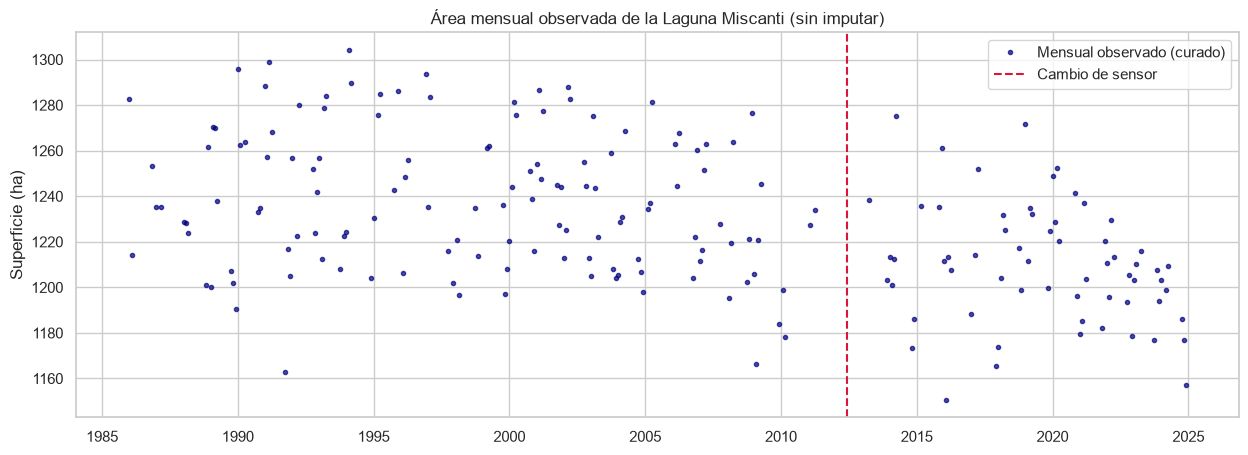

In [15]:
def anio_hidro(idx):
    """Año hidrológico: empieza en MES_INICIO_HIDRO y se nombra por el año calendario en que termina."""
    idx = pd.DatetimeIndex(idx)
    if MES_INICIO_HIDRO == 1:
        return pd.Index(idx.year)
    return pd.Index(idx.year + (idx.month >= MES_INICIO_HIDRO).astype(int))


# ---- Decisiones aplicadas a la serie (Miscanti)
if CORREGIR_SALTO_JRC:
    assert np.isfinite(DELTA_SALTO_JRC), "No hay desfase JRC estimado en 2.2"
    es_l8l9 = serie_curada.index > pd.Timestamp(QUIEBRE_SENSOR)
    serie_curada.loc[es_l8l9, COL_AREA] = serie_curada.loc[es_l8l9, COL_AREA] - DELTA_SALTO_JRC
    print(f"Salto corregido con JRC: se restan {DELTA_SALTO_JRC:+.1f} ha a las escenas L8/L9.")
serie_mensual = serie_curada[COL_AREA].resample("MS").mean()
serie_mensual = serie_mensual.where(serie_mensual.index.month.isin(MESES_USO))
print(f"Meses calendario usados: {sorted(MESES_USO)} | año hidrológico desde el mes {MES_INICIO_HIDRO}")


def construir_features(clima):
    """Precipitación, rezagos (1, 2 meses), acumulado 3 y 12 meses, temperaturas y estacionalidad cíclica."""
    out = clima[["precip", "tmax", "tmin"]].copy()
    out["p1"] = out["precip"].shift(1)
    out["p2"] = out["precip"].shift(2)
    out["p3"] = out["precip"].rolling(3).sum()
    out["p12"] = out["precip"].rolling(12).sum()
    out["mes_sin"] = np.sin(2 * np.pi * out.index.month / 12)   # seno/coseno: diciembre y enero quedan contiguos
    out["mes_cos"] = np.cos(2 * np.pi * out.index.month / 12)
    out["epoca"] = (out.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)   # 0 = L5/L7, 1 = L8/L9
    return out


def anomalia_sin_epoca(s):
    """Quita la media de cada época de sensor y luego el ciclo estacional. Deja la variación 'interna' de cada época."""
    epoca = (s.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
    s_adj = s - s.groupby(epoca).transform("mean")
    return s_adj - s_adj.groupby(s_adj.index.month).transform("mean")


def anomalia_estacional(s):
    """Resta la media de cada mes calendario (sin separar épocas)."""
    return s - s.groupby(s.index.month).transform("mean")


df_modelo = serie_mensual.to_frame(COL_AREA).join(construir_features(df_clima_ext), how="left")   # 2020-2024: ERA5-Land calibrado (hold-out)
mes = df_modelo.index.month                       # estacionalidad y época existen en TODO el periodo
df_modelo["mes_sin"], df_modelo["mes_cos"] = np.sin(2 * np.pi * mes / 12), np.cos(2 * np.pi * mes / 12)
df_modelo["epoca"] = (df_modelo.index > pd.Timestamp(QUIEBRE_SENSOR)).astype(int)
df_modelo["area_anom"] = anomalia_sin_epoca(df_modelo[COL_AREA])

n_obs = df_modelo[COL_AREA].notna().sum()
print(f"{len(df_modelo)} meses ({df_modelo.index.min().date()} → {df_modelo.index.max().date()}) | "
      f"{n_obs} con área observada ({n_obs / len(df_modelo):.0%}) | sin imputar")
obs_por_decada = df_modelo[COL_AREA].notna().groupby((df_modelo.index.year // 10) * 10).sum()
print("Meses con área observada por década:", obs_por_decada.to_dict())
n_con_clima = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA, "precip", "p3", "tmax", "tmin"]).shape[0]
print(f"Meses con área observada Y clima CR2MET: {n_con_clima}")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df_modelo.index, df_modelo[COL_AREA], ".", color="navy", alpha=0.7, label="Mensual observado (curado)")
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor")
ax.set(title="Área mensual observada de la Laguna Miscanti (sin imputar)", ylabel="Superficie (ha)")
ax.legend()
plt.show()

## 5. Variación neta, estacionalidad, quiebres y anomalías (preguntas 1 y 2)

Las variaciones anuales se calculan por **año hidrológico** (Miscanti) como **anomalía respecto de la climatología mensual** y solo para años con ≥ 3 meses observados; así un año con pocas escenas de verano no parece "más seco" solo por cuándo pasó el satélite. Los años siguientes a 2012 no se comparan con 2011 (hay un hueco de un año y un cambio de sensor).

Variación anual neta 2004-2023 por año hidrológico (años con ≥ 3 meses observados):


,area_media_obs,meses_obs,anom_ha,variacion_anom_ha,epoca
fecha,,,,,
2004,1229.32,7,1.21,-7.57,L5/L7
2005,1228.32,6,0.01,-1.20,L5/L7
2006,1258.44,3,19.07,19.06,L5/L7
2007,1232.75,7,4.64,-14.44,L5/L7
2008,1226.57,4,-7.98,-12.62,L5/L7
2009,1219.79,7,-8.32,-0.34,L5/L7
2010,1186.85,3,-41.65,-33.33,L5/L7
2014,1221.04,5,-11.53,NaN,L8/L9
2015,1198.40,3,-25.72,-14.19,L8/L9


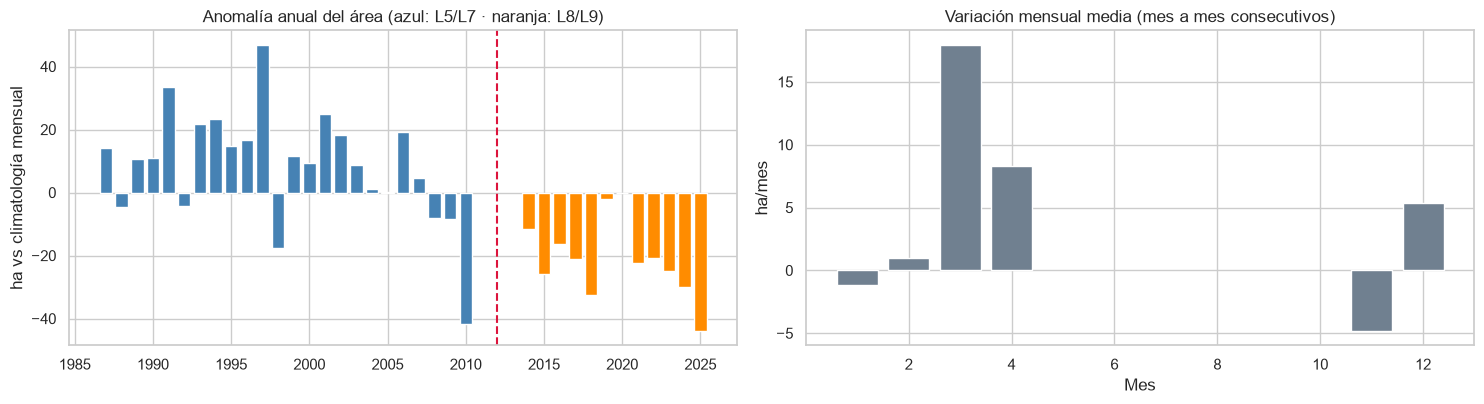

Pares de meses consecutivos usados por mes: {1: 22, 2: 23, 3: 25, 4: 26, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 17, 12: 20}


In [16]:
# ---- Variación neta anual (anomalía vs climatología mensual de toda la serie)
area = df_modelo[COL_AREA]
clim_mes = area.groupby(area.index.month).mean()
anom_clim = area - clim_mes.reindex(area.index.month).values
anual = pd.DataFrame({"area_media_obs": area.groupby(anio_hidro(area.index)).mean(),
                      "meses_obs": area.groupby(anio_hidro(area.index)).count(),
                      "anom_ha": anom_clim.groupby(anio_hidro(anom_clim.index)).mean()})   # Miscanti: año hidrológico
anual = anual[anual["meses_obs"] >= 3].copy()
consecutivo = anual.index.to_series().diff() == 1
anual["variacion_anom_ha"] = anual["anom_ha"].diff().where(consecutivo)
anual["epoca"] = np.where(anual.index > pd.Timestamp(QUIEBRE_SENSOR).year, "L8/L9", "L5/L7")

a, b = (int(x) for x in PERIODO_INFORME)
print(f"Variación anual neta {a}-{b} por año hidrológico (años con ≥ 3 meses observados):")
display(anual.loc[a:b].round(2))

# ---- Variación mensual neta (solo entre meses consecutivos con observación)
dif_mes = area.diff()
por_mes = dif_mes.groupby(dif_mes.index.month).agg(["mean", "count"]).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
colores = np.where(anual["epoca"] == "L8/L9", "darkorange", "steelblue")
axes[0].bar(anual.index, anual["anom_ha"], color=colores)
axes[0].axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--")
axes[0].set(title="Anomalía anual del área (azul: L5/L7 · naranja: L8/L9)", ylabel="ha vs climatología mensual")
axes[1].bar(por_mes.index, por_mes["mean"], color="slategray")
axes[1].set(title="Variación mensual media (mes a mes consecutivos)", xlabel="Mes", ylabel="ha/mes")
plt.tight_layout()
plt.show()
print("Pares de meses consecutivos usados por mes:", por_mes["count"].to_dict())

In [17]:
# ---- Tendencia (Kendall) y quiebre (Pettitt) sobre la anomalía anual
def pettitt(x):
    """Test de Pettitt: (posición del quiebre, estadístico K, p-valor aproximado)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    r = pd.Series(x).rank().values
    U = 2 * np.cumsum(r) - np.arange(1, n + 1) * (n + 1)
    K = np.abs(U).max()
    return int(np.abs(U).argmax()), K, min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))


def tendencia(serie, etiqueta):
    if len(serie) < 5:
        print(f"{etiqueta}: muestra insuficiente ({len(serie)} años)")
        return
    tau, p = kendalltau(serie.index, serie.values)
    pend = theilslopes(serie.values, serie.index)[0]
    print(f"{etiqueta:34s} n={len(serie):2d} años | tau={tau:+.2f} (p={p:.3f}) | pendiente Theil-Sen={pend:+.2f} ha/año")


tendencia(anual["anom_ha"], "Serie completa (mezcla sensores)")
tendencia(anual.loc[anual["epoca"] == "L5/L7", "anom_ha"], "Solo época L5/L7")
tendencia(anual.loc[anual["epoca"] == "L8/L9", "anom_ha"], "Solo época L8/L9")

t_q, K_q, p_q = pettitt(anual["anom_ha"].values)
anio_q = int(anual.index[t_q])
print(f"\nPettitt: quiebre tras {anio_q} (p ≈ {p_q:.4f}); anomalía media antes = {anual['anom_ha'].iloc[:t_q + 1].mean():+.1f} ha, "
      f"después = {anual['anom_ha'].iloc[t_q + 1:].mean():+.1f} ha")
if abs(anio_q - pd.Timestamp(QUIEBRE_SENSOR).year) <= 2:
    print("→ El quiebre estadístico COINCIDE con el cambio de sensor Landsat 5/7 → 8/9. Con estos datos no se puede afirmar que sea "
          "un cambio hidrológico; podría ser (en parte o del todo) un artefacto del sensor.")

Serie completa (mezcla sensores)   n=36 años | tau=-0.54 (p=0.000) | pendiente Theil-Sen=-1.44 ha/año
Solo época L5/L7                   n=24 años | tau=-0.28 (p=0.062) | pendiente Theil-Sen=-1.02 ha/año
Solo época L8/L9                   n=12 años | tau=-0.33 (p=0.153) | pendiente Theil-Sen=-1.58 ha/año

Pettitt: quiebre tras 2007 (p ≈ 0.0000); anomalía media antes = +12.6 ha, después = -20.6 ha


Kruskal-Wallis entre los 7 meses usados: H = 39.4, p = 0.0000 → hay estacionalidad estadísticamente detectable en el área.


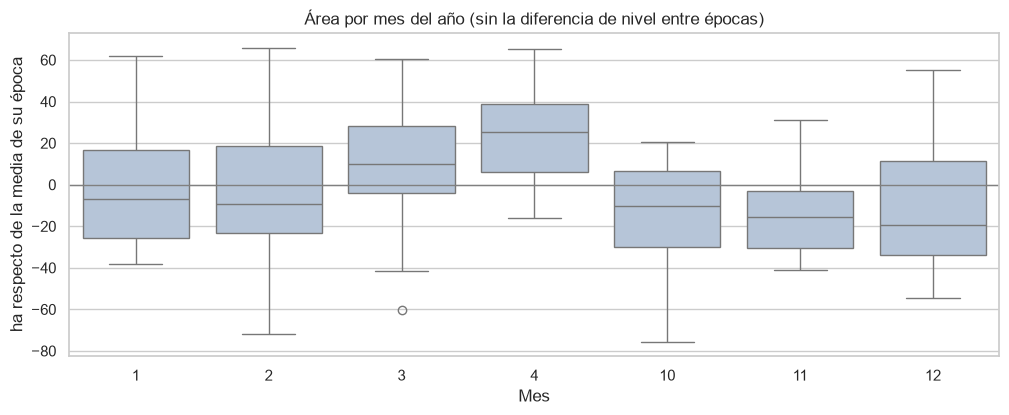


Meses con |anomalía| > 2.5σ (σ = 26.6 ha): 3
fecha
1994-02-01    69.7
2009-02-01   -68.2
2010-03-01   -71.4
Revisa estas fechas en GEE: pueden ser nube/sombra residual (error) o eventos reales.


In [18]:
# ---- Estacionalidad (sin el efecto de época) y anomalías
area_adj = area - area.groupby(df_modelo["epoca"]).transform("mean")
grupos = [g.dropna().values for _, g in area_adj.groupby(area_adj.index.month) if g.notna().any()]   # solo meses de MESES_USO
H, p_kw = kruskal(*grupos)
print(f"Kruskal-Wallis entre los {len(grupos)} meses usados: H = {H:.1f}, p = {p_kw:.4f} "
      f"→ {'hay' if p_kw < 0.05 else 'NO hay'} estacionalidad estadísticamente detectable en el área.")

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.boxplot(x=area_adj.dropna().index.month, y=area_adj.dropna().values, ax=ax, color="lightsteelblue")
ax.axhline(0, color="gray", lw=1)
ax.set(title="Área por mes del año (sin la diferencia de nivel entre épocas)", xlabel="Mes", ylabel="ha respecto de la media de su época")
plt.show()

# ---- Anomalías: meses que se alejan > 2.5 σ de lo esperado para su época y mes
an = df_modelo["area_anom"].dropna()
extremos = an[np.abs(an) > 2.5 * an.std()]
print(f"\nMeses con |anomalía| > 2.5σ (σ = {an.std():.1f} ha): {len(extremos)}")
print(extremos.round(1).to_string() if len(extremos) else "ninguno")
print("Revisa estas fechas en GEE: pueden ser nube/sombra residual (error) o eventos reales.")

## 6. Correlación con precipitación y temperatura (pregunta 3)

Tres versiones de la correlación de Spearman, de la más favorable a la más exigente:

1. **Cruda:** área vs clima. Inflada porque ambos tienen estacionalidad y porque el cambio de sensor crea una tendencia.
2. **Anomalía estacional:** se quita el ciclo mensual a ambas variables.
3. **Anomalía sin época:** además se quita la media de cada época de sensor al área. Esta es la que responde a "¿cuando llueve más que lo normal, la laguna es más grande que lo normal?".

`R² ≈ ρ²` da una idea de la fracción de la varianza explicada.

,rho_cruda,rho_anom_estacional,rho_anom_sin_epoca,p_anom_sin_epoca,n,R2_aprox
variable,,,,,,
precip,0.232,0.340,0.353,0.000,162,0.125
p1,0.199,0.110,0.108,0.172,162,0.012
p2,0.258,-0.022,-0.004,0.965,162,0.000
p3,0.337,0.172,0.226,0.004,162,0.051
p12,0.110,0.112,0.209,0.008,162,0.044
tmax,-0.186,-0.214,-0.113,0.152,162,0.013
tmin,0.060,0.025,0.106,0.179,162,0.011


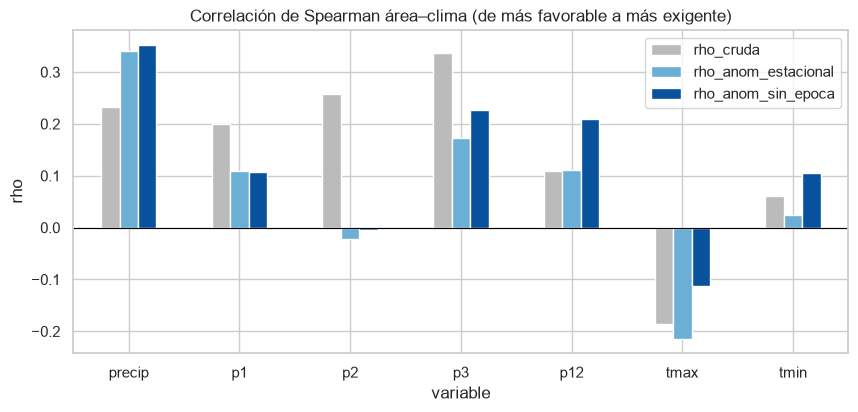

Mayor |rho| en la versión exigente: 0.35 → explica como máximo ≈ 12% de la variación (con 162 meses). Una correlación significativa pero tan baja no basta para predecir.


In [19]:
VARS_CORR = ["precip", "p1", "p2", "p3", "p12", "tmax", "tmin"]
clima_f = construir_features(df_clima)
clima_anom = clima_f[VARS_CORR].apply(anomalia_estacional)      # anomalías con TODA la historia de CR2MET (1979-2019)


def rho_par(a, b):
    par = pd.concat([a, b], axis=1).dropna()
    if len(par) < 10:
        return np.nan, np.nan, len(par)
    r, p = spearmanr(par.iloc[:, 0], par.iloc[:, 1])
    return r, p, len(par)


a_anom_est = anomalia_estacional(area)
filas = []
for v in VARS_CORR:
    r1, p1, n1 = rho_par(area, clima_f[v])
    r2, p2, n2 = rho_par(a_anom_est, clima_anom[v])
    r3, p3, n3 = rho_par(df_modelo["area_anom"], clima_anom[v])
    filas.append((v, r1, r2, r3, p3, n3, r3 ** 2))
tabla_corr = pd.DataFrame(filas, columns=["variable", "rho_cruda", "rho_anom_estacional", "rho_anom_sin_epoca",
                                          "p_anom_sin_epoca", "n", "R2_aprox"]).set_index("variable").round(3)
display(tabla_corr)

fig, ax = plt.subplots(figsize=(10, 4.2))
tabla_corr[["rho_cruda", "rho_anom_estacional", "rho_anom_sin_epoca"]].plot.bar(ax=ax, color=["#bbbbbb", "#6baed6", "#08519c"])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Correlación de Spearman área–clima (de más favorable a más exigente)", ylabel="rho")
plt.xticks(rotation=0)
plt.show()

RHO_MAX = tabla_corr["rho_anom_sin_epoca"].abs().max()
print(f"Mayor |rho| en la versión exigente: {RHO_MAX:.2f} → explica como máximo ≈ {RHO_MAX ** 2:.0%} de la variación "
      f"(con {int(tabla_corr['n'].max())} meses). Una correlación significativa pero tan baja no basta para predecir.")

## 7. Modelos de pronóstico con validación cruzada temporal (pregunta 5)

Se comparan modelos **clásicos** (referencias: media, climatología mensual, persistencia; regresión lineal regularizada Ridge) y de **ML** (Random Forest, XGBoost), cada uno con y sin clima, usando `TimeSeriesSplit` (siempre se entrena con el pasado). Métricas: RMSE y MAE en hectáreas, en bloques de prueba **fuera de la muestra**.

Se evalúan dos objetivos:

- **A. Nivel del área** (con la variable `epoca` para absorber el salto de sensor): lo que se necesita para proyectar.
- **B. Anomalía sin época ni estacionalidad**: aísla la señal del clima del salto de sensor.

La pregunta clave no es "¿qué modelo tiene menor error?", sino **¿algún modelo con clima le gana de forma clara a las referencias simples?** Si no, el pronóstico a largo plazo no tiene respaldo estadístico.

Como modelo estadístico clásico de series de tiempo se agrega **SARIMAX(1,0,0)** (ARIMA con regresores exógenos; maneja meses faltantes con el filtro de Kalman, sin imputar), con y sin clima, evaluado con los mismos pliegues. Se omiten Holt-Winters/ETS: no admiten huecos y la serie de área observada es irregular (meses faltantes, 2012 vacío); imputarla fue justamente lo que inflaba el desempeño anterior.

In [20]:
FEATS_BASE = ["mes_sin", "mes_cos", "epoca"]
FEATS_CLIMA = FEATS_BASE + ["precip", "p1", "p2", "p3", "tmax", "tmin"]
datos = df_modelo.loc[:FIN_CLIMA].dropna(subset=[COL_AREA] + FEATS_CLIMA).copy()
print(f"{len(datos)} meses con área observada y clima ({datos.index.min().date()} → {datos.index.max().date()})")

MODELOS = {
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 50, 100])),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=3,
                                           random_state=SEMILLA, n_jobs=-1),
}
if XGBRegressor is not None:
    MODELOS["XGBoost"] = XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                      colsample_bytree=0.8, random_state=SEMILLA)


def evaluar_cv(datos, objetivo, feats_base, feats_extra, etiqueta_extra="+ clima"):
    """Validación cruzada temporal (ventana expansiva). Devuelve (tabla de métricas, RMSE por pliegue, predicciones del último pliegue)."""
    y = datos[objetivo]
    N = len(datos)
    test = 24 if N >= 150 else 12
    n_splits = int(min(5, (N // 2) // test))
    assert n_splits >= 2, f"Muestra insuficiente para validación temporal (N={N})"
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test)

    pred = {
        "Media (referencia)": lambda tr, te: np.repeat(y.iloc[tr].mean(), len(te)),
        "Climatología mensual (referencia)": lambda tr, te: y.iloc[tr].groupby(y.index[tr].month).mean()
                                                .reindex(y.index[te].month).fillna(y.iloc[tr].mean()).values,
        "Persistencia: último valor observado (referencia)": lambda tr, te: np.repeat(y.iloc[tr].iloc[-1], len(te)),
    }
    for nombre, mod in MODELOS.items():
        for etiqueta, feats in (("estacionalidad", feats_base), (etiqueta_extra, feats_extra)):
            pred[f"{nombre} ({etiqueta})"] = (lambda tr, te, mod=mod, feats=feats:
                                              clone(mod).fit(datos[feats].iloc[tr], y.iloc[tr]).predict(datos[feats].iloc[te]))
    filas, por_pliegue, ultimo = {}, {}, {}
    for nombre, f in pred.items():
        rm, ma = [], []
        for tr, te in tscv.split(datos):
            p = np.asarray(f(tr, te))
            rm.append(np.sqrt(mean_squared_error(y.iloc[te], p)))
            ma.append(mean_absolute_error(y.iloc[te], p))
            ultimo[nombre] = (y.index[te], y.iloc[te].values, p)
        por_pliegue[nombre] = rm
        filas[nombre] = {"RMSE": np.mean(rm), "RMSE_std": np.std(rm), "MAE": np.mean(ma), "MAE_std": np.std(ma)}
    tabla = pd.DataFrame(filas).T.sort_values("RMSE")
    ref = tabla.loc["Climatología mensual (referencia)", "RMSE"]
    tabla["ganancia_vs_climatologia_%"] = (1 - tabla["RMSE"] / ref) * 100
    print(f"{n_splits} pliegues de {test} meses observados | objetivo: {objetivo}")
    return tabla.round(2), pd.DataFrame(por_pliegue), ultimo


def veredicto(tabla, sufijo="+ clima"):
    """¿El mejor modelo con clima supera a la mejor referencia por más que la variabilidad entre pliegues?"""
    refs = [i for i in tabla.index if "(referencia)" in i]
    con_clima = [i for i in tabla.index if sufijo in i]
    mejor_ref, mejor_cl = tabla.loc[refs, "RMSE"].idxmin(), tabla.loc[con_clima, "RMSE"].idxmin()
    ganancia = tabla.loc[mejor_ref, "RMSE"] - tabla.loc[mejor_cl, "RMSE"]
    ok = ganancia > tabla.loc[mejor_cl, "RMSE_std"]
    print(f"Mejor referencia: {mejor_ref} (RMSE {tabla.loc[mejor_ref, 'RMSE']:.2f} ha)")
    print(f"Mejor con {sufijo}: {mejor_cl} (RMSE {tabla.loc[mejor_cl, 'RMSE']:.2f} ± {tabla.loc[mejor_cl, 'RMSE_std']:.2f} ha)")
    print(f"Ganancia: {ganancia:+.2f} ha → " + ("supera a la referencia por más que la variabilidad entre pliegues."
          if ok else "NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues)."))
    # Ablación: mismo modelo con y sin clima. Es la prueba más limpia de si el clima aporta algo.
    abl = pd.DataFrame({m: {"RMSE sin clima": tabla.loc[f"{m} (estacionalidad)", "RMSE"],
                            "RMSE con clima": tabla.loc[f"{m} ({sufijo})", "RMSE"]}
                        for m in MODELOS if f"{m} ({sufijo})" in tabla.index}).T
    abl["aporte_clima_ha"] = abl["RMSE sin clima"] - abl["RMSE con clima"]
    print(f"Aporte de las variables '{sufijo}' con el mismo modelo (positivo = mejora):")
    display(abl.round(2))
    return ok, mejor_cl


print("=== A. Nivel del área (con época de sensor) ===")
print("Ojo: en A la 'ganancia vs climatología' viene sobre todo de la variable `epoca` (salto de sensor), no del clima;")
print("el aporte del clima se lee en la tabla de ablación (mismo modelo con y sin clima).")
tabla_A, pliegues_A, ultimo_A = evaluar_cv(datos, COL_AREA, FEATS_BASE, FEATS_CLIMA)
display(tabla_A)
CLIMA_AYUDA_A, MEJOR_A = veredicto(tabla_A)

print("\n=== B. Anomalía sin época ni estacionalidad ===")
tabla_B, pliegues_B, ultimo_B = evaluar_cv(datos, "area_anom", ["mes_sin", "mes_cos"],
                                           ["mes_sin", "mes_cos", "precip", "p1", "p2", "p3", "tmax", "tmin"])
display(tabla_B)
CLIMA_AYUDA_B, MEJOR_B = veredicto(tabla_B)

162 meses con área observada y clima (1986-01-01 → 2019-12-01)
=== A. Nivel del área (con época de sensor) ===
Ojo: en A la 'ganancia vs climatología' viene sobre todo de la variable `epoca` (salto de sensor), no del clima;
el aporte del clima se lee en la tabla de ablación (mismo modelo con y sin clima).


3 pliegues de 24 meses observados | objetivo: area_hectareas


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Ridge (+ clima),29.10,5.74,24.60,4.66,11.52
Ridge (estacionalidad),30.10,6.39,24.61,5.38,8.48
XGBoost (+ clima),30.15,3.02,24.40,2.50,8.31
XGBoost (estacionalidad),30.87,6.12,25.70,5.00,6.14
Random Forest (+ clima),31.45,5.13,26.68,3.59,4.38
Random Forest (estacionalidad),31.45,6.24,26.40,4.96,4.36
Climatología mensual (referencia),32.89,6.78,27.95,5.46,0.00
Media (referencia),33.42,4.96,28.09,3.78,-1.62
Persistencia: último valor observado (referencia),47.87,2.27,41.93,2.05,-45.55


Mejor referencia: Climatología mensual (referencia) (RMSE 32.89 ha)
Mejor con + clima: Ridge (+ clima) (RMSE 29.10 ± 5.74 ha)
Ganancia: +3.79 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,30.10,29.10,1.00
Random Forest,31.45,31.45,0.00
XGBoost,30.87,30.15,0.72



=== B. Anomalía sin época ni estacionalidad ===


3 pliegues de 24 meses observados | objetivo: area_anom


,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
Random Forest (+ clima),27.21,1.96,22.53,0.48,5.87
Ridge (+ clima),27.48,4.15,21.78,2.39,4.96
Media (referencia),27.98,4.07,22.00,2.38,3.21
Ridge (estacionalidad),28.28,4.23,22.35,2.57,2.19
XGBoost (estacionalidad),28.73,4.70,22.83,2.85,0.61
XGBoost (+ clima),28.78,0.86,23.70,0.31,0.45
Random Forest (estacionalidad),28.84,4.79,22.92,2.94,0.23
Climatología mensual (referencia),28.91,4.80,22.98,2.95,0.00
Persistencia: último valor observado (referencia),40.35,7.82,34.13,9.49,-39.56


Mejor referencia: Media (referencia) (RMSE 27.98 ha)
Mejor con + clima: Random Forest (+ clima) (RMSE 27.21 ± 1.96 ha)
Ganancia: +0.77 ha → NO supera claramente a la referencia (la diferencia está dentro del ruido entre pliegues).
Aporte de las variables '+ clima' con el mismo modelo (positivo = mejora):


,RMSE sin clima,RMSE con clima,aporte_clima_ha
Ridge,28.28,27.48,0.80
Random Forest,28.84,27.21,1.63
XGBoost,28.73,28.78,-0.05


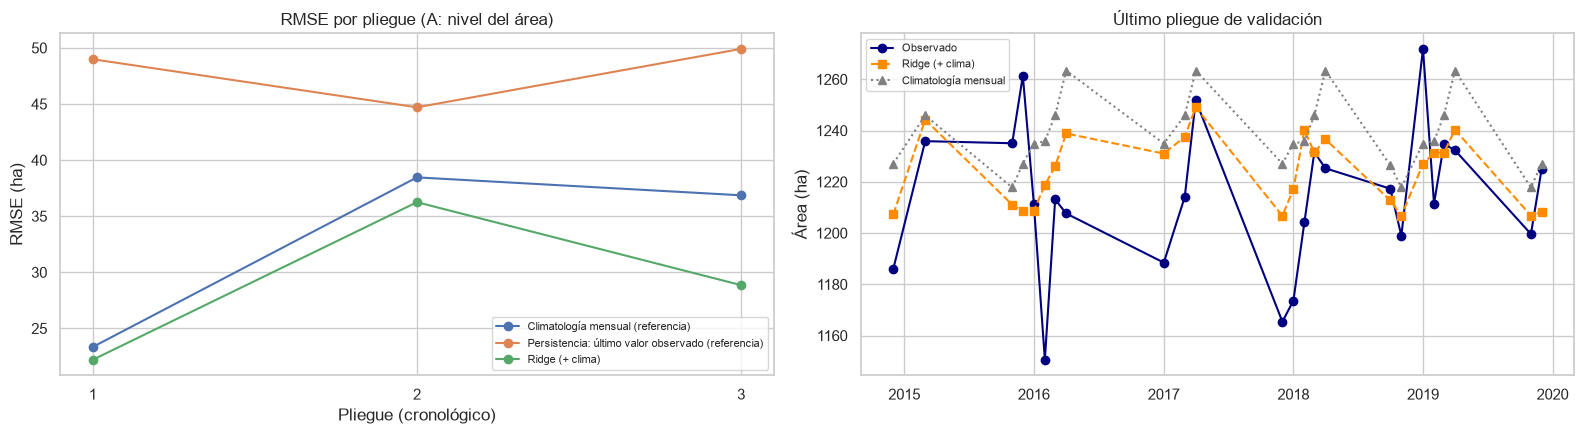

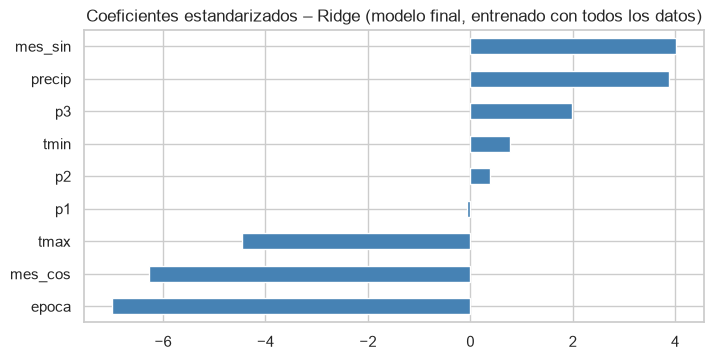

Modelo final: Ridge | RMSE de validación cruzada: 29.10 ha


In [21]:
# ---- Error por pliegue (¿es estable el resultado?) y último pliegue
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
seleccion = ["Climatología mensual (referencia)", "Persistencia: último valor observado (referencia)", MEJOR_A]
for nombre in seleccion:
    axes[0].plot(range(1, len(pliegues_A) + 1), pliegues_A[nombre], "o-", label=nombre)
axes[0].set(title="RMSE por pliegue (A: nivel del área)", xlabel="Pliegue (cronológico)", ylabel="RMSE (ha)")
axes[0].set_xticks(range(1, len(pliegues_A) + 1))
axes[0].legend(fontsize=8)

fechas_u, real_u, pred_u = ultimo_A[MEJOR_A]
_, _, pred_clim = ultimo_A["Climatología mensual (referencia)"]
axes[1].plot(fechas_u, real_u, "o-", color="navy", label="Observado")
axes[1].plot(fechas_u, pred_u, "s--", color="darkorange", label=MEJOR_A)
axes[1].plot(fechas_u, pred_clim, "^:", color="gray", label="Climatología mensual")
axes[1].set(title="Último pliegue de validación", ylabel="Área (ha)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ---- Modelo final (nivel del área, con clima) y qué variables usa
nombre_modelo = MEJOR_A.split(" (")[0]
FEATS_FINAL = FEATS_CLIMA
modelo_final = clone(MODELOS[nombre_modelo]).fit(datos[FEATS_FINAL], datos[COL_AREA])
RMSE_CV_FINAL = tabla_A.loc[MEJOR_A, "RMSE"]
estimador = modelo_final[-1] if hasattr(modelo_final, "steps") else modelo_final
if hasattr(estimador, "coef_"):
    imp, titulo = pd.Series(estimador.coef_, index=FEATS_FINAL), "Coeficientes estandarizados"
else:
    imp, titulo = pd.Series(estimador.feature_importances_, index=FEATS_FINAL), "Importancia de variables"
fig, ax = plt.subplots(figsize=(8, 3.8))
imp.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title(f"{titulo} – {nombre_modelo} (modelo final, entrenado con todos los datos)")
plt.show()
print(f"Modelo final: {nombre_modelo} | RMSE de validación cruzada: {RMSE_CV_FINAL:.2f} ha")

### 7b. Modelo estadístico clásico: SARIMAX

Misma validación cruzada (mismos pliegues y mismo horizonte): se ajusta con el pasado y se pronostica todo el bloque de prueba **sin ver ningún dato de ese bloque**. Los regresores exógenos son los mismos que en Ridge/RF/XGBoost (estacionalidad + época, con o sin clima).

In [22]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore", module="statsmodels")   # avisos de frecuencia/convergencia, esperables con huecos

def cv_sarimax(datos, grid, exog_cols, order=(1, 0, 0)):
    """RMSE/MAE por pliegue de un SARIMAX ajustado sobre la grilla mensual completa (huecos = NaN, sin imputar)."""
    N = len(datos)
    test = 24 if N >= 150 else 12
    tscv = TimeSeriesSplit(n_splits=int(min(5, (N // 2) // test)), test_size=test)
    rm, ma = [], []
    for tr, te in tscv.split(datos):
        t0, t1 = datos.index[tr[-1]], datos.index[te[-1]]
        g = grid.loc[:t1]
        y = g[COL_AREA].copy()
        y[g.index > t0] = np.nan                                    # el bloque de prueba queda oculto
        ex = g[exog_cols].astype(float)
        ex = (ex - ex.loc[:t0].mean()) / ex.loc[:t0].std().replace(0, 1)
        res = SARIMAX(y, exog=ex, order=order, enforce_stationarity=False,
                      enforce_invertibility=False).fit(disp=False, maxiter=200)
        futuro = g.index > t0
        p = res.get_prediction(start=g.index[futuro][0], end=t1, exog=ex.loc[futuro]).predicted_mean
        p = p.reindex(datos.index[te]).values
        rm.append(np.sqrt(mean_squared_error(datos[COL_AREA].iloc[te], p)))
        ma.append(mean_absolute_error(datos[COL_AREA].iloc[te], p))
    return {"RMSE": np.mean(rm), "RMSE_std": np.std(rm), "MAE": np.mean(ma), "MAE_std": np.std(ma)}


grid_clima = df_modelo.loc[:FIN_CLIMA]
tabla_sarimax = pd.DataFrame({
    "SARIMAX(1,0,0) (estacionalidad)": cv_sarimax(datos, grid_clima, FEATS_BASE),
    "SARIMAX(1,0,0) (+ clima)": cv_sarimax(datos, grid_clima, FEATS_CLIMA),
}).T
ref = tabla_A.loc["Climatología mensual (referencia)", "RMSE"]
tabla_sarimax["ganancia_vs_climatologia_%"] = (1 - tabla_sarimax["RMSE"] / ref) * 100
display(tabla_sarimax.round(2))
mejor_nosarimax = tabla_A["RMSE"].min()
print(f"Mejor modelo de la tabla A: {tabla_A['RMSE'].idxmin()} (RMSE {mejor_nosarimax:.2f} ha). "
      f"SARIMAX: {tabla_sarimax['RMSE'].min():.2f} ha → "
      + ("no mejora a los demás." if tabla_sarimax["RMSE"].min() >= mejor_nosarimax - tabla_A.loc[tabla_A['RMSE'].idxmin(), 'RMSE_std']
         else "mejora de forma clara."))

,RMSE,RMSE_std,MAE,MAE_std,ganancia_vs_climatologia_%
"SARIMAX(1,0,0) (estacionalidad)",38.85,9.4,32.33,9.31,-18.13
"SARIMAX(1,0,0) (+ clima)",345.65,324.5,298.47,284.26,-950.92


Mejor modelo de la tabla A: Ridge (+ clima) (RMSE 29.10 ha). SARIMAX: 38.85 ha → no mejora a los demás.


### 7c. ¿Está identificada `epoca` en cada pliegue? Diebold-Mariano y bootstrap pareado

Mismos pliegues que la sección 7 (objetivo A), con el mejor modelo de la tabla A, con y sin clima, frente a las referencias. Para cada comparación se informa:

- **Diebold-Mariano con la corrección de Harvey-Leybourne-Newbold** (pérdida cuadrática). Con `h = 1` es comparable con la cifra de la Torca (p = 0.60 y 0.73). Con `h = 12` se tratan los errores de un mismo bloque de prueba como autocorrelacionados, porque son pronósticos a 1-24 meses: es más conservador.
- **Bootstrap pareado por bloques de 12 meses** del RMSE(referencia) − RMSE(modelo). Si el intervalo incluye el cero, no hay mejora demostrable.
- **Pliegues con `epoca` no identificada**: prueba con meses L8/L9 sin ninguno en el entrenamiento. En la Torca era el pliegue 2. La comparación se repite sin esos pliegues.

**Criterio del veredicto.** El clima aporta solo si el modelo con clima le gana **a la mejor referencia y al mismo modelo sin clima**: p (h = 1) < 0.05 y un intervalo de bootstrap que excluya el cero en las dos comparaciones. Ganarle solo a la climatología no basta, porque esa ventaja puede venir de `epoca` y de la estacionalidad, que el modelo sin clima también tiene.

In [23]:
# ---- 7c. Identificación de `epoca` por pliegue, Diebold-Mariano (HLN) y bootstrap pareado por bloques
from scipy import stats as st


def dm_hln(e1, e2, h=1):
    """Diebold-Mariano con corrección de Harvey-Leybourne-Newbold (pérdida cuadrática). Estadístico negativo = e1 tiene
    menor error. Con h > 1 se suman las autocovarianzas hasta h − 1 (si la varianza resulta ≤ 0 se usa h = 1)."""
    d = np.asarray(e1, dtype=float) ** 2 - np.asarray(e2, dtype=float) ** 2
    n = len(d)
    gam = [np.cov(d[k:], d[:n - k])[0, 1] if k else d.var() for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    if var <= 0:
        h, var = 1, gam[0] / n
    stat = d.mean() / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * st.t.sf(abs(stat), n - 1)


def bootstrap_bloques(e_ref, e_mod, bloque=12, n_boot=5000):
    """IC 95 % de RMSE(referencia) − RMSE(modelo), remuestreando bloques de `bloque` errores consecutivos (pareado)."""
    e_ref, e_mod = np.asarray(e_ref, dtype=float), np.asarray(e_mod, dtype=float)
    n = len(e_ref)
    bloque = min(bloque, n)
    rng = np.random.default_rng(SEMILLA)
    dif = []
    for _ in range(n_boot):
        ini = rng.integers(0, n - bloque + 1, size=int(np.ceil(n / bloque)))
        idx = np.concatenate([np.arange(i, i + bloque) for i in ini])[:n]
        dif.append(np.sqrt(np.mean(e_ref[idx] ** 2)) - np.sqrt(np.mean(e_mod[idx] ** 2)))
    return np.percentile(dif, [2.5, 97.5])


def errores_cv(datos, objetivo, modelo, feats_base, feats_clima):
    """Errores por observación con los mismos pliegues de `evaluar_cv`, y la tabla de identificación de `epoca` por pliegue."""
    y = datos[objetivo]
    N = len(datos)
    test = 24 if N >= 150 else 12
    tscv = TimeSeriesSplit(n_splits=int(min(5, (N // 2) // test)), test_size=test)
    errores, pliegues = [], []
    for k, (tr, te) in enumerate(tscv.split(datos), 1):
        yt = y.iloc[te].values
        clim = y.iloc[tr].groupby(y.index[tr].month).mean().reindex(y.index[te].month).fillna(y.iloc[tr].mean()).values
        e = pd.DataFrame({
            "sin_clima": yt - clone(modelo).fit(datos[feats_base].iloc[tr], y.iloc[tr]).predict(datos[feats_base].iloc[te]),
            "con_clima": yt - clone(modelo).fit(datos[feats_clima].iloc[tr], y.iloc[tr]).predict(datos[feats_clima].iloc[te]),
            "persistencia": yt - y.iloc[tr].iloc[-1],
            "climatologia": yt - clim,
            "media": yt - y.iloc[tr].mean(),
        }, index=datos.index[te])
        e["pliegue"] = k
        errores.append(e)
        ep_tr, ep_te = int(datos["epoca"].iloc[tr].sum()), int(datos["epoca"].iloc[te].sum())
        pliegues.append({"pliegue": k, "entrenamiento": f"{datos.index[tr[0]]:%Y-%m} → {datos.index[tr[-1]]:%Y-%m}",
                         "prueba": f"{datos.index[te[0]]:%Y-%m} → {datos.index[te[-1]]:%Y-%m}",
                         "meses_L8L9_entren": ep_tr, "meses_L8L9_prueba": ep_te,
                         "epoca_identificada": not (ep_te > 0 and ep_tr == 0)})
    return pd.concat(errores), pd.DataFrame(pliegues).set_index("pliegue")


def tabla_dm_desde(E, etiqueta_modelo):
    rmse = (E[["sin_clima", "con_clima", "persistencia", "climatologia", "media"]] ** 2).mean() ** 0.5
    ref = rmse[["persistencia", "climatologia", "media"]].idxmin()
    filas = []
    for a, b in (("con_clima", ref), ("con_clima", "sin_clima"), ("sin_clima", ref)):
        s1, p1 = dm_hln(E[a], E[b], h=1)
        _, p12 = dm_hln(E[a], E[b], h=12)
        lo, hi = bootstrap_bloques(E[b], E[a])
        filas.append((f"{etiqueta_modelo} {a} vs {b}", rmse[a], rmse[b], s1, p1, p12, lo, hi, len(E)))
    return pd.DataFrame(filas, columns=["comparacion", "RMSE_a", "RMSE_b", "DM_HLN", "p_h1", "p_h12",
                                        "IC95_RMSEb_menos_RMSEa_inf", "IC95_RMSEb_menos_RMSEa_sup", "n"]).set_index("comparacion")


E7, pliegues_7c = errores_cv(datos, COL_AREA, MODELOS[nombre_modelo], FEATS_BASE, FEATS_CLIMA)
print("Pliegues de la sección 7 (objetivo A):")
display(pliegues_7c)
NO_IDENT_7 = pliegues_7c.index[~pliegues_7c["epoca_identificada"]].tolist()
print(f"Pliegues donde `epoca` NO está identificada (prueba con meses L8/L9 sin ninguno en el entrenamiento): {NO_IDENT_7 or 'ninguno'}")

tabla_dm = tabla_dm_desde(E7, nombre_modelo)
if NO_IDENT_7:
    tabla_dm = pd.concat([tabla_dm, tabla_dm_desde(E7[~E7["pliegue"].isin(NO_IDENT_7)], f"{nombre_modelo} [sin pliegues {NO_IDENT_7}]")])
display(tabla_dm.round(3))

def significativa(fila):
    return fila["p_h1"] < 0.05 and fila["IC95_RMSEb_menos_RMSEa_inf"] > 0


vs_ref, vs_sin = tabla_dm.iloc[0], tabla_dm.iloc[1]
# El clima aporta solo si el modelo con clima le gana a la mejor referencia Y al MISMO modelo sin clima: ganarle a la
# climatología puede deberse solo a `epoca` y la estacionalidad, que también tiene el modelo sin clima.
CLIMA_APORTA_7C = significativa(vs_ref) and significativa(vs_sin)
print(f"Con clima vs mejor referencia: p = {vs_ref['p_h1']:.3f} ({'significativa' if significativa(vs_ref) else 'no significativa'}) | "
      f"con clima vs el mismo modelo sin clima: p = {vs_sin['p_h1']:.3f} ({'significativa' if significativa(vs_sin) else 'no significativa'})")
print("→ " + ("el clima aporta capacidad de pronóstico mensual." if CLIMA_APORTA_7C else
              "el clima NO aporta de forma demostrable: lo que gana el modelo frente a la referencia lo gana igual sin clima "
              "(o no gana).")
      + " Criterio: p (h=1) < 0.05 y el IC del bootstrap por bloques excluye el cero. p_h12 es la versión más conservadora.")

Pliegues de la sección 7 (objetivo A):


,entrenamiento,prueba,meses_L8L9_entren,meses_L8L9_prueba,epoca_identificada
pliegue,,,,,
1,1986-01 → 2003-02,2003-03 → 2007-03,0,0,True
2,1986-01 → 2007-03,2007-04 → 2014-11,0,7,False
3,1986-01 → 2014-11,2014-12 → 2019-12,7,24,True


Pliegues donde `epoca` NO está identificada (prueba con meses L8/L9 sin ninguno en el entrenamiento): [2]


,RMSE_a,RMSE_b,DM_HLN,p_h1,p_h12,IC95_RMSEb_menos_RMSEa_inf,IC95_RMSEb_menos_RMSEa_sup,n
comparacion,,,,,,,,
Ridge con_clima vs climatologia,29.661,33.579,-3.221,0.002,0.082,1.169,6.967,72
Ridge con_clima vs sin_clima,29.661,30.770,-1.246,0.217,0.233,-1.386,2.460,72
Ridge sin_clima vs climatologia,30.770,33.579,-1.848,0.069,0.289,-0.308,8.167,72
Ridge [sin pliegues [2]] con_clima vs climatologia,25.743,30.852,-2.680,0.010,0.210,0.060,9.269,48
Ridge [sin pliegues [2]] con_clima vs sin_clima,25.743,25.917,-0.132,0.896,0.896,-3.111,1.301,48
Ridge [sin pliegues [2]] sin_clima vs climatologia,25.917,30.852,-1.943,0.058,0.240,-0.454,11.998,48


Con clima vs mejor referencia: p = 0.002 (significativa) | con clima vs el mismo modelo sin clima: p = 0.217 (no significativa)
→ el clima NO aporta de forma demostrable: lo que gana el modelo frente a la referencia lo gana igual sin clima (o no gana). Criterio: p (h=1) < 0.05 y el IC del bootstrap por bloques excluye el cero. p_h12 es la versión más conservadora.


### 7d. Hold-out 2020-2024

Los modelos se entrenan una sola vez con todos los meses 1985-2019 (clima CR2MET) y predicen los meses observados de 2020-2024 con el clima ERA5-Land calibrado (3.1). Nada de este periodo se usó antes para elegir modelos.

In [24]:
# ---- 7d. Hold-out 2020-2024: modelos entrenados con todo 1985-2019 (CR2MET), clima de prueba ERA5-Land calibrado
TABLA_HOLDOUT_M = None
hold = df_modelo.loc[FIN_CLIMA + pd.offsets.MonthBegin(1):FIN_CLIMA_EXT].dropna(subset=[COL_AREA] + FEATS_CLIMA)
if len(hold) < 6:
    print(f"Hold-out mensual: {len(hold)} meses con área y clima extendido; no se evalúa"
          + ("." if EXTENDER_CLIMA else " (EXTENDER_CLIMA = False)."))
else:
    y_tr = datos[COL_AREA]
    pred_h = {
        f"{nombre_modelo} (estacionalidad)": clone(MODELOS[nombre_modelo]).fit(datos[FEATS_BASE], y_tr).predict(hold[FEATS_BASE]),
        f"{nombre_modelo} (+ clima)": clone(MODELOS[nombre_modelo]).fit(datos[FEATS_CLIMA], y_tr).predict(hold[FEATS_CLIMA]),
        "Persistencia: último valor observado (referencia)": np.repeat(y_tr.iloc[-1], len(hold)),
        "Media de época L8/L9 (referencia)": np.repeat(y_tr[datos["epoca"] == 1].mean(), len(hold)),
        "Climatología mensual (referencia)": y_tr.groupby(y_tr.index.month).mean().reindex(hold.index.month).values,
    }
    E_h = pd.DataFrame({k: hold[COL_AREA].values - v for k, v in pred_h.items()}, index=hold.index)
    TABLA_HOLDOUT_M = pd.DataFrame({"RMSE": (E_h ** 2).mean() ** 0.5, "MAE": E_h.abs().mean(),
                                    "n_meses": E_h.count()}).sort_values("RMSE")
    display(TABLA_HOLDOUT_M.round(2))
    refs_h = [c for c in E_h.columns if "(referencia)" in c]
    ref_h = TABLA_HOLDOUT_M.loc[refs_h, "RMSE"].idxmin()
    s, p = dm_hln(E_h[f"{nombre_modelo} (+ clima)"], E_h[ref_h])
    lo, hi = bootstrap_bloques(E_h[ref_h], E_h[f"{nombre_modelo} (+ clima)"])
    print(f"Hold-out {hold.index.min():%Y-%m} → {hold.index.max():%Y-%m} ({len(hold)} meses): {nombre_modelo} (+ clima) vs {ref_h}: "
          f"DM-HLN {s:+.2f} (p = {p:.3f}); IC 95 % de RMSE_ref − RMSE_clima: {lo:+.2f} a {hi:+.2f} ha.")
    print("Recuerda: el clima de prueba viene de otro producto (ERA5-Land calibrado), así que un mal resultado puede deberse "
          "en parte al cambio de fuente.")

,RMSE,MAE,n_meses
Ridge (estacionalidad),22.30,18.95,31
Ridge (+ clima),22.39,19.35,31
Media de época L8/L9 (referencia),24.31,20.05,31
Persistencia: último valor observado (referencia),29.70,25.37,31
Climatología mensual (referencia),35.03,30.94,31


Hold-out 2020-01 → 2024-12 (31 meses): Ridge (+ clima) vs Media de época L8/L9 (referencia): DM-HLN -1.10 (p = 0.278); IC 95 % de RMSE_ref − RMSE_clima: -1.13 a +1.94 ha.
Recuerda: el clima de prueba viene de otro producto (ERA5-Land calibrado), así que un mal resultado puede deberse en parte al cambio de fuente.


## 8. Proyección 2025-2095 bajo RCP 2.6 y RCP 8.5 (análisis de sensibilidad)

Igual que en la Torca (código de la plantilla), con el **método delta por GCM**, emparejando las columnas por nombre:

- Temperatura: `clima = CR2MET(1986-2005) + (GCM escenario − GCM histórico 1986-2005)`.
- Precipitación: `clima = CR2MET(1986-2005) × (GCM escenario / GCM histórico 1986-2005)`, con el cociente acotado en [0, 3] y un piso de 1 en el denominador. Los archivos del CR2 vienen normalizados: el promedio de 1986-2005 es 100.
- **Corrida de control**: el mismo modelo con el clima constante de 1986-2005. La diferencia entre el escenario y el control es lo único atribuible al cambio climático según el modelo.

Cambios para Miscanti: solo se proyectan los meses de `MESES_USO`, y el promedio anual se calcula por **año hidrológico** completo. El modelo es el modelo final de la sección 7 (con clima y `epoca = 1`).

**Lectura obligada.** En la sección 7 el clima **no** aportó de forma demostrable: con vs sin clima dio p = 0.22. Estas curvas son un **análisis de sensibilidad** del modelo, no una predicción. Si la diferencia entre el escenario y el control es menor que el RMSE de validación, no se distingue del error del modelo.

RCP26: 21 GCMs proyectados


RCP85: 28 GCMs proyectados
RCP26: 0.0% de las predicciones mensuales caen fuera del rango observado (1151–1304 ha)
RCP85: 0.0% de las predicciones mensuales caen fuera del rango observado (1151–1304 ha)


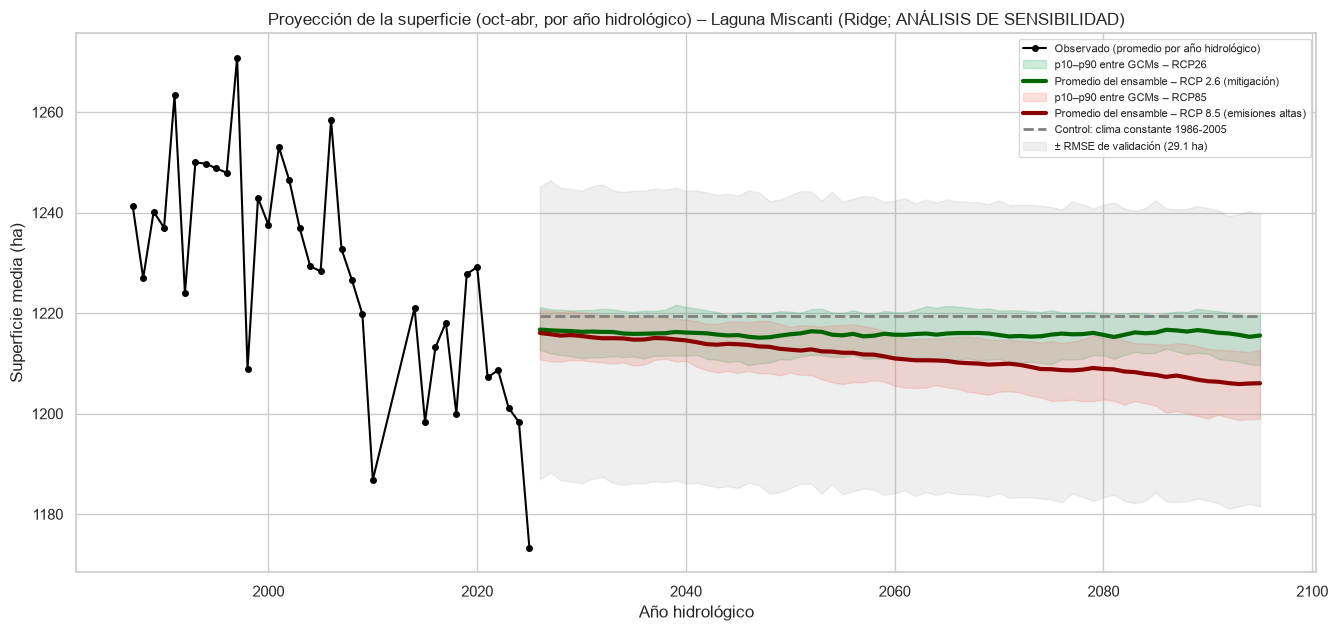

,escenario,horizonte,area_media_ha,p10_gcms,p90_gcms,efecto_vs_control_ha
0,RCP26,Corto plazo (2025-2040),1216.25,1214.36,1217.57,-3.22
1,RCP26,Mediano plazo (2041-2070),1215.79,1214.23,1217.78,-3.68
2,RCP26,Largo plazo (2071-2095),1215.86,1213.40,1217.83,-3.60
3,RCP85,Corto plazo (2025-2040),1215.17,1212.64,1216.90,-4.29
4,RCP85,Mediano plazo (2041-2070),1211.95,1208.13,1214.61,-7.51
5,RCP85,Largo plazo (2071-2095),1207.88,1202.87,1212.41,-11.58


escenario,RCP26,RCP85,RCP85 - RCP26 (ha)
horizonte,,,
Corto plazo (2025-2040),1216.25,1215.17,-1.08
Largo plazo (2071-2095),1215.86,1207.88,-7.98
Mediano plazo (2041-2070),1215.79,1211.95,-3.84


Para dimensionar: RMSE de validación = 29.1 ha. Un efecto del escenario menor que ese error no es distinguible del ruido del modelo.
ADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. Cualquier proyección es un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.


In [25]:
AYUDA_CLIMA = CLIMA_AYUDA_A or CLIMA_AYUDA_B
COLORES = {"rcp26": ("mediumseagreen", "darkgreen", "RCP 2.6 (mitigación)"),
           "rcp85": ("salmon", "darkred", "RCP 8.5 (emisiones altas)")}
resumen_proy, proy_anual, control_anual = None, None, None


def clima_gcm(gcm, escenario, desde=DESDE_LAGS):
    """Clima mensual (precip, tmax, tmin) de un GCM con el método delta, desde `desde` (igual que la plantilla)."""
    cols = {}
    for var in VARS_CLIMA:
        suf, df = SUFIJO_VAR[var], proy[var]
        ref = df[f"{gcm}_{suf} historical"].loc["1986":"2005"]
        ref_m = ref.groupby(ref.index.month).mean()
        ser = df[f"{gcm}_{suf} {escenario}"].loc[desde:]
        m = ser.index.month
        base = CLIM_BASE[var].reindex(m).values
        if var == "precip":
            cols[var] = pd.Series(base * np.clip(ser.values / np.maximum(ref_m.reindex(m).values, 1.0), 0, 3), index=ser.index)
        else:
            cols[var] = pd.Series(base + (ser.values - ref_m.reindex(m).values), index=ser.index)
    return pd.DataFrame(cols)


def anual_hidro(mensual):
    """Promedio por año hidrológico de los meses de MESES_USO; solo años con todos esos meses."""
    m = mensual[mensual.index.month.isin(MESES_USO)]
    g = m.groupby(anio_hidro(m.index))
    return g.mean()[g.count().min(axis=1) == len(MESES_USO)] if isinstance(m, pd.DataFrame) else g.mean()[g.count() == len(MESES_USO)]


if proy is None:
    print("Sección 8 omitida: faltan los CSV de proyecciones del CR2 para Miscanti (ver 3.2).")
else:
    def predecir(clima):
        X_fut = construir_features(clima).loc[INICIO_PROY:, FEATS_FINAL]
        return pd.Series(modelo_final.predict(X_fut), index=X_fut.index)

    proy_mensual = {}
    for esc in ("rcp26", "rcp85"):
        gcms = gcms_completos(esc)
        proy_mensual[esc] = pd.DataFrame({g: predecir(clima_gcm(g, esc)) for g in gcms})
        print(f"{esc.upper()}: {len(gcms)} GCMs proyectados")
    idx_largo = pd.date_range(DESDE_LAGS, proy_mensual["rcp85"].index.max(), freq="MS")
    clima_ctrl = pd.DataFrame({v: CLIM_BASE[v].reindex(idx_largo.month).values for v in VARS_CLIMA}, index=idx_largo)
    control_mensual = predecir(clima_ctrl)

    proy_anual = {esc: anual_hidro(df) for esc, df in proy_mensual.items()}
    control_anual = anual_hidro(control_mensual)
    ensamble = {esc: df.mean(axis=1) for esc, df in proy_anual.items()}
    o_min, o_max = datos[COL_AREA].min(), datos[COL_AREA].max()
    for esc, df in proy_mensual.items():
        df_u = df[df.index.month.isin(MESES_USO)]
        fuera = ((df_u < o_min) | (df_u > o_max)).to_numpy().mean()
        print(f"{esc.upper()}: {fuera:.1%} de las predicciones mensuales caen fuera del rango observado ({o_min:.0f}–{o_max:.0f} ha)")

    fig, ax = plt.subplots(figsize=(16, 7))
    hist = anual.loc[anual["meses_obs"] >= 3, "area_media_obs"]
    ax.plot(hist.index, hist.values, "o-", color="black", lw=1.5, ms=4, label="Observado (promedio por año hidrológico)")
    for esc, (c_fino, c_grueso, etiqueta) in COLORES.items():
        q10, q90 = proy_anual[esc].quantile(0.1, axis=1), proy_anual[esc].quantile(0.9, axis=1)
        ax.fill_between(q10.index, q10.rolling(5, center=True, min_periods=1).mean(), q90.rolling(5, center=True, min_periods=1).mean(),
                        color=c_fino, alpha=0.25, label=f"p10–p90 entre GCMs – {esc.upper()}")
        ax.plot(ensamble[esc].index, ensamble[esc].rolling(5, center=True, min_periods=1).mean(), color=c_grueso, lw=3,
                label=f"Promedio del ensamble – {etiqueta}")
    ax.plot(control_anual.index, control_anual.values, color="gray", ls="--", lw=2, label="Control: clima constante 1986-2005")
    ens_global = pd.concat(ensamble.values(), axis=1).mean(axis=1)
    ax.fill_between(ens_global.index, ens_global - RMSE_CV_FINAL, ens_global + RMSE_CV_FINAL, color="gray", alpha=0.12,
                    label=f"± RMSE de validación ({RMSE_CV_FINAL:.1f} ha)")
    ax.set(title=f"Proyección de la superficie (oct-abr, por año hidrológico) – Laguna Miscanti ({nombre_modelo}; ANÁLISIS DE SENSIBILIDAD)",
           xlabel="Año hidrológico", ylabel="Superficie media (ha)")
    ax.legend(loc="best", fontsize=8)
    plt.show()

    ULT = int(proy_anual["rcp85"].index.max())
    HORIZONTES = {"Corto plazo (2025-2040)": (2025, 2040), "Mediano plazo (2041-2070)": (2041, 2070),
                  f"Largo plazo (2071-{ULT})": (2071, ULT)}
    filas = []
    for esc in ("rcp26", "rcp85"):
        for nombre, (a, b) in HORIZONTES.items():
            medias_gcm = proy_anual[esc].loc[a:b].mean()
            ctrl = control_anual.loc[a:b].mean()
            filas.append((esc.upper(), nombre, medias_gcm.mean(), medias_gcm.quantile(0.1), medias_gcm.quantile(0.9),
                          medias_gcm.mean() - ctrl))
    resumen_proy = pd.DataFrame(filas, columns=["escenario", "horizonte", "area_media_ha", "p10_gcms", "p90_gcms",
                                                "efecto_vs_control_ha"]).round(2)
    display(resumen_proy)
    dif = resumen_proy.pivot(index="horizonte", columns="escenario", values="area_media_ha")
    dif["RCP85 - RCP26 (ha)"] = dif["RCP85"] - dif["RCP26"]
    display(dif.round(2))
    print(f"Para dimensionar: RMSE de validación = {RMSE_CV_FINAL:.1f} ha. Un efecto del escenario menor que ese error "
          "no es distinguible del ruido del modelo.")
if not AYUDA_CLIMA:
    print("ADVERTENCIA: en la validación cruzada el clima no mejoró de forma clara sobre las referencias simples. "
          "Cualquier proyección es un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.")

## 11. Exportación y resumen

In [26]:
SUF = "miscanti_v1"          # todos los archivos llevan "miscanti": no se sobrescribe ningún CSV de la Torca
df_modelo.to_csv(DIR_PROC / f"base_mensual_{SUF}.csv")
anual.to_csv(DIR_PROC / f"variacion_anual_{SUF}.csv")
tabla_corr.to_csv(DIR_PROC / f"correlaciones_{SUF}.csv")
tabla_A.to_csv(DIR_PROC / f"cv_nivel_area_{SUF}.csv")
tabla_B.to_csv(DIR_PROC / f"cv_anomalias_{SUF}.csv")
tabla_sarimax.to_csv(DIR_PROC / f"cv_sarimax_{SUF}.csv")
pliegues_7c.to_csv(DIR_PROC / f"pliegues_epoca_{SUF}.csv")
tabla_dm.to_csv(DIR_PROC / f"dm_hln_mensual_{SUF}.csv")
if TABLA_HOLDOUT_M is not None:
    TABLA_HOLDOUT_M.to_csv(DIR_PROC / f"holdout_mensual_{SUF}.csv")
if resumen_proy is not None:
    resumen_proy.to_csv(DIR_PROC / f"resumen_proyecciones_{SUF}.csv", index=False)
    for esc, df in proy_anual.items():
        df.to_csv(DIR_PROC / f"proyeccion_anual_{esc}_{SUF}.csv")
    control_anual.rename("control").to_csv(DIR_PROC / f"proyeccion_anual_control_{SUF}.csv")
print("Archivos guardados en:", DIR_PROC.resolve())

print("\n===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN (MISCANTI) =====")
print(f"• Meses con área observada y clima: {len(datos)} | salto de nivel entre sensores: {SALTO_SENSOR_HA:+.1f} ha")
print(f"• Mayor |rho| área–clima (anomalías sin época): {RHO_MAX:.2f} (R² ≈ {RHO_MAX ** 2:.0%})")
print(f"• Nivel del área: mejor con clima = {MEJOR_A} → "
      f"{'supera' if CLIMA_AYUDA_A else 'no supera claramente'} a las referencias simples")
print(f"• Anomalías: mejor con clima = {MEJOR_B} → "
      f"{'supera' if CLIMA_AYUDA_B else 'no supera claramente'} a las referencias simples")
print(f"• Diebold-Mariano (HLN, h=1): {tabla_dm.index[0]} → p = {tabla_dm['p_h1'].iloc[0]:.3f}; "
      f"{tabla_dm.index[1]} → p = {tabla_dm['p_h1'].iloc[1]:.3f} → "
      + ("el clima aporta" if CLIMA_APORTA_7C else "el clima no aporta de forma demostrable"))
print(f"• Pliegues con `epoca` no identificada: {NO_IDENT_7 or 'ninguno'}")

Archivos guardados en: C:\Users\jp200\Escritorio\Predicción laguna torca\data\processed

===== RESUMEN AUTOMÁTICO DE ESTA EJECUCIÓN (MISCANTI) =====
• Meses con área observada y clima: 162 | salto de nivel entre sensores: -55.5 ha
• Mayor |rho| área–clima (anomalías sin época): 0.35 (R² ≈ 12%)
• Nivel del área: mejor con clima = Ridge (+ clima) → no supera claramente a las referencias simples
• Anomalías: mejor con clima = Random Forest (+ clima) → no supera claramente a las referencias simples
• Diebold-Mariano (HLN, h=1): Ridge con_clima vs climatologia → p = 0.002; Ridge con_clima vs sin_clima → p = 0.217 → el clima no aporta de forma demostrable
• Pliegues con `epoca` no identificada: [2]


## 12. Modelo anual con lluvia acumulada, SPEI y chequeos del sensor

Igual que en la Torca, salvo por los cambios propios de Miscanti:

| Cambio | Por qué | Subsección |
|---|---|---|
| La descarga extendida (armonización de Roy et al., vegetación, NDVI de la cuenca) es opcional; JRC se movió a 1.2 | La serie de 1.1 ya trae escala, máscara QA completa, MNDWI y fracción válida | 12.1 |
| Salto entre épocas por año hidrológico, con JRC v1.4 + extensión | Régimen altiplánico | 12.2 |
| Objetivos anuales definidos por ti (`OBJETIVOS_ANUALES`) y medidos por año hidrológico | El "mínimo de enero-abril" de la Torca coincide en Miscanti con la temporada de lluvias | 12.4 |
| DM-HLN y años con `epoca` no identificada | Misma exigencia que la sección 7 | 12.6 |
| Hold-out anual 2020-2024 | Prueba fuera de muestra real | 12.6b |
| Proyección | Pendiente de la fuente | 12.7 |

**SPEI.** Igual que en la Torca: Hargreaves (Tmax, Tmin y latitud) y versión no paramétrica (Gringorten) contra los 40 años de CR2MET. [Inferencia] Hargreaves no considera la altitud ni el viento, que en el altiplano dominan la evaporación. El SPEI de Miscanti es, por eso, una aproximación más gruesa que en la Torca.

### 12.1 Parámetros y descarga extendida (GEE)

Por cada escena Landsat se calcula, dentro del polígono de la laguna:

- **Agua NDWI y agua MNDWI** con reflectancias de Landsat 5/7 llevadas a la escala de Landsat 8 (coeficientes OLS de Roy et al., 2016). Si el salto de 2012 es un artefacto del sensor, en la serie armonizada debería achicarse.
- **Vegetación**: píxeles con NDVI > 0.2 que no son agua según MNDWI (como en el estudio de Malheur Lake).
- **Área válida**: hectáreas sin nube ni sombra. Las escenas con menos del 95 % del polígono válido se descartan.
- **NDVI de la cuenca**: NDVI medio en un anillo de 3 km alrededor de la laguna, como indicador de plantaciones y uso de suelo.

**Miscanti:** esta descarga es **opcional** (`DESCARGAR_EXTENDIDA = False`); la serie de la sección 1 ya trae factores de escala, máscara QA con los bits 0-5, fracción válida, NDWI y MNDWI. JRC se movió a la sección 1.2. La armonización de Roy et al. (2016) no está validada para Collection 2 ni para TM (ver auditoría): no se usa salvo que lo decidas.

In [27]:
from scipy.stats import norm

# ----------------------------- Parámetros de la sección 12 -----------------------------
DESCARGAR_EXTENDIDA = False     # True = baja desde GEE la serie extendida y JRC (una sola vez; después queda en caché)
FUENTE_AREA_12 = "auto"         # "auto" | "original" | "armonizada_ndwi" | "armonizada_mndwi" | "jrc"
# CORREGIR_L7 y DIAS_PAR se movieron a 2.2; MESES_VERANO se reemplazó por OBJETIVOS_ANUALES (sección 0)
VENTANAS_P = (12, 24, 36)       # lluvia acumulada (meses)
VENTANAS_SPEI = (12, 24)        # escalas del SPEI (meses)
BUFFER_CUENCA_M = 3000          # anillo alrededor de la laguna para el NDVI de la cuenca
# VALIDO_MIN se movió a la sección 0; CACHE_JRC y la descarga de JRC, a la sección 1.2
CACHE_EXT = "serie_laguna_miscanti_extendida.csv"

# Roy et al. (2016), OLS ETM+ → OLI en reflectancia de superficie: OLI = pendiente × ETM+ + intercepto.
# Para TM se usa la misma transformación (TM y ETM+ tienen bandas casi idénticas).
ROY = {"verde": (0.8483, 0.0088), "rojo": (0.9047, 0.0061), "nir": (0.8462, 0.0412), "swir1": (0.8937, 0.0254)}
NOMBRES_EXT = ["verde", "rojo", "nir", "swir1"]
BANDAS_EXT = {"LANDSAT/LT05/C02/T1_L2": ("SR_B2", "SR_B3", "SR_B4", "SR_B5"),
              "LANDSAT/LE07/C02/T1_L2": ("SR_B2", "SR_B3", "SR_B4", "SR_B5"),
              "LANDSAT/LC08/C02/T1_L2": ("SR_B3", "SR_B4", "SR_B5", "SR_B6"),
              "LANDSAT/LC09/C02/T1_L2": ("SR_B3", "SR_B4", "SR_B5", "SR_B6")}


def descargar_serie_extendida():
    """Una fila por escena: agua NDWI/MNDWI (armonizadas a OLI), vegetación, área válida y NDVI de la cuenca."""
    ee = iniciar_gee()
    geom = geometria(ee, CUERPO)
    anillo = geom.buffer(BUFFER_CUENCA_M).difference(geom, 1)
    px_ha = ee.Image.pixelArea().divide(1e4)
    pendiente = ee.Image.constant([ROY[b][0] for b in NOMBRES_EXT])
    intercepto = ee.Image.constant([ROY[b][1] for b in NOMBRES_EXT])
    poligono_ha = geom.area(1).getInfo() / 1e4

    def coleccion(id_coleccion, bandas):
        armonizar = "LC0" not in id_coleccion          # L5 y L7 se llevan a la escala de L8/L9

        def procesar(img):
            qa = img.select("QA_PIXEL")
            limpio = qa.bitwiseAnd(0b111111).eq(0)    # Miscanti: bits 0-5 (relleno, nube dilatada, cirrus, nube, sombra, nieve)
            sr = img.select(list(bandas), NOMBRES_EXT).multiply(0.0000275).add(-0.2)   # factor de escala de Collection 2
            if armonizar:
                sr = sr.multiply(pendiente).add(intercepto)
            sr = sr.updateMask(limpio)
            agua_m = sr.select("verde").gt(sr.select("swir1"))   # MNDWI > 0 sin enmascarar reflectancias negativas (ver 1.1)
            ndvi = sr.normalizedDifference(["nir", "rojo"])
            capas = ee.Image.cat([sr.select("verde").gt(sr.select("nir")).rename("ndwi_ha"),
                                  agua_m.rename("mndwi_ha"),
                                  ndvi.gt(0.2).And(agua_m.Not()).rename("veg_ha"),
                                  limpio.selfMask().rename("valido_ha")]).multiply(px_ha)
            suma = capas.reduceRegion(reducer=ee.Reducer.sum(), geometry=geom, scale=30, maxPixels=1e9)
            ndvi_cuenca = ndvi.reduceRegion(reducer=ee.Reducer.mean(), geometry=anillo, scale=30, maxPixels=1e9).get("nd")
            return ee.Feature(None, suma).set({"fecha": img.date().format("YYYY-MM-dd"),
                                               "satelite": img.get("SPACECRAFT_ID"), "ndvi_cuenca": ndvi_cuenca})

        return (ee.ImageCollection(id_coleccion).filterBounds(geom).filterDate(FECHA_INICIO, FECHA_FIN)
                .filter(ee.Filter.lt("CLOUD_COVER", NUBOSIDAD_MAX)).map(procesar))

    filas = []
    for id_coleccion, bandas in BANDAS_EXT.items():       # una consulta por misión: evita el límite de elementos de getInfo
        feats = coleccion(id_coleccion, bandas).getInfo()["features"]
        filas += [f["properties"] for f in feats]
        print(f"  {id_coleccion}: {len(feats)} escenas")
    df = pd.DataFrame(filas).reindex(columns=["fecha", "satelite", "ndwi_ha", "mndwi_ha", "veg_ha", "valido_ha", "ndvi_cuenca"])
    df["poligono_ha"] = poligono_ha
    return df


def cargar_o_descargar(nombre, funcion):
    ruta = buscar_archivo(nombre)
    if ruta is not None and not DESCARGAR_EXTENDIDA:
        print(f"{nombre}: cargado desde caché")
        df = pd.read_csv(ruta)
    elif DESCARGAR_EXTENDIDA:
        print(f"{nombre}: descargando desde Google Earth Engine...")
        df = funcion()
        df.to_csv(DIR_PROC / nombre, index=False)
    else:
        print(f"{nombre}: no está en data/processed. Con DESCARGAR_EXTENDIDA = True se baja desde GEE; se sigue sin él.")
        return None
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df.drop_duplicates().sort_values("fecha").reset_index(drop=True)


df_ext = cargar_o_descargar(CACHE_EXT, descargar_serie_extendida)
if df_ext is not None:
    print(f"Serie extendida: {len(df_ext)} escenas | {df_ext['fecha'].min().date()} → {df_ext['fecha'].max().date()}")
if df_jrc is not None:
    print(f"JRC: {len(df_jrc)} meses | {df_jrc['fecha'].min().date()} → {df_jrc['fecha'].max().date()}")

serie_laguna_miscanti_extendida.csv: no está en data/processed. Con DESCARGAR_EXTENDIDA = True se baja desde GEE; se sigue sin él.
JRC: 490 meses | 1984-03-01 → 2024-12-01


### 12.2 Chequeos del sensor: Landsat 7 vs Landsat 5 y salto de 2012 por fuente

**L7 vs L5.** Entre 1999 y 2003 vuelan los dos satélites. Cada escena válida de Landsat 7 se empareja con la escena válida de Landsat 5 más cercana (≤ 8 días). La laguna casi no cambia en una semana, así que la mediana de las diferencias estima el sesgo de L7. Si `CORREGIR_L7 = True` (parámetro en 2.2), ese sesgo se resta a todas las escenas L7 antes de armar la serie anual. Es importante porque 1999-2003 está dominado por L7: sin corregir, esos años parecen más secos de lo que fueron.

**Salto de 2012.** Para cada fuente disponible se calcula la diferencia de nivel entre épocas (L8/L9 − L5/L7) por año hidrológico, cruda y ajustada por la lluvia del año hidrológico (coeficiente de `epoca` en una regresión del área anual sobre `epoca` + lluvia de 12 meses). Si la serie armonizada o JRC muestran un salto mucho menor que la original, el salto era sobre todo del sensor.

[original] 25 pares L7–L5 (≤ 8 días): mediana L7 − L5 = +8.7 ha (IC 95 % bootstrap -4.3 a +31.2)


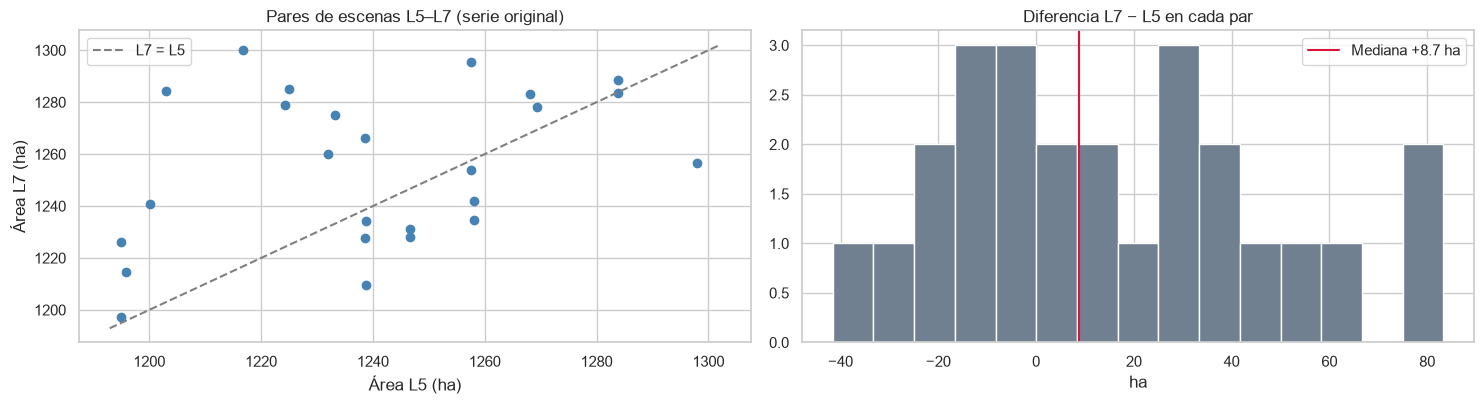

Salto entre épocas por fuente (L7 corregido donde hubo pares suficientes):


,años,media_L5L7_ha,media_L8L9_ha,salto_crudo_ha,salto_ajustado_lluvia_ha,sesgo_L7_vs_L5_ha
fuente,,,,,,
original,36,1236.75,1208.03,-28.72,-25.82,8.69
jrc,37,1288.73,1274.48,-14.25,-12.26,NaN


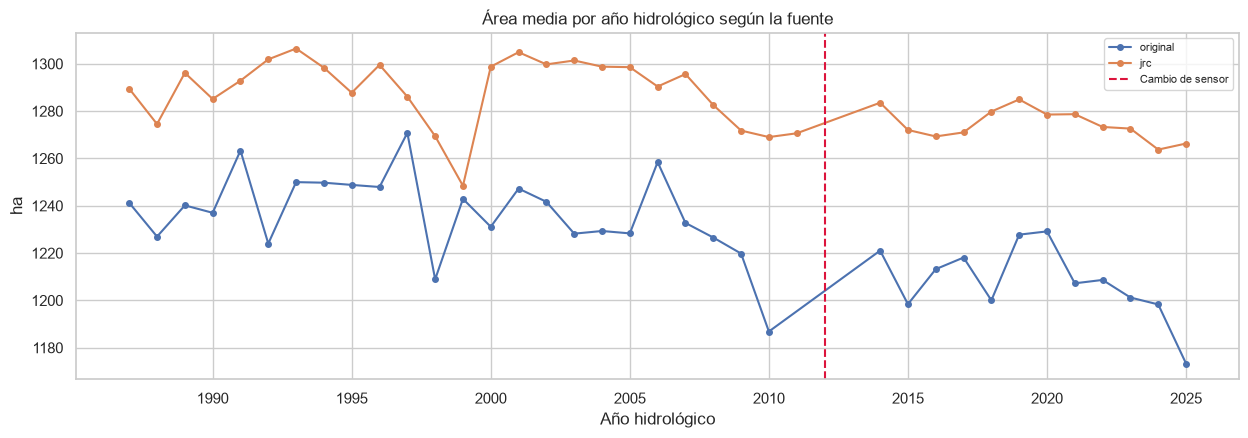

Fuente usada en el resto de la sección: original (con L7 corregido)


In [28]:
# ---- 12.2 Calibración Landsat 7 → Landsat 5 y salto entre épocas por fuente
# pares_l5_l7 y calibrar_l7 se definen en 2.2

# Series curadas (mismas 5 reglas de la sección 2) para cada fuente con escenas individuales
curadas_12 = {"original": serie_curada}
if df_ext is not None:
    valida = (df_ext["valido_ha"] / df_ext["poligono_ha"]) >= VALIDO_MIN
    for col, nombre in (("ndwi_ha", "armonizada_ndwi"), ("mndwi_ha", "armonizada_mndwi")):
        d = df_ext[["fecha", "satelite", col]].rename(columns={col: COL_AREA})
        d.loc[~valida, COL_AREA] = np.nan                  # escenas con nube dentro del polígono
        curadas_12[nombre], _ = curar_serie(d, AREA_MIN_HA, FECHAS_AUDITADAS)

mensual_12, sesgos_l7, pares_12 = {}, {}, {}
for nombre, curada in curadas_12.items():
    corregida, sesgos_l7[nombre], pares_12[nombre] = calibrar_l7(curada, nombre)
    mensual_12[nombre] = corregida[COL_AREA].resample("MS").mean()
if df_jrc is not None:
    j = df_jrc.set_index("fecha").sort_index()          # v1.4 (1984-2021) + extensión v1.5 (2022-2024)
    ok = (j["sin_dato_ha"] / j["poligono_ha"] < 0.05) & (j["agua_ha"] >= AREA_MIN_HA)
    mensual_12["jrc"] = j["agua_ha"].where(ok).resample("MS").mean()
    sesgos_l7["jrc"] = np.nan
mensual_12 = {k: m.where(m.index.month.isin(MESES_USO)) for k, m in mensual_12.items()}   # Miscanti: solo MESES_USO

p_orig = pares_12["original"]
if len(p_orig):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
    axes[0].scatter(p_orig["L5"], p_orig["L7"], color="steelblue")
    lim = [p_orig[["L5", "L7"]].min().min() - 2, p_orig[["L5", "L7"]].max().max() + 2]
    axes[0].plot(lim, lim, color="gray", ls="--", label="L7 = L5")
    axes[0].set(title="Pares de escenas L5–L7 (serie original)", xlabel="Área L5 (ha)", ylabel="Área L7 (ha)")
    axes[0].legend()
    axes[1].hist(p_orig["dif_L7_menos_L5"], bins=15, color="slategray")
    axes[1].axvline(sesgos_l7["original"], color="crimson", label=f"Mediana {sesgos_l7['original']:+.1f} ha")
    axes[1].set(title="Diferencia L7 − L5 en cada par", xlabel="ha")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

# ---- Salto entre épocas por fuente (área media anual, años con ≥ 3 meses observados)
lluvia_anual = df_clima["precip"].groupby(anio_hidro(df_clima.index)).sum()          # Miscanti: año hidrológico
lluvia_anual = lluvia_anual[df_clima["precip"].groupby(anio_hidro(df_clima.index)).count() == 12]
anuales_fuente, filas = {}, []
for nombre, m in mensual_12.items():
    a_ = m.groupby(anio_hidro(m.index)).mean().where(m.groupby(anio_hidro(m.index)).count() >= 3).dropna()
    anuales_fuente[nombre] = a_
    ep = (a_.index > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)
    salto_crudo = a_[ep == 1].mean() - a_[ep == 0].mean()
    d = pd.DataFrame({"area": a_, "epoca": ep, "P12": lluvia_anual.reindex(a_.index)}).dropna()
    salto_aj = LinearRegression().fit(d[["epoca", "P12"]], d["area"]).coef_[0] if d["epoca"].nunique() == 2 else np.nan
    filas.append((nombre, len(a_), a_[ep == 0].mean(), a_[ep == 1].mean(), salto_crudo, salto_aj, sesgos_l7[nombre]))
tabla_saltos = pd.DataFrame(filas, columns=["fuente", "años", "media_L5L7_ha", "media_L8L9_ha", "salto_crudo_ha",
                                            "salto_ajustado_lluvia_ha", "sesgo_L7_vs_L5_ha"]).set_index("fuente").round(2)
print("Salto entre épocas por fuente" + (" (L7 corregido donde hubo pares suficientes)" if CORREGIR_L7 else "") + ":")
display(tabla_saltos)

fig, ax = plt.subplots(figsize=(15, 4.5))
for nombre, a_ in anuales_fuente.items():
    ax.plot(a_.index, a_.values, "o-", ms=4, label=nombre)
ax.axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--", label="Cambio de sensor")
ax.set(title="Área media por año hidrológico según la fuente", xlabel="Año hidrológico", ylabel="ha")
ax.legend(fontsize=8)
plt.show()

if FUENTE_AREA_12 == "auto":
    FUENTE_12 = "armonizada_ndwi" if "armonizada_ndwi" in mensual_12 else "original"
else:
    assert FUENTE_AREA_12 in mensual_12, f"La fuente '{FUENTE_AREA_12}' no está disponible (falta su CSV de GEE)"
    FUENTE_12 = FUENTE_AREA_12
area_m12 = mensual_12[FUENTE_12]
L7_CORREGIDO_12 = CORREGIR_L7 and not np.isnan(sesgos_l7[FUENTE_12])
print(f"Fuente usada en el resto de la sección: {FUENTE_12}" + (" (con L7 corregido)" if L7_CORREGIDO_12 else ""))

### 12.3 Agua vs vegetación dentro del polígono

Si la vegetación emergente (totora, junquillo) avanza sobre el espejo de agua, el NDWI la cuenta como "no agua" aunque debajo haya agua. Entonces el área de agua cae sin que baje el nivel. Esta celda compara agua (MNDWI), vegetación y su suma:

- Una correlación **negativa fuerte** entre las anomalías de agua y de vegetación indica que gran parte de la variación del "agua" es vegetación que la cubre o la descubre.
- Si **agua + vegetación** varía mucho menos que el agua sola, la laguna ocupa una cubeta casi fija, y lo que se mueve es la cobertura vegetal y no el nivel.
- Se compara también la correlación de cada serie con la lluvia de 12 meses (anual, sin época).

Necesita la serie extendida de 12.1. Se usan las escenas con ≥ 95 % del polígono sin nube y sin Landsat 7 SLC-off.

In [29]:
# ---- 12.3 Agua vs vegetación
tabla_veg = None
if df_ext is None:
    print("Sin la serie extendida de GEE (12.1) no se puede separar agua de vegetación. Se omite 12.3.")
else:
    e = df_ext.set_index("fecha")
    ok = ((e["valido_ha"] / e["poligono_ha"]) >= VALIDO_MIN) & ~(e["satelite"].str.contains("LANDSAT_7", na=False)
                                                                 & (e.index > FALLA_SLC_L7))
    veg_m = e.loc[ok, ["mndwi_ha", "veg_ha"]].resample("MS").mean().dropna()
    veg_m = veg_m[veg_m.index.month.isin(MESES_USO)]
    veg_m["agua_mas_veg_ha"] = veg_m["mndwi_ha"] + veg_m["veg_ha"]

    filas = []
    anom_veg = {c: anomalia_sin_epoca(veg_m[c]) for c in veg_m.columns}
    for c in veg_m.columns:
        a_ = veg_m[c].groupby(anio_hidro(veg_m.index)).mean().where(veg_m[c].groupby(anio_hidro(veg_m.index)).count() >= 3).dropna()
        a_res = a_ - a_.groupby((a_.index > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)).transform("mean")
        r, p, n = rho_par(a_res, lluvia_anual)
        filas.append((c, veg_m[c].mean(), anom_veg[c].std(), r, p, n))
    tabla_veg = pd.DataFrame(filas, columns=["serie", "media_ha", "desv_anomalia_mensual_ha", "rho_anual_con_P12",
                                             "p", "n_años"]).set_index("serie").round(3)
    display(tabla_veg)
    r_av, p_av, n_av = rho_par(anom_veg["mndwi_ha"], anom_veg["veg_ha"])
    print(f"Correlación de Spearman entre anomalías mensuales de agua y de vegetación: rho = {r_av:+.2f} (p = {p_av:.3f}, n = {n_av})")
    ratio = tabla_veg.loc["agua_mas_veg_ha", "desv_anomalia_mensual_ha"] / tabla_veg.loc["mndwi_ha", "desv_anomalia_mensual_ha"]
    print(f"Variabilidad de agua + vegetación respecto del agua sola: {ratio:.2f} "
          + ("→ la suma es bastante más estable: lo que se mueve es sobre todo la cobertura vegetal."
             if ratio < 0.7 else "→ la suma varía casi tanto como el agua: la vegetación no explica la variación."))

    fig, ax = plt.subplots(figsize=(15, 4.5))
    for c, color in (("mndwi_ha", "royalblue"), ("veg_ha", "forestgreen"), ("agua_mas_veg_ha", "black")):
        ax.plot(veg_m.index, veg_m[c], ".", ms=4, color=color, alpha=0.7, label=c)
    ax.axvline(pd.Timestamp(QUIEBRE_SENSOR), color="crimson", ls="--", label="Cambio de sensor")
    ax.set(title="Agua (MNDWI), vegetación (NDVI > 0.2 y no agua) y su suma dentro del polígono", ylabel="ha")
    ax.legend(fontsize=8)
    plt.show()

Sin la serie extendida de GEE (12.1) no se puede separar agua de vegetación. Se omite 12.3.


### 12.4 Serie anual y predictores de escala larga (objetivos por año hidrológico)

En la Torca, `min_verano` (mínimo de enero-abril, clima al 31-dic del año anterior) medía el fin de la estación seca mediterránea. **En Miscanti, enero-marzo es la temporada de lluvias**: copiarlo no tiene sentido. Cada objetivo se define en `OBJETIVOS_ANUALES` (sección 0) con:

- `meses`: meses calendario del objetivo;
- `agregacion`: `"min"`, `"max"` o `"mean"`;
- `mes_corte`: los predictores (P12/P24/P36 y SPEI-12/24) se toman al cierre de ese mes, dentro del mismo año hidrológico;
- `min_meses` (opcional): meses observados mínimos (1 por defecto).

**Decisión del 2026-11-08** (evidencia en 2.1 y 3, con `MESES_USO` = octubre a abril y año hidrológico julio-junio):

| Objetivo | Definición | Clima al cierre de |
|---|---|---|
| `min_pre_lluvia` | Mínimo mensual de oct-dic | 30 de septiembre (pronóstico) |
| `max_post_lluvia` | Máximo mensual de mar-abr | 28 de febrero, cuando ya cayó el 59 % de la lluvia anual (pronóstico) |
| `media_temporada` | Media de oct-abr (≥ 3 meses) | 30 de abril (concurrente, como `media_anual` en la Torca) |

[Inferencia] Los objetivos son amplios a propósito y no se ajustan al pico del NDWI (abril-junio), porque JRC no confirma ese ciclo estacional (2.1). `max_post_lluvia` mide la respuesta directa a la temporada de lluvias. `min_pre_lluvia` mide el balance acumulado: la lluvia de años anteriores menos la evaporación.

Otras variables: `Tx` (Tmax media de los meses del objetivo, demanda evaporativa) y `ndvi_cuenca` si existe la serie extendida. `epoca` absorbe el salto de sensor en todos los modelos.

In [30]:
# ---- 12.4 Evapotranspiración, SPEI y tabla anual
def radiacion_extraterrestre(fechas, lat=LAT_LAGUNA):
    """Ra (MJ m-2 día-1) al día 15 de cada mes, FAO-56 ec. 21."""
    j = (fechas + pd.Timedelta(days=14)).dayofyear.values
    phi = np.radians(lat)
    dr = 1 + 0.033 * np.cos(2 * np.pi * j / 365)
    decl = 0.409 * np.sin(2 * np.pi * j / 365 - 1.39)
    ws = np.arccos(-np.tan(phi) * np.tan(decl))
    return 24 * 60 / np.pi * 0.0820 * dr * (ws * np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.sin(ws))


def pet_hargreaves(clima):
    """Evapotranspiración potencial mensual (mm) de Hargreaves-Samani: solo usa Tmax, Tmin y la latitud."""
    tmedia = (clima["tmax"] + clima["tmin"]) / 2
    rango = (clima["tmax"] - clima["tmin"]).clip(lower=0)
    return 0.0023 * 0.408 * radiacion_extraterrestre(clima.index) * (tmedia + 17.8) * np.sqrt(rango) * clima.index.days_in_month


def spei_no_parametrico(d_k, referencia):
    """Probabilidad empírica (Gringorten) de cada valor dentro de la referencia del mismo mes, llevada a normal estándar."""
    out = pd.Series(np.nan, index=d_k.index)
    for m in range(1, 13):
        ref = np.sort(referencia[referencia.index.month == m].dropna().values)
        x = d_k[d_k.index.month == m].dropna()
        menores = np.searchsorted(ref, x.values, side="left")
        iguales = np.searchsorted(ref, x.values, side="right") - menores
        prob = (menores + 0.5 * iguales + 0.5 - 0.44) / (len(ref) + 0.12)
        out[x.index] = norm.ppf(np.clip(prob, 0.001, 0.999))
    return out


def predictores_mensuales(clima, referencia=None):
    """Lluvia acumulada (P12, P24, P36) y SPEI (12, 24) al cierre de cada mes. `referencia`: balance hídrico acumulado
    histórico por escala (None = el propio `clima`, que es el caso histórico)."""
    balance = clima["precip"] - pet_hargreaves(clima)
    out = pd.DataFrame(index=clima.index)
    for k in VENTANAS_P:
        out[f"P{k}"] = clima["precip"].rolling(k).sum()
    acumulados = {k: balance.rolling(k).sum() for k in VENTANAS_SPEI}
    for k in VENTANAS_SPEI:
        out[f"SPEI{k}"] = spei_no_parametrico(acumulados[k], acumulados[k] if referencia is None else referencia[k])
    return out, acumulados


PRED_CLIMA = [f"P{k}" for k in VENTANAS_P] + [f"SPEI{k}" for k in VENTANAS_SPEI]
OBJETIVOS_12 = OBJETIVOS_ANUALES     # Miscanti: definidos por ti en la sección 0 (ver el texto de 12.4)
for nombre, spec in OBJETIVOS_12.items():
    pos = lambda m: (m - MES_INICIO_HIDRO) % 12          # posición del mes dentro del año hidrológico
    previo = pos(spec["mes_corte"]) < min(pos(m) for m in spec["meses"])
    print(f"{nombre}: {spec['agregacion']} de los meses {spec['meses']} | clima al cierre del mes {spec['mes_corte']} "
          + ("(anterior al objetivo: pronóstico)" if previo else "(concurrente con el objetivo)"))

pred_hist, REF_BALANCE = predictores_mensuales(df_clima)
pet_anual = pet_hargreaves(df_clima).resample("YS").sum()
print(f"Hargreaves: ETP media {pet_anual.mean():.0f} mm/año vs lluvia media {df_clima['precip'].resample('YS').sum().mean():.0f} mm/año (CR2MET)")


def tabla_anual(area_mensual, pred_mensual, clima, ndvi_anual=None):
    """Una fila por año hidrológico con cada objetivo de OBJETIVOS_12, `epoca` y sus predictores (sufijo _<objetivo>):
    lluvia acumulada y SPEI al cierre de `mes_corte` y Tmax media de los meses del objetivo (Tx)."""
    anios = pd.Index(sorted(set(anio_hidro(area_mensual.dropna().index))))
    t = pd.DataFrame(index=anios)
    for nombre, spec in OBJETIVOS_12.items():
        sel = area_mensual[area_mensual.index.month.isin(spec["meses"])].dropna()
        g = sel.groupby(anio_hidro(sel.index))
        t[nombre] = g.agg(spec["agregacion"]).where(g.count() >= spec.get("min_meses", 1)).reindex(anios)
        corte = pred_mensual[pred_mensual.index.month == spec["mes_corte"]].copy()
        corte.index = anio_hidro(corte.index)
        for v in PRED_CLIMA:
            t[f"{v}_{nombre}"] = corte[v].reindex(anios).values
        tx = clima["tmax"][clima.index.month.isin(spec["meses"])]
        t[f"Tx_{nombre}"] = tx.groupby(anio_hidro(tx.index)).mean().reindex(anios).values
    t["epoca"] = (anios > pd.Timestamp(QUIEBRE_SENSOR).year).astype(int)
    if ndvi_anual is not None:
        t["ndvi_cuenca"] = ndvi_anual.reindex(anios).values
    return t


ndvi_anual = None
if df_ext is not None and df_ext["ndvi_cuenca"].notna().any():
    ndvi_anual = df_ext.set_index("fecha")["ndvi_cuenca"].pipe(lambda s: s.groupby(anio_hidro(s.index)).median())
anual_12 = tabla_anual(area_m12, pred_hist, df_clima, ndvi_anual)
pred_ext, _ = predictores_mensuales(df_clima_ext, referencia=REF_BALANCE)   # CR2MET + ERA5-Land calibrado (hold-out)
anual_12_ext = tabla_anual(area_m12, pred_ext, df_clima_ext, ndvi_anual)
EXTRA_12 = ["Tx"] + (["ndvi_cuenca"] if ndvi_anual is not None else [])


def datos_objetivo(objetivo, tabla=None):
    """Filas con objetivo y todos los predictores, renombrando P12_<objetivo> → P12, etc. Por defecto usa `anual_12`
    (solo CR2MET: los años sin clima quedan fuera al eliminar los NaN)."""
    tabla = anual_12 if tabla is None else tabla
    cols = {f"{v}_{objetivo}": v for v in PRED_CLIMA + ["Tx"]}
    d = tabla.rename(columns=cols)[[objetivo, "epoca"] + PRED_CLIMA + EXTRA_12]
    return d.dropna().rename(columns={objetivo: "y"})


for objetivo in OBJETIVOS_12:
    d = datos_objetivo(objetivo)
    print(f"{objetivo}: {len(d)} años con objetivo y clima ({d.index.min()}-{d.index.max()}); "
          f"{int((d['epoca'] == 1).sum())} de ellos en la época L8/L9")
display(anual_12.loc[:, list(OBJETIVOS_12) + ["epoca"] + [f"P12_{o}" for o in OBJETIVOS_12]].round(1).tail(12))

min_pre_lluvia: min de los meses (10, 11, 12) | clima al cierre del mes 9 (anterior al objetivo: pronóstico)
max_post_lluvia: max de los meses (3, 4) | clima al cierre del mes 2 (anterior al objetivo: pronóstico)
media_temporada: mean de los meses (10, 11, 12, 1, 2, 3, 4) | clima al cierre del mes 4 (concurrente con el objetivo)
Hargreaves: ETP media 726 mm/año vs lluvia media 176 mm/año (CR2MET)
min_pre_lluvia: 28 años con objetivo y clima (1987-2020); 6 de ellos en la época L8/L9
max_post_lluvia: 31 años con objetivo y clima (1987-2019); 7 de ellos en la época L8/L9
media_temporada: 30 años con objetivo y clima (1987-2019); 6 de ellos en la época L8/L9


,min_pre_lluvia,max_post_lluvia,media_temporada,epoca,P12_min_pre_lluvia,P12_max_post_lluvia,P12_media_temporada
2014,1203.1,1275.2,1221.0,1,272.7,93.8,93.8
2015,1173.4,1235.9,1198.4,1,64.8,120.1,200.6
2016,1235.0,1213.1,1213.2,1,207.3,170.8,92.0
2017,NaN,1251.8,1218.1,1,103.1,257.9,292.2
2018,1165.4,1231.6,1200.0,1,341.3,281.5,248.6
2019,1199.0,1234.7,1227.8,1,201.1,220.6,225.4
2020,1199.6,1252.6,1229.2,1,236.6,NaN,NaN
2021,1196.2,1237.2,1207.2,1,NaN,NaN,NaN
2022,1182.4,1229.6,1208.6,1,NaN,NaN,NaN
2023,1178.7,1215.9,1201.2,1,NaN,NaN,NaN


### 12.5 Correlación del área anual con lluvia acumulada y SPEI

Igual que en la sección 6: la correlación **cruda** está contaminada por el salto de sensor, porque la época L8/L9 es más reciente y cualquier tendencia climática se confunde con él. La versión **sin época** resta la media de cada época al área y responde la pregunta de fondo: *¿los años más lluviosos que lo normal dejan una laguna más grande que lo normal?*

Como referencia de los estudios revisados: en el lago Chungará la relación lluvia-área dio R² ≈ 0.80; en Bakhtegan (Irán), |r| de 0.55 con la lluvia y de 0.68 con la evapotranspiración; en Mu Us (China), el SPEI-9/12 dio r de 0.28 a 0.47 a escala mensual.

rho_cruda  p_cruda  rho_sin_epoca  p_sin_epoca  \
objetivo        variable                                                   
min_pre_lluvia  P12          -0.253    0.194         -0.119        0.545   
                P24          -0.186    0.343         -0.026        0.897   
                P36          -0.206    0.292         -0.019        0.923   
                SPEI12       -0.257    0.186         -0.164        0.405   
                SPEI24       -0.129    0.514         -0.014        0.943   
                Tx           -0.170    0.388         -0.050        0.801   
max_post_lluvia P12           0.021    0.909          0.100        0.591   
                P24           0.057    0.760          0.163        0.380   
                P36           0.169    0.364          0.276        0.133   
                SPEI12        0.048    0.796          0.102        0.586   
                SPEI24        0.094    0.617          0.154        0.409   
                Tx           -0.328    0.071         -0.344        0.058   
media_temporada P12           0.265    0.156          0.386        0.035   
                P24           0.097    0.609          0.232        0.218   
                P36           0.114    0.550          0.293        0.116   
                SPEI12        0.291    0.119          0.390        0.033   
                SPEI24        0.138    0.467          0.227        0.227   
                Tx           -0.468    0.009         -0.327        0.078   

                          n_años  
objetivo        variable          
min_pre_lluvia  P12           28  
                P24           28  
                P36           28  
                SPEI12        28  
                SPEI24        28  
                Tx            28  
max_post_lluvia P12           31  
                P24           31  
                P36           31  
                SPEI12        31  
                SPEI24        31  
                Tx            31  
media_temporada P12           30  
                P24           30  
                P36           30  
                SPEI12        30  
                SPEI24        30  
                Tx            30

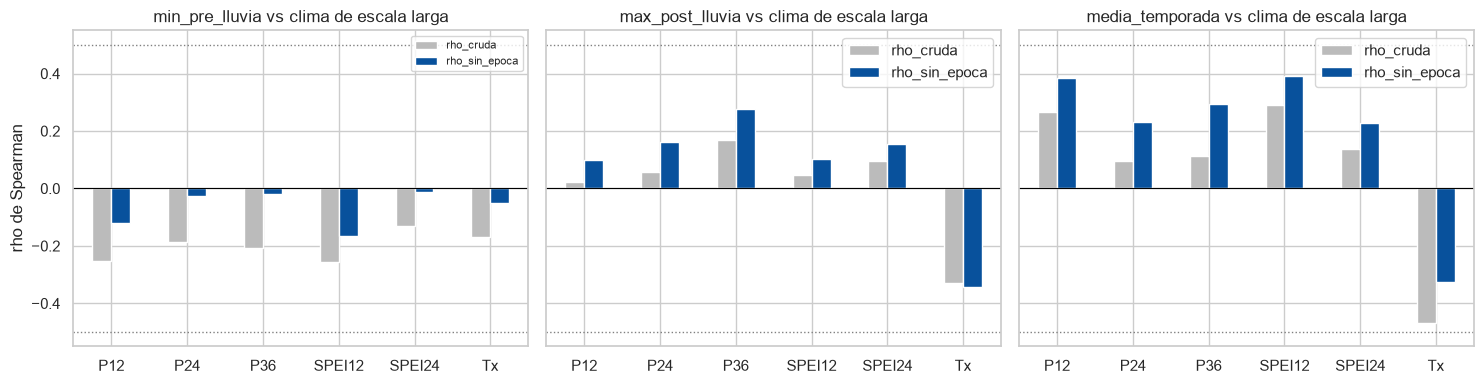

Mayor |rho| sin época con lluvia o SPEI: 0.39 (R² ≈ 15%). Las líneas punteadas marcan |rho| = 0.5, el orden de magnitud que reportan los estudios de lagos que responden a la lluvia.


In [31]:
# ---- 12.5 Correlaciones anuales (Spearman)
filas = []
for objetivo in OBJETIVOS_12:
    d = datos_objetivo(objetivo)
    y_sin_epoca = d["y"] - d.groupby("epoca")["y"].transform("mean")
    for v in PRED_CLIMA + EXTRA_12:
        r_c, p_c = spearmanr(d["y"], d[v])
        r_s, p_s = spearmanr(y_sin_epoca, d[v])
        filas.append((objetivo, v, r_c, p_c, r_s, p_s, len(d)))
tabla_corr_12 = pd.DataFrame(filas, columns=["objetivo", "variable", "rho_cruda", "p_cruda", "rho_sin_epoca",
                                             "p_sin_epoca", "n_años"]).set_index(["objetivo", "variable"]).round(3)
display(tabla_corr_12)

fig, axes = plt.subplots(1, len(OBJETIVOS_12), figsize=(15, 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, objetivo in zip(axes, OBJETIVOS_12):
    tabla_corr_12.loc[objetivo, ["rho_cruda", "rho_sin_epoca"]].plot.bar(ax=ax, color=["#bbbbbb", "#08519c"], rot=0)
    ax.axhline(0, color="black", lw=0.8)
    for lim in (-0.5, 0.5):
        ax.axhline(lim, color="gray", ls=":", lw=1)
    ax.set(title=f"{objetivo} vs clima de escala larga", ylabel="rho de Spearman", xlabel="")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

RHO_MAX_12 = tabla_corr_12.loc[(slice(None), PRED_CLIMA), "rho_sin_epoca"].abs().max()
print(f"Mayor |rho| sin época con lluvia o SPEI: {RHO_MAX_12:.2f} (R² ≈ {RHO_MAX_12 ** 2:.0%}). "
      "Las líneas punteadas marcan |rho| = 0.5, el orden de magnitud que reportan los estudios de lagos que responden a la lluvia.")

### 12.6 Validación un año hacia adelante

Para cada año de prueba desde 2000, cada modelo se entrena **solo con los años anteriores** (mínimo 12) y predice ese año. Se compara contra dos referencias:

- **Media de época:** el promedio de los años anteriores de la misma época de sensor.
- **Persistencia:** el valor del año anterior observado.

Modelos con clima: regresión lineal con `epoca` + una sola variable climática (con ~30 años no caben más), Ridge con todas y Random Forest con todas (como en Wang et al., 2023, aunque con tan pocos años puede sobreajustar).

En 2013 ningún modelo tiene años L8/L9 para aprender el salto, así que todos fallan parecido ese año; el error de 2013 no favorece a ningún modelo.

**Miscanti:** se informa además el test de Diebold-Mariano con corrección HLN y los años de prueba en que `epoca` no está identificada (prueba en L8/L9 sin ningún año L8/L9 en el entrenamiento). Los años con clima ERA5-Land (2020-2024) **no** entran aquí: son el hold-out de 12.6b.

**Veredicto:** el mejor modelo con clima se compara con la mejor referencia mediante un bootstrap pareado de los errores año a año. Si el intervalo de la diferencia de RMSE incluye el cero, el clima no mejora el pronóstico de forma demostrable. Elegir "el mejor" entre 7 modelos ya favorece a los modelos con clima, así que es una prueba generosa con ellos.


=== Objetivo: min_pre_lluvia (fuente original) ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Media de época (referencia),21.84,17.83,16,0.00
Ridge: época + todas,23.18,19.33,16,-1.35
Lineal: época + SPEI12,24.27,18.54,16,-2.44
Random Forest: época + todas,24.79,19.84,16,-2.96
Lineal: época + P36,25.28,20.69,16,-3.44
Lineal: época + SPEI24,25.43,20.07,16,-3.59
Lineal: época + P24,26.56,21.86,16,-4.72
Lineal: época + P12,27.54,20.64,16,-5.70
Persistencia: año anterior (referencia),29.75,23.15,16,-7.91


Años de prueba con `epoca` no identificada: [2014]
Mejor referencia: Media de época (referencia) (RMSE 21.84 ha)
Mejor con clima:  Ridge: época + todas (RMSE 23.18 ha)
RMSE referencia − RMSE clima = -1.34 ha (IC 95 % bootstrap pareado -6.86 a +4.65) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.
Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico +0.44, p = 0.668 (n = 16 años)

=== Objetivo: max_post_lluvia (fuente original) ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Random Forest: época + todas,25.27,19.48,19,1.95
Lineal: época + P36,27.21,19.20,19,0.01
Media de época (referencia),27.22,19.68,19,0.00
Ridge: época + todas,27.58,20.34,19,-0.36
Lineal: época + SPEI12,28.04,20.51,19,-0.82
Lineal: época + P12,28.67,20.85,19,-1.45
Lineal: época + SPEI24,29.46,21.60,19,-2.24
Persistencia: año anterior (referencia),30.34,23.32,19,-3.12
Lineal: época + P24,30.44,21.89,19,-3.22


Años de prueba con `epoca` no identificada: [2013]
Mejor referencia: Media de época (referencia) (RMSE 27.22 ha)
Mejor con clima:  Random Forest: época + todas (RMSE 25.27 ha)
RMSE referencia − RMSE clima = +1.95 ha (IC 95 % bootstrap pareado -4.98 a +7.40) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.
Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico -0.56, p = 0.583 (n = 19 años)

=== Objetivo: media_temporada (fuente original) ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Lineal: época + SPEI12,16.66,12.95,17,1.57
Lineal: época + P12,16.90,13.21,17,1.32
Lineal: época + P36,17.42,14.33,17,0.81
Lineal: época + SPEI24,18.02,15.16,17,0.21
Lineal: época + P24,18.20,15.12,17,0.03
Media de época (referencia),18.23,14.53,17,0.00
Ridge: época + todas,19.30,16.22,17,-1.07
Persistencia: año anterior (referencia),19.36,16.07,17,-1.14
Random Forest: época + todas,20.09,16.10,17,-1.86


Años de prueba con `epoca` no identificada: [2014]
Mejor referencia: Media de época (referencia) (RMSE 18.23 ha)
Mejor con clima:  Lineal: época + SPEI12 (RMSE 16.66 ha)
RMSE referencia − RMSE clima = +1.57 ha (IC 95 % bootstrap pareado -0.89 a +3.40) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.
Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico -1.15, p = 0.266 (n = 17 años)


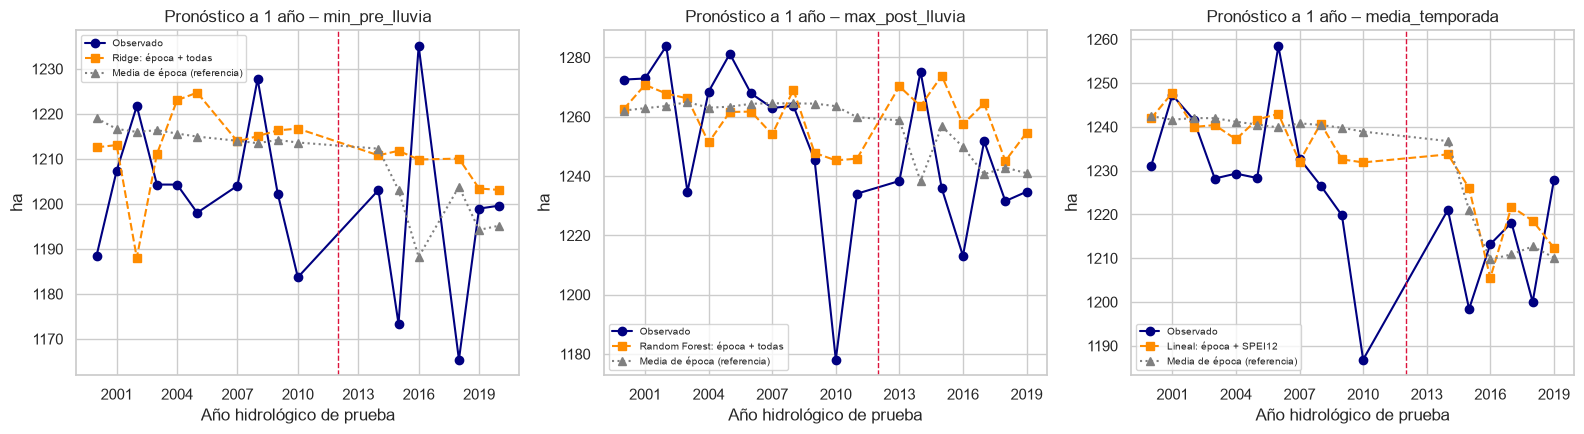

In [32]:
# ---- 12.6 Validación hacia adelante (1 año) con referencias
REF_EPOCA, REF_PERS = "Media de época (referencia)", "Persistencia: año anterior (referencia)"


def modelos_anuales_12():
    m = {REF_EPOCA: (LinearRegression(), ["epoca"])}     # con solo `epoca` predice la media de la época
    for v in PRED_CLIMA:
        m[f"Lineal: época + {v}"] = (LinearRegression(), ["epoca", v])
    todas = ["epoca"] + PRED_CLIMA + EXTRA_12
    m["Ridge: época + todas"] = (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))), todas)
    m["Random Forest: época + todas"] = (RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                                               random_state=SEMILLA, n_jobs=-1), todas)
    return m


def cv_anual_12(objetivo, desde=2000, min_entren=12, d=None, anios=None):
    d = datos_objetivo(objetivo) if d is None else d
    anios = d.index[d.index >= desde] if anios is None else anios
    preds, sin_ident = {}, []
    for anio in anios:
        tr = d[d.index < anio]
        if len(tr) < min_entren:
            continue
        if d.loc[anio, "epoca"] == 1 and tr["epoca"].sum() == 0:
            sin_ident.append(int(anio))        # `epoca` no identificada: prueba L8/L9 sin años L8/L9 en el entrenamiento
        fila = {"y": d.loc[anio, "y"], REF_PERS: tr["y"].iloc[-1]}
        for nombre, (mod, vars_) in modelos_anuales_12().items():
            fila[nombre] = clone(mod).fit(tr[vars_], tr["y"]).predict(d.loc[[anio], vars_])[0]
        preds[anio] = fila
    preds = pd.DataFrame(preds).T.astype(float)
    err = preds.drop(columns="y").sub(preds["y"], axis=0)
    tabla = pd.DataFrame({"RMSE": np.sqrt((err ** 2).mean()), "MAE": err.abs().mean(), "n_años": err.count()})
    tabla = tabla.sort_values("RMSE")
    mejor_ref = tabla.loc[[REF_EPOCA, REF_PERS], "RMSE"].idxmin()
    tabla["ganancia_vs_mejor_ref_ha"] = tabla.loc[mejor_ref, "RMSE"] - tabla["RMSE"]
    return tabla.round(2), preds, err, mejor_ref, sin_ident


def veredicto_12(tabla, err, mejor_ref, n_boot=5000):
    con_clima = [i for i in tabla.index if "(referencia)" not in i]
    mejor_cl = tabla.loc[con_clima, "RMSE"].idxmin()
    e_cl, e_ref = err[mejor_cl].values, err[mejor_ref].values
    rng = np.random.default_rng(SEMILLA)
    idx = rng.integers(0, len(e_cl), size=(n_boot, len(e_cl)))
    dif = np.sqrt((e_ref[idx] ** 2).mean(axis=1)) - np.sqrt((e_cl[idx] ** 2).mean(axis=1))
    lo, hi = np.percentile(dif, [2.5, 97.5])
    gana = lo > 0
    s_dm, p_dm = dm_hln(e_cl, e_ref)
    print(f"Mejor referencia: {mejor_ref} (RMSE {tabla.loc[mejor_ref, 'RMSE']:.2f} ha)")
    print(f"Mejor con clima:  {mejor_cl} (RMSE {tabla.loc[mejor_cl, 'RMSE']:.2f} ha)")
    print(f"RMSE referencia − RMSE clima = {tabla.loc[mejor_ref, 'RMSE'] - tabla.loc[mejor_cl, 'RMSE']:+.2f} ha "
          f"(IC 95 % bootstrap pareado {lo:+.2f} a {hi:+.2f}) → "
          + ("el clima MEJORA el pronóstico de forma demostrable." if gana else
             "el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable."))
    print(f"Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico {s_dm:+.2f}, p = {p_dm:.3f} (n = {len(e_cl)} años)")
    return gana, mejor_cl, p_dm


resultados_cv12 = {}
for objetivo in OBJETIVOS_12:
    print(f"\n=== Objetivo: {objetivo} (fuente {FUENTE_12}) ===")
    tabla, preds, err, mejor_ref, sin_ident = cv_anual_12(objetivo)
    display(tabla)
    print(f"Años de prueba con `epoca` no identificada: {sin_ident or 'ninguno'}")
    gana, mejor_cl, p_dm = veredicto_12(tabla, err, mejor_ref)
    resultados_cv12[objetivo] = {"tabla": tabla, "preds": preds, "gana": gana, "mejor_clima": mejor_cl, "mejor_ref": mejor_ref,
                                 "p_dm": p_dm, "sin_ident": sin_ident}

from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(1, len(OBJETIVOS_12), figsize=(16, 4.5))
axes = np.atleast_1d(axes)
for ax, (objetivo, r) in zip(axes, resultados_cv12.items()):
    p = r["preds"]
    ax.plot(p.index, p["y"], "o-", color="navy", label="Observado")
    ax.plot(p.index, p[r["mejor_clima"]], "s--", color="darkorange", label=r["mejor_clima"])
    ax.plot(p.index, p[r["mejor_ref"]], "^:", color="gray", label=r["mejor_ref"])
    ax.axvline(pd.Timestamp(QUIEBRE_SENSOR).year, color="crimson", ls="--", lw=1)
    ax.set(title=f"Pronóstico a 1 año – {objetivo}", xlabel="Año hidrológico de prueba", ylabel="ha")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 12.6b Hold-out anual 2020-2024

Se mantiene el protocolo de un año hacia adelante, pero solo en los años hidrológicos cuyo clima viene de ERA5-Land calibrado. El modelo con clima es el que **ya ganó en 12.6**; no se vuelve a elegir. Con tan pocos años no hay prueba estadística posible: el objetivo es ver si el resultado se sostiene fuera de la muestra.

In [33]:
# ---- 12.6b Hold-out anual: años cuyo clima viene de ERA5-Land calibrado (nunca usados para elegir modelos)
TABLA_HOLDOUT_12 = {}
for objetivo, r in resultados_cv12.items():
    d_val = datos_objetivo(objetivo)
    d_ext = datos_objetivo(objetivo, tabla=anual_12_ext)
    anios_h = d_ext.index[d_ext.index > d_val.index.max()]
    if len(anios_h) == 0:
        print(f"{objetivo}: sin años de hold-out (¿EXTENDER_CLIMA = False o sin área en 2020-2024?)")
        continue
    tabla_h, preds_h, err_h, _, sin_ident_h = cv_anual_12(objetivo, d=d_ext, anios=anios_h)
    filas_h = [r["mejor_clima"], REF_EPOCA, REF_PERS]          # el modelo con clima es el elegido en 12.6, no se vuelve a elegir
    TABLA_HOLDOUT_12[objetivo] = tabla_h.loc[filas_h, ["RMSE", "MAE", "n_años"]]
    print(f"\n=== Hold-out {objetivo}: años hidrológicos {list(map(int, anios_h))} ===")
    display(TABLA_HOLDOUT_12[objetivo])
    mejor_ref_h = TABLA_HOLDOUT_12[objetivo].loc[[REF_EPOCA, REF_PERS], "RMSE"].idxmin()
    dif = TABLA_HOLDOUT_12[objetivo].loc[mejor_ref_h, "RMSE"] - TABLA_HOLDOUT_12[objetivo].loc[r["mejor_clima"], "RMSE"]
    print(f"RMSE {mejor_ref_h} − RMSE {r['mejor_clima']} = {dif:+.2f} ha con {len(anios_h)} años: "
          "con tan pocos años no hay prueba estadística posible; sirve para ver si el resultado de 12.6 se sostiene fuera de muestra.")


=== Hold-out min_pre_lluvia: años hidrológicos [2021, 2022, 2023, 2024, 2025] ===


,RMSE,MAE,n_años
Ridge: época + todas,32.38,29.48,5
Media de época (referencia),19.12,15.81,5
Persistencia: año anterior (referencia),11.08,8.53,5


RMSE Persistencia: año anterior (referencia) − RMSE Ridge: época + todas = -21.30 ha con 5 años: con tan pocos años no hay prueba estadística posible; sirve para ver si el resultado de 12.6 se sostiene fuera de muestra.



=== Hold-out max_post_lluvia: años hidrológicos [2020, 2021, 2022, 2023, 2024] ===


,RMSE,MAE,n_años
Random Forest: época + todas,20.83,17.95,5
Media de época (referencia),18.38,16.17,5
Persistencia: año anterior (referencia),12.97,12.19,5


RMSE Persistencia: año anterior (referencia) − RMSE Random Forest: época + todas = -7.86 ha con 5 años: con tan pocos años no hay prueba estadística posible; sirve para ver si el resultado de 12.6 se sostiene fuera de muestra.



=== Hold-out media_temporada: años hidrológicos [2020, 2021, 2022, 2023, 2024] ===


,RMSE,MAE,n_años
Lineal: época + SPEI12,9.73,7.35,5
Media de época (referencia),11.96,11.33,5
Persistencia: año anterior (referencia),10.48,7.02,5


RMSE Persistencia: año anterior (referencia) − RMSE Lineal: época + SPEI12 = +0.75 ha con 5 años: con tan pocos años no hay prueba estadística posible; sirve para ver si el resultado de 12.6 se sostiene fuera de muestra.


### 12.6c Segunda fuente: el mismo análisis anual con JRC (decisión del 2026-11-08)

JRC aplica un mismo clasificador a todos los sensores y, según la etapa 1, tiene mucho menos ruido mensual que el NDWI por escena. Se repiten con la serie mensual JRC de 12.2 (meses con < 5 % del polígono sin dato y `MESES_USO`) los mismos objetivos, predictores, modelos y referencias de 12.5, 12.6 y 12.6b. **No se vuelve a elegir nada:** objetivos y modelos son los mismos que con NDWI.

Si NDWI y JRC llegan a conclusiones distintas, se reportan las dos; la diferencia es un resultado.

In [34]:
# ---- 12.6c Segunda fuente: correlaciones, validación un año adelante y hold-out con JRC Monthly History
resultados_jrc12, TABLA_HOLDOUT_JRC, tabla_corr_jrc, RHO_MAX_JRC = {}, {}, None, np.nan
if "jrc" not in mensual_12:
    print("No hay serie JRC (sección 1.2): se omite 12.6c.")
else:
    anual_12_jrc = tabla_anual(mensual_12["jrc"], pred_hist, df_clima, ndvi_anual)
    anual_12_jrc_ext = tabla_anual(mensual_12["jrc"], pred_ext, df_clima_ext, ndvi_anual)
    filas = []
    for objetivo in OBJETIVOS_12:
        d = datos_objetivo(objetivo, tabla=anual_12_jrc)
        y_sin_epoca = d["y"] - d.groupby("epoca")["y"].transform("mean")
        for v in PRED_CLIMA + EXTRA_12:
            r_s, p_s = spearmanr(y_sin_epoca, d[v])
            filas.append((objetivo, v, r_s, p_s, len(d)))
    tabla_corr_jrc = pd.DataFrame(filas, columns=["objetivo", "variable", "rho_sin_epoca", "p_sin_epoca", "n_años"]
                                  ).set_index(["objetivo", "variable"]).round(3)
    print("Correlaciones anuales sin época (Spearman), fuente JRC:")
    display(tabla_corr_jrc)
    RHO_MAX_JRC = tabla_corr_jrc.loc[(slice(None), PRED_CLIMA), "rho_sin_epoca"].abs().max()
    print(f"Mayor |rho| sin época con lluvia o SPEI (JRC): {RHO_MAX_JRC:.2f} | con NDWI (12.5): {RHO_MAX_12:.2f}")

    for objetivo in OBJETIVOS_12:
        print(f"\n=== JRC – objetivo {objetivo} ===")
        d = datos_objetivo(objetivo, tabla=anual_12_jrc)
        tabla, preds, err, mejor_ref, sin_ident = cv_anual_12(objetivo, d=d)
        display(tabla)
        print(f"Años de prueba con `epoca` no identificada: {sin_ident or 'ninguno'}")
        gana, mejor_cl, p_dm = veredicto_12(tabla, err, mejor_ref)
        resultados_jrc12[objetivo] = {"tabla": tabla, "gana": gana, "mejor_clima": mejor_cl, "mejor_ref": mejor_ref,
                                      "p_dm": p_dm, "sin_ident": sin_ident}
        d_ext = datos_objetivo(objetivo, tabla=anual_12_jrc_ext)
        anios_h = d_ext.index[d_ext.index > d.index.max()]
        if len(anios_h):
            tabla_h, *_ = cv_anual_12(objetivo, d=d_ext, anios=anios_h)
            TABLA_HOLDOUT_JRC[objetivo] = tabla_h.loc[[mejor_cl, REF_EPOCA, REF_PERS], ["RMSE", "MAE", "n_años"]]
            print(f"Hold-out JRC (años hidrológicos {list(map(int, anios_h))}):")
            display(TABLA_HOLDOUT_JRC[objetivo])

Correlaciones anuales sin época (Spearman), fuente JRC:


rho_sin_epoca  p_sin_epoca  n_años
objetivo        variable                                    
min_pre_lluvia  P12               0.097        0.579      35
                P24               0.207        0.233      35
                P36               0.176        0.313      35
                SPEI12            0.131        0.455      35
                SPEI24            0.213        0.220      35
                Tx               -0.011        0.950      35
max_post_lluvia P12               0.149        0.497      23
                P24               0.240        0.270      23
                P36               0.242        0.266      23
                SPEI12            0.111        0.615      23
                SPEI24            0.266        0.220      23
                Tx               -0.022        0.922      23
media_temporada P12               0.099        0.597      31
                P24               0.254        0.167      31
                P36               0.361        0.046      31
                SPEI12            0.086        0.646      31
                SPEI24            0.293        0.109      31
                Tx               -0.098        0.600      31

Mayor |rho| sin época con lluvia o SPEI (JRC): 0.36 | con NDWI (12.5): 0.39

=== JRC – objetivo min_pre_lluvia ===


,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Random Forest: época + todas,15.29,12.47,21,0.78
Lineal: época + P36,15.77,13.27,21,0.30
Ridge: época + todas,15.93,12.94,21,0.15
Media de época (referencia),16.07,13.52,21,0.00
Lineal: época + SPEI24,16.16,13.44,21,-0.09
Lineal: época + SPEI12,16.21,13.43,21,-0.13
Lineal: época + P24,16.23,13.36,21,-0.16
Lineal: época + P12,16.43,13.62,21,-0.36
Persistencia: año anterior (referencia),20.21,16.47,21,-4.14


Años de prueba con `epoca` no identificada: [2013]
Mejor referencia: Media de época (referencia) (RMSE 16.07 ha)
Mejor con clima:  Random Forest: época + todas (RMSE 15.29 ha)
RMSE referencia − RMSE clima = +0.78 ha (IC 95 % bootstrap pareado -1.97 a +3.18) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.
Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico -0.57, p = 0.577 (n = 21 años)


Hold-out JRC (años hidrológicos [2021, 2022, 2023, 2024, 2025]):


... (7 outputs left out)

,RMSE,MAE,n_años,ganancia_vs_mejor_ref_ha
Lineal: época + P36,10.04,8.71,18,1.60
Lineal: época + P24,10.95,9.63,18,0.69
Lineal: época + SPEI24,11.02,9.77,18,0.62
Media de época (referencia),11.64,10.24,18,0.00
Lineal: época + P12,11.84,10.49,18,-0.21
Lineal: época + SPEI12,11.89,10.41,18,-0.25
Ridge: época + todas,12.13,10.59,18,-0.49
Random Forest: época + todas,13.73,12.16,18,-2.09
Persistencia: año anterior (referencia),13.77,8.37,18,-2.13


Años de prueba con `epoca` no identificada: [2014]
Mejor referencia: Media de época (referencia) (RMSE 11.64 ha)
Mejor con clima:  Lineal: época + P36 (RMSE 10.04 ha)
RMSE referencia − RMSE clima = +1.60 ha (IC 95 % bootstrap pareado -0.47 a +3.17) → el intervalo incluye el cero o es negativo: el clima NO mejora el pronóstico de forma demostrable.
Diebold-Mariano (HLN, h=1), mejor con clima vs mejor referencia: estadístico -1.59, p = 0.130 (n = 18 años)


Hold-out JRC (años hidrológicos [2020, 2021, 2022, 2023, 2024]):


,RMSE,MAE,n_años
Lineal: época + P36,4.16,3.10,5
Media de época (referencia),6.30,4.84,5
Persistencia: año anterior (referencia),5.46,4.30,5


### 12.7 Proyección 2025-2095 con el modelo anual (análisis de sensibilidad)

Igual que en la plantilla: método delta por GCM desde 2006, para tener los 36 meses que necesitan P36 y SPEI-24 antes de 2025; SPEI futuro estandarizado contra CR2MET; `epoca = 1`; corrida de control con el clima constante de 1986-2005.

Cambios para Miscanti:
- Se proyectan **los tres objetivos**, cada uno con su mejor modelo con clima de 12.6 (serie NDWI).
- Los predictores se toman al cierre de `mes_corte` dentro de cada año hidrológico, igual que en 12.4.
- Solo entran los años hidrológicos con todos los meses del objetivo.

**En 12.6 el clima no mejoró el pronóstico en ningún objetivo ni con ninguna fuente:** esto es solo un análisis de sensibilidad.

GCMs: {'rcp26': 21, 'rcp85': 28}


min_pre_lluvia – RCP26: años-GCM fuera del rango de entrenamiento → P12 1%, P24 1%, P36 1%, SPEI12 11%, SPEI24 8%, Tx 47%


min_pre_lluvia – RCP85: años-GCM fuera del rango de entrenamiento → P12 1%, P24 2%, P36 1%, SPEI12 29%, SPEI24 33%, Tx 84%


max_post_lluvia – RCP26: años-GCM fuera del rango de entrenamiento → P12 0%, P24 0%, P36 1%, SPEI12 3%, SPEI24 4%, Tx 36%


max_post_lluvia – RCP85: años-GCM fuera del rango de entrenamiento → P12 0%, P24 0%, P36 3%, SPEI12 18%, SPEI24 27%, Tx 77%


media_temporada – RCP26: años-GCM fuera del rango de entrenamiento → SPEI12 4%


media_temporada – RCP85: años-GCM fuera del rango de entrenamiento → SPEI12 19%


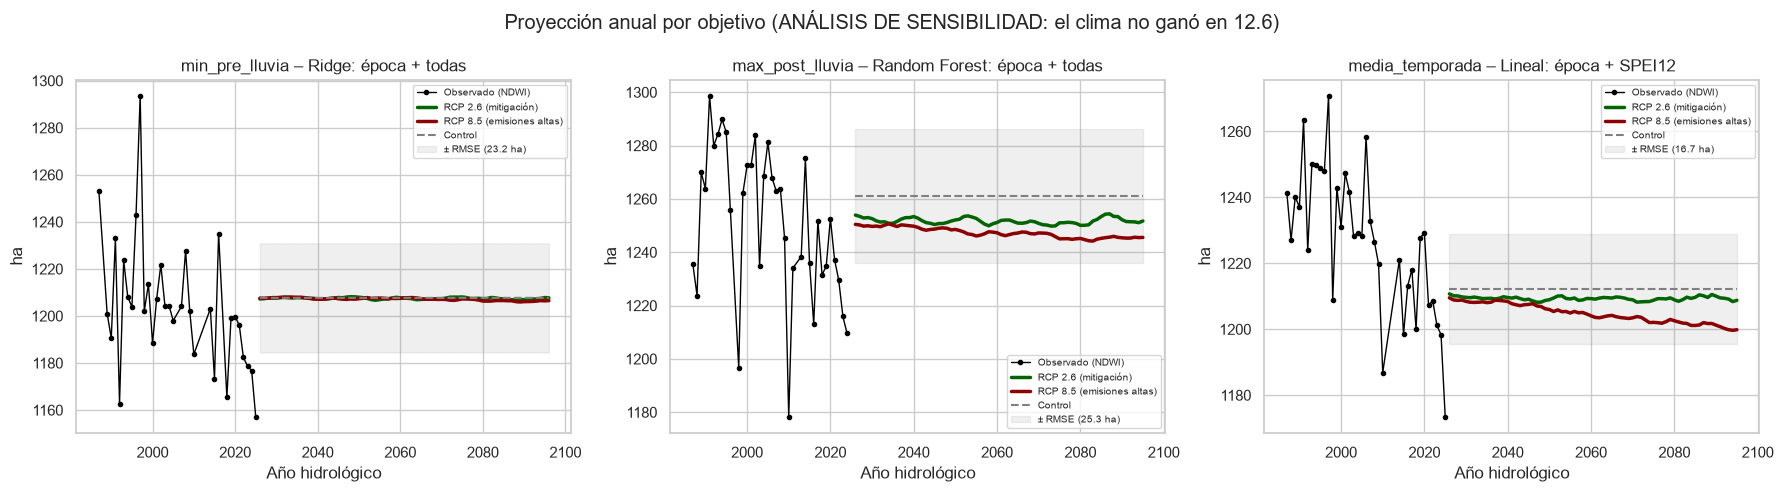

modelo  \
objetivo        horizonte                                                 
min_pre_lluvia  Corto plazo (2025-2040)            Ridge: época + todas   
                Mediano plazo (2041-2070)          Ridge: época + todas   
                Largo plazo (2071-2096)            Ridge: época + todas   
max_post_lluvia Corto plazo (2025-2040)    Random Forest: época + todas   
                Mediano plazo (2041-2070)  Random Forest: época + todas   
                Largo plazo (2071-2095)    Random Forest: época + todas   
media_temporada Corto plazo (2025-2040)          Lineal: época + SPEI12   
                Mediano plazo (2041-2070)        Lineal: época + SPEI12   
                Largo plazo (2071-2095)          Lineal: época + SPEI12   

                                           RCP26_ha  RCP85_ha  \
objetivo        horizonte                                       
min_pre_lluvia  Corto plazo (2025-2040)     1207.62   1207.70   
                Mediano plazo (2041-2070)   1207.43   1207.43   
                Largo plazo (2071-2096)     1207.48   1206.52   
max_post_lluvia Corto plazo (2025-2040)     1252.41   1250.01   
                Mediano plazo (2041-2070)   1251.59   1247.56   
                Largo plazo (2071-2095)     1251.48   1245.46   
media_temporada Corto plazo (2025-2040)     1209.68   1208.55   
                Mediano plazo (2041-2070)   1209.27   1205.26   
                Largo plazo (2071-2095)     1209.21   1201.69   

                                           RCP85_menos_RCP26_ha  \
objetivo        horizonte                                         
min_pre_lluvia  Corto plazo (2025-2040)                    0.08   
                Mediano plazo (2041-2070)                  0.00   
                Largo plazo (2071-2096)                   -0.96   
max_post_lluvia Corto plazo (2025-2040)                   -2.40   
                Mediano plazo (2041-2070)                 -4.03   
                Largo plazo (2071-2095)                   -6.02   
media_temporada Corto plazo (2025-2040)                   -1.13   
                Mediano plazo (2041-2070)                 -4.00   
                Largo plazo (2071-2095)                   -7.52   

                                           efecto_RCP26_vs_control_ha  \
objetivo        horizonte                                               
min_pre_lluvia  Corto plazo (2025-2040)                         -0.07   
                Mediano plazo (2041-2070)                       -0.26   
                Largo plazo (2071-2096)                         -0.21   
max_post_lluvia Corto plazo (2025-2040)                         -8.68   
                Mediano plazo (2041-2070)                       -9.50   
                Largo plazo (2071-2095)                         -9.61   
media_temporada Corto plazo (2025-2040)                         -2.61   
                Mediano plazo (2041-2070)                       -3.03   
                Largo plazo (2071-2095)                         -3.08   

                                           efecto_RCP85_vs_control_ha  \
objetivo        horizonte                                               
min_pre_lluvia  Corto plazo (2025-2040)                          0.01   
                Mediano plazo (2041-2070)                       -0.26   
                Largo plazo (2071-2096)                         -1.17   
max_post_lluvia Corto plazo (2025-2040)                        -11.08   
                Mediano plazo (2041-2070)                      -13.53   
                Largo plazo (2071-2095)                        -15.63   
media_temporada Corto plazo (2025-2040)                         -3.74   
                Mediano plazo (2041-2070)                       -7.03   
                Largo plazo (2071-2095)                        -10.60   

                                           RCP85_p10_gcms  RCP85_p90_gcms  \
objetivo        horizonte                                                   
min_pre_lluvia  Corto p

Un efecto del escenario menor que el RMSE de validación de su objetivo no se distingue del error del modelo.
ADVERTENCIA: en 12.6 el clima no mejoró el pronóstico de forma demostrable en ningún objetivo. Estas curvas son un análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.


In [35]:
# ---- 12.7 Proyección anual por GCM (método delta desde 2006), un modelo por objetivo
DESDE_GCM = "2006-01-01"
resumen_proy_12, proy_12 = None, {}


def X_futuro(clima, objetivo):
    """Predictores anuales del objetivo por año hidrológico completo desde 2026, en la escala de época L8/L9."""
    spec = OBJETIVOS_12[objetivo]
    pm, _ = predictores_mensuales(clima, referencia=REF_BALANCE)
    corte = pm[pm.index.month == spec["mes_corte"]].copy()
    corte.index = anio_hidro(corte.index)
    tx_m = clima["tmax"][clima.index.month.isin(spec["meses"])]
    ah = anio_hidro(tx_m.index)
    tx, n = tx_m.groupby(ah).mean(), tx_m.groupby(ah).count()
    anios = n.index[(n == len(spec["meses"])) & (n.index > pd.Timestamp(INICIO_PROY).year)]
    X = pd.DataFrame({"epoca": 1}, index=anios)
    for v in PRED_CLIMA:
        X[v] = corte[v].reindex(anios).values
    X["Tx"] = tx.reindex(anios).values
    if "ndvi_cuenca" in EXTRA_12:
        X["ndvi_cuenca"] = anual_12["ndvi_cuenca"].dropna().iloc[-5:].mean()
    return X.dropna()


if proy is None:
    print("12.7 omitida: faltan los CSV de proyecciones del CR2 para Miscanti (ver 3.2).")
else:
    idx_ctrl = pd.date_range(DESDE_GCM, proy["precip"].index.max(), freq="MS")
    clima_ctrl_12 = pd.DataFrame({v: CLIM_BASE[v].reindex(idx_ctrl.month).values for v in VARS_CLIMA}, index=idx_ctrl)
    climas = {esc: {g: clima_gcm(g, esc, desde=DESDE_GCM) for g in gcms_completos(esc, desde=DESDE_GCM)} for esc in ("rcp26", "rcp85")}
    print("GCMs:", {esc: len(c) for esc, c in climas.items()})
    filas = []
    fig, axes = plt.subplots(1, len(OBJETIVOS_12), figsize=(18, 5), sharey=False)
    axes = np.atleast_1d(axes)
    for ax, objetivo in zip(axes, OBJETIVOS_12):
        r = resultados_cv12[objetivo]
        mod, vars_ = modelos_anuales_12()[r["mejor_clima"]]
        d_obj = datos_objetivo(objetivo)
        mod = clone(mod).fit(d_obj[vars_], d_obj["y"])
        rmse = r["tabla"].loc[r["mejor_clima"], "RMSE"]
        proy_12[objetivo] = {esc: pd.DataFrame({g: pd.Series(mod.predict(X[vars_]), index=X.index)
                                                for g, X in ((g, X_futuro(c, objetivo)) for g, c in cl.items())})
                             for esc, cl in climas.items()}
        X_ctrl = X_futuro(clima_ctrl_12, objetivo)
        control = pd.Series(mod.predict(X_ctrl[vars_]), index=X_ctrl.index)
        vars_cl = [v for v in vars_ if v in PRED_CLIMA + ["Tx"]]
        for esc in ("rcp26", "rcp85"):
            Xf = pd.concat([X_futuro(c, objetivo) for c in climas[esc].values()])
            fuera = ((Xf[vars_cl] < d_obj[vars_cl].min()) | (Xf[vars_cl] > d_obj[vars_cl].max())).mean()
            print(f"{objetivo} – {esc.upper()}: años-GCM fuera del rango de entrenamiento → " + ", ".join(f"{v} {f:.0%}" for v, f in fuera.items()))
        ult = int(proy_12[objetivo]["rcp85"].index.max())
        for nombre_h, (a, b) in {"Corto plazo (2025-2040)": (2025, 2040), "Mediano plazo (2041-2070)": (2041, 2070),
                                 f"Largo plazo (2071-{ult})": (2071, ult)}.items():
            ctrl = control.loc[a:b].mean()
            m = {esc: proy_12[objetivo][esc].loc[a:b].mean() for esc in ("rcp26", "rcp85")}
            filas.append((objetivo, r["mejor_clima"], nombre_h, m["rcp26"].mean(), m["rcp85"].mean(),
                          m["rcp85"].mean() - m["rcp26"].mean(), m["rcp26"].mean() - ctrl, m["rcp85"].mean() - ctrl,
                          m["rcp85"].quantile(0.1), m["rcp85"].quantile(0.9), rmse))
        hist_o = anual_12[objetivo].dropna()
        ax.plot(hist_o.index, hist_o.values, "o-", color="black", ms=3, lw=1, label="Observado (NDWI)")
        for esc, (c_fino, c_grueso, etiqueta) in COLORES.items():
            ens = proy_12[objetivo][esc].mean(axis=1).rolling(5, center=True, min_periods=1).mean()
            ax.plot(ens.index, ens.values, color=c_grueso, lw=2.5, label=etiqueta)
        ax.plot(control.index, control.rolling(5, center=True, min_periods=1).mean(), color="gray", ls="--", label="Control")
        ax.fill_between(control.index, control - rmse, control + rmse, color="gray", alpha=0.12, label=f"± RMSE ({rmse:.1f} ha)")
        ax.set(title=f"{objetivo} – {r['mejor_clima']}", xlabel="Año hidrológico", ylabel="ha")
        ax.legend(fontsize=7)
    plt.suptitle("Proyección anual por objetivo (ANÁLISIS DE SENSIBILIDAD: el clima no ganó en 12.6)")
    plt.tight_layout()
    plt.show()
    resumen_proy_12 = pd.DataFrame(filas, columns=["objetivo", "modelo", "horizonte", "RCP26_ha", "RCP85_ha", "RCP85_menos_RCP26_ha",
                                                   "efecto_RCP26_vs_control_ha", "efecto_RCP85_vs_control_ha",
                                                   "RCP85_p10_gcms", "RCP85_p90_gcms", "RMSE_validacion_ha"]
                                   ).set_index(["objetivo", "horizonte"]).round(2)
    display(resumen_proy_12)
    print("Un efecto del escenario menor que el RMSE de validación de su objetivo no se distingue del error del modelo.")
if not any(r["gana"] for r in resultados_cv12.values()):
    print("ADVERTENCIA: en 12.6 el clima no mejoró el pronóstico de forma demostrable en ningún objetivo. Estas curvas son un "
          "análisis de sensibilidad del modelo, no una predicción con respaldo estadístico.")

In [36]:
# ---- 12.8 Exportación y resumen de la sección 12 (nombres con "miscanti": no se sobrescriben los anual12_*.csv de la Torca)
tabla_saltos.to_csv(DIR_PROC / f"anual12_saltos_por_fuente_{SUF}.csv")
pd.concat(pares_12, names=["fuente"]).to_csv(DIR_PROC / f"anual12_pares_L5_L7_{SUF}.csv")
anual_12.to_csv(DIR_PROC / f"anual12_base_anual_{SUF}.csv")
tabla_corr_12.to_csv(DIR_PROC / f"anual12_correlaciones_{SUF}.csv")
pd.concat({o: r["tabla"] for o, r in resultados_cv12.items()}, names=["objetivo", "modelo"]).to_csv(
    DIR_PROC / f"anual12_validacion_{SUF}.csv")
if TABLA_HOLDOUT_12:
    pd.concat(TABLA_HOLDOUT_12, names=["objetivo", "modelo"]).to_csv(DIR_PROC / f"anual12_holdout_{SUF}.csv")
if tabla_veg is not None:
    tabla_veg.to_csv(DIR_PROC / f"anual12_agua_vs_vegetacion_{SUF}.csv")
if resultados_jrc12:
    tabla_corr_jrc.to_csv(DIR_PROC / f"anual12_correlaciones_jrc_{SUF}.csv")
    pd.concat({o: r["tabla"] for o, r in resultados_jrc12.items()}, names=["objetivo", "modelo"]).to_csv(
        DIR_PROC / f"anual12_validacion_jrc_{SUF}.csv")
if resumen_proy_12 is not None:
    resumen_proy_12.to_csv(DIR_PROC / f"anual12_resumen_proyecciones_{SUF}.csv")
    for objetivo, por_esc in proy_12.items():
        for esc, df in por_esc.items():
            df.to_csv(DIR_PROC / f"anual12_proyeccion_{objetivo}_{esc}_{SUF}.csv")
if TABLA_HOLDOUT_JRC:
    pd.concat(TABLA_HOLDOUT_JRC, names=["objetivo", "modelo"]).to_csv(DIR_PROC / f"anual12_holdout_jrc_{SUF}.csv")
print("Archivos de la sección 12 guardados en:", DIR_PROC.resolve())

print("\n===== RESUMEN DE LA SECCIÓN 12 (MISCANTI) =====")
print(f"• Fuente del área: {FUENTE_12}" + (" (L7 corregido)" if L7_CORREGIDO_12 else ""))
print(f"• Sesgo Landsat 7 vs Landsat 5 (pares, serie original): {sesgos_l7['original']:+.1f} ha")
print("• Salto entre épocas (ajustado por lluvia), por fuente: " +
      ", ".join(f"{f} {s:+.1f} ha" for f, s in tabla_saltos["salto_ajustado_lluvia_ha"].items()))
if tabla_veg is not None:
    print(f"• Agua vs vegetación: rho de anomalías = {r_av:+.2f}; variabilidad de agua+vegetación / agua = {ratio:.2f}")
print(f"• Mayor |rho| anual sin época con lluvia acumulada o SPEI: {RHO_MAX_12:.2f}")
for o, r in resultados_cv12.items():
    t = r["tabla"]
    print(f"• {o}: mejor con clima {r['mejor_clima']} ({t.loc[r['mejor_clima'], 'RMSE']:.2f} ha) vs "
          f"{r['mejor_ref']} ({t.loc[r['mejor_ref'], 'RMSE']:.2f} ha), DM p = {r['p_dm']:.3f} → "
          + ("el clima mejora de forma demostrable" if r["gana"] else "el clima no mejora de forma demostrable"))
for o, r in resultados_jrc12.items():
    t = r["tabla"]
    print(f"• JRC – {o}: mejor con clima {r['mejor_clima']} ({t.loc[r['mejor_clima'], 'RMSE']:.2f} ha) vs "
          f"{r['mejor_ref']} ({t.loc[r['mejor_ref'], 'RMSE']:.2f} ha), DM p = {r['p_dm']:.3f} → "
          + ("el clima mejora de forma demostrable" if r["gana"] else "el clima no mejora de forma demostrable"))
if resumen_proy_12 is None:
    print("• Proyección: omitida (faltan los CSV del CR2 para Miscanti)")
else:
    largo = resumen_proy_12[resumen_proy_12.index.get_level_values("horizonte").str.startswith("Largo")]
    for (o, h), f in largo.iterrows():
        print(f"• Proyección {o}, {h}: RCP 8.5 − RCP 2.6 = {f['RCP85_menos_RCP26_ha']:+.2f} ha "
              f"(RMSE de validación {f['RMSE_validacion_ha']:.1f} ha) – análisis de sensibilidad")

Archivos de la sección 12 guardados en: C:\Users\jp200\Escritorio\Predicción laguna torca\data\processed

===== RESUMEN DE LA SECCIÓN 12 (MISCANTI) =====
• Fuente del área: original (L7 corregido)
• Sesgo Landsat 7 vs Landsat 5 (pares, serie original): +8.7 ha
• Salto entre épocas (ajustado por lluvia), por fuente: original -25.8 ha, jrc -12.3 ha
• Mayor |rho| anual sin época con lluvia acumulada o SPEI: 0.39
• min_pre_lluvia: mejor con clima Ridge: época + todas (23.18 ha) vs Media de época (referencia) (21.84 ha), DM p = 0.668 → el clima no mejora de forma demostrable
• max_post_lluvia: mejor con clima Random Forest: época + todas (25.27 ha) vs Media de época (referencia) (27.22 ha), DM p = 0.583 → el clima no mejora de forma demostrable
• media_temporada: mejor con clima Lineal: época + SPEI12 (16.66 ha) vs Media de época (referencia) (18.23 ha), DM p = 0.266 → el clima no mejora de forma demostrable
• JRC – min_pre_lluvia: mejor con clima Random Forest: época + todas (15.29 ha) vs 

### Cómo leer la sección 12

| Si se observa… | Lectura |
|---|---|
| El salto de 2012 se achica mucho en la serie armonizada o en JRC | El salto era sobre todo del sensor; conviene usar esa fuente (`FUENTE_AREA_12`) en todo el análisis |
| El salto se mantiene en todas las fuentes | Es un cambio real de la laguna (o un artefacto común a todas). `epoca` deja de ser solo una corrección y pasa a ser parte de la historia |
| Anomalías de agua y vegetación con correlación negativa fuerte, y agua + vegetación mucho más estable | Lo que varía es la cobertura de vegetación sobre una cubeta casi fija. El área de agua no es buen indicador del volumen |
| \|rho\| sin época ≥ 0.5 y el clima gana en 12.6 | La laguna sí responde a la lluvia a escala anual: la proyección RCP tiene respaldo |
| \|rho\| bajo y el clima no gana en 12.6 | El clima local, aun a escala anual y con ventanas largas, no explica el área. Lo más probable es que la regulen su conexión con el sistema lacustre del que forma parte, el manejo o el agua subterránea. La proyección es solo un análisis de sensibilidad |

Este último caso es un resultado válido y defendible. En la Torca se explicó por el canal a Vichuquén y el manejo de la barra; Miscanti no tiene ninguno de los dos, así que si aquí tampoco hay señal, las explicaciones que quedan son otras: amortiguación por agua subterránea (cuenca endorreica con filtración hacia Miñiques), un área poco sensible al nivel (orillas empinadas), errores del clima grillado en el altiplano o ruido de la serie satelital comparable a la señal.

**Lo que esta sección no incluye:** nivel de agua medido (no hay estación DGA en Miscanti), batimetría, Sentinel-2 y proyecciones (pendientes de la fuente).

## 13. Comparación Torca vs Miscanti

Las cifras de la Torca se leen de `Claude outputs/corrida_corregida_2026-11-08/` (la corrida auditada con su clima correcto). El Diebold-Mariano de la Torca se recalcula aquí con la misma función que en Miscanti. Como Miscanti es unas diez veces más grande, los errores y el salto se muestran también en % del área media.

La conclusión automática del final es preliminar. La redacción final va en `Claude outputs/resultados_miscanti_AAAA-MM-DD.md`, con las cifras verificadas.

In [37]:
# ---- 13. Torca (corrida corregida del 2026-11-08) vs Miscanti (esta ejecución). Las cifras de Torca se leen de sus CSV.
DIR_TORCA = BASE.parent / "Claude outputs" / "corrida_corregida_2026-11-08"


def fmt(x, dec=2, signo=False):
    return "—" if x is None or (isinstance(x, float) and np.isnan(x)) else (f"{x:+.{dec}f}" if signo else f"{x:.{dec}f}")


def mejor_vs_ref(tabla_cv):
    refs = [i for i in tabla_cv.index if "(referencia)" in i]
    con = [i for i in tabla_cv.index if "+ clima" in i]
    r, c = tabla_cv.loc[refs, "RMSE"].idxmin(), tabla_cv.loc[con, "RMSE"].idxmin()
    return c, tabla_cv.loc[c, "RMSE"], r, tabla_cv.loc[r, "RMSE"]


filas = {}
area_m = df_modelo[COL_AREA].mean()
# Si se corrigió el salto con JRC (sección 4), se devuelve el desfase para mostrar el salto NDWI sin corregir, comparable con Torca
# (restar una constante a todas las escenas L8/L9 baja la diferencia de medias y el coeficiente de `epoca` exactamente en esa constante)
ajuste_salto = DELTA_SALTO_JRC if CORREGIR_SALTO_JRC else 0.0
c_m, rm_c, r_m, rm_r = mejor_vs_ref(tabla_A)
anual_txt_m = "; ".join(f"{o}: {r['tabla'].loc[r['mejor_clima'], 'RMSE']:.2f} vs {r['tabla'].loc[r['mejor_ref'], 'RMSE']:.2f} ha "
                        f"(DM p = {r['p_dm']:.2f}, {'gana' if r['gana'] else 'no gana'})" for o, r in resultados_cv12.items())
mis = {
    "Área media observada (ha)": fmt(area_m, 0),
    "ρ máx. sin época, mensual": f"{RHO_MAX:.2f} ({tabla_corr['rho_anom_sin_epoca'].abs().idxmax()})",
    "ρ máx. sin época, anual (P o SPEI)": f"{RHO_MAX_12:.2f}",
    "Mensual: mejor con clima vs mejor referencia (RMSE, ha)": f"{rm_c:.2f} vs {rm_r:.2f} ({c_m.split(' (')[0]} vs {r_m.split(':')[0].split(' (')[0]})",
    "Mensual: misma comparación en % del área media": f"{100 * rm_c / area_m:.1f} % vs {100 * rm_r / area_m:.1f} %",
    "Mensual: DM-HLN con clima vs mejor referencia (p)": f"{tabla_dm['p_h1'].iloc[0]:.3f}",
    "Mensual: DM-HLN con vs sin clima, mismo modelo (p)": f"{tabla_dm['p_h1'].iloc[1]:.3f}",
    "Anual: mejor con clima vs mejor referencia": anual_txt_m,
    "ρ máx. sin época, anual, segunda fuente JRC": fmt(RHO_MAX_JRC),
    "Anual JRC: mejor con clima vs mejor referencia": "; ".join(
        f"{o}: {r['tabla'].loc[r['mejor_clima'], 'RMSE']:.2f} vs {r['tabla'].loc[r['mejor_ref'], 'RMSE']:.2f} ha "
        f"(DM p = {r['p_dm']:.2f}, {'gana' if r['gana'] else 'no gana'})" for o, r in resultados_jrc12.items()) or "—",
    "Salto entre épocas, crudo / ajustado por lluvia (ha)": (f"{tabla_saltos.loc['original', 'salto_crudo_ha'] + ajuste_salto:+.1f} / "
                                                              f"{tabla_saltos.loc['original', 'salto_ajustado_lluvia_ha'] + ajuste_salto:+.1f}"
                                                              + (" (NDWI sin corregir)" if CORREGIR_SALTO_JRC else "")),
    "Salto en % del área media": f"{100 * (tabla_saltos.loc['original', 'salto_crudo_ha'] + ajuste_salto) / area_m:+.1f} %",
    "Salto según JRC, mismos meses (ha) / desfase NDWI − JRC": f"{fmt(SALTO_JRC_PAREADO, 1, True)} / {fmt(DELTA_SALTO_JRC, 1, True)}",
    "Sesgo L7 − L5 (pares, ha)": fmt(sesgos_l7["original"], 1, True),
    "Efecto RCP 8.5 − 2.6 / SSP (largo plazo, ha)": (
        "omitido (faltan los CSV del CR2 para Miscanti)" if resumen_proy_12 is None else
        "; ".join(f"{o}: {f['RCP85_menos_RCP26_ha']:+.2f} (RMSE {f['RMSE_validacion_ha']:.1f})"
                  for (o, h), f in resumen_proy_12.iterrows() if h.startswith("Largo")) + " (RCP, CMIP5; sensibilidad)"),
}
filas["Miscanti"] = mis

if DIR_TORCA.exists():
    corr_t = pd.read_csv(DIR_TORCA / "correlaciones_v2.csv", index_col=0)
    cv_t = pd.read_csv(DIR_TORCA / "cv_nivel_area_v2.csv", index_col=0)
    saltos_t = pd.read_csv(DIR_TORCA / "anual12_saltos_por_fuente.csv", index_col=0)
    corr12_t = pd.read_csv(DIR_TORCA / "anual12_correlaciones.csv", index_col=[0, 1])
    val12_t = pd.read_csv(DIR_TORCA / "anual12_validacion.csv", index_col=[0, 1])
    proy12_t = pd.read_csv(DIR_TORCA / "anual12_resumen_proyecciones.csv", index_col=0)
    base_t = pd.read_csv(DIR_TORCA / "base_mensual_torca_v2.csv", index_col=0, parse_dates=True)
    area_t = base_t[COL_AREA].mean()
    c_t, rt_c, r_t, rt_r = mejor_vs_ref(cv_t)
    datos_t = base_t.loc[:"2019-12-01"].dropna(subset=[COL_AREA] + FEATS_CLIMA)
    E_t, _ = errores_cv(datos_t, COL_AREA, MODELOS[c_t.split(" (")[0]], FEATS_BASE, FEATS_CLIMA)
    dm_t = tabla_dm_desde(E_t, c_t.split(" (")[0])
    anual_txt_t = []
    for o in val12_t.index.get_level_values(0).unique():
        t = val12_t.loc[o]
        refs = [i for i in t.index if "(referencia)" in i]
        cl = t.drop(index=refs)["RMSE"].idxmin()
        anual_txt_t.append(f"{o}: {t.loc[cl, 'RMSE']:.2f} vs {t.loc[refs, 'RMSE'].min():.2f} ha")
    pred_t = [v for v in corr12_t.index.get_level_values(1).unique() if v.startswith(("P", "SPEI"))]
    filas["Torca"] = {
        "Área media observada (ha)": fmt(area_t, 0),
        "ρ máx. sin época, mensual": f"{corr_t['rho_anom_sin_epoca'].abs().max():.2f} ({corr_t['rho_anom_sin_epoca'].abs().idxmax()})",
        "ρ máx. sin época, anual (P o SPEI)": f"{corr12_t.loc[(slice(None), pred_t), 'rho_sin_epoca'].abs().max():.2f}",
        "Mensual: mejor con clima vs mejor referencia (RMSE, ha)": f"{rt_c:.2f} vs {rt_r:.2f} ({c_t.split(' (')[0]} vs {r_t.split(':')[0].split(' (')[0]})",
        "Mensual: misma comparación en % del área media": f"{100 * rt_c / area_t:.1f} % vs {100 * rt_r / area_t:.1f} %",
        "Mensual: DM-HLN con clima vs mejor referencia (p)": f"{dm_t['p_h1'].iloc[0]:.3f}",
        "Mensual: DM-HLN con vs sin clima, mismo modelo (p)": f"{dm_t['p_h1'].iloc[1]:.3f}",
        "Anual: mejor con clima vs mejor referencia": "; ".join(anual_txt_t),
        "ρ máx. sin época, anual, segunda fuente JRC": "no calculado",
        "Anual JRC: mejor con clima vs mejor referencia": "no calculado",
        "Salto entre épocas, crudo / ajustado por lluvia (ha)": (f"{saltos_t.loc['original', 'salto_crudo_ha']:+.1f} / "
                                                                  f"{saltos_t.loc['original', 'salto_ajustado_lluvia_ha']:+.1f}"),
        "Salto en % del área media": f"{100 * saltos_t.loc['original', 'salto_crudo_ha'] / area_t:+.1f} %",
        "Salto según JRC, mismos meses (ha) / desfase NDWI − JRC": "no calculado (12.1 no se ejecutó)",
        "Sesgo L7 − L5 (pares, ha)": fmt(saltos_t.loc["original", "sesgo_L7_vs_L5_ha"], 1, True),
        "Efecto RCP 8.5 − 2.6 / SSP (largo plazo, ha)": f"{proy12_t.filter(like='Largo', axis=0)['RCP85_menos_RCP26_ha'].iloc[0]:+.2f} (RCP, CMIP5)",
    }
else:
    print(f"No encuentro {DIR_TORCA}: la columna de Torca queda vacía.")

comparacion = pd.DataFrame(filas)[[c for c in ("Torca", "Miscanti") if c in filas]]
pd.set_option("display.max_colwidth", 120)
display(comparacion)
comparacion.to_csv(DIR_PROC / f"comparacion_torca_vs_{SUF}.csv")

# ---- Conclusión automática (la redacción final va en el informe, con las cifras verificadas)
gana_mensual = CLIMA_APORTA_7C          # le gana a la mejor referencia Y al mismo modelo sin clima (7c)
gana_anual = [o for o, r in resultados_cv12.items() if r["gana"]]
gana_jrc = [o for o, r in resultados_jrc12.items() if r["gana"]]
gana_ndwi = gana_mensual or bool(gana_anual)
if gana_ndwi and gana_jrc:
    print("Conclusión preliminar: en Miscanti el clima SÍ mejora el pronóstico sobre las referencias, con las DOS fuentes "
          f"(NDWI: {'mensual ' if gana_mensual else ''}{', '.join(gana_anual)}; JRC: {', '.join(gana_jrc)}). "
          "A diferencia de la Torca, el área de una laguna sin manejo responde al clima; la proyección tendría respaldo.")
elif gana_ndwi or gana_jrc:
    print("Conclusión preliminar: resultado MIXTO. El clima mejora el pronóstico solo con "
          + (f"NDWI ({'mensual ' if gana_mensual else ''}{', '.join(gana_anual)})" if gana_ndwi else f"JRC ({', '.join(gana_jrc)})")
          + ". Que las fuentes no coincidan indica que la señal está en el límite de lo que la medición permite ver; "
            "no basta para afirmar que la laguna responde al clima.")
else:
    print("Conclusión preliminar: en Miscanti el clima TAMPOCO mejora el pronóstico sobre las referencias simples, con ninguna "
          "de las dos fuentes (NDWI y JRC). "
          "[Inferencia] Como Miscanti no tiene canal ni barra, la falta de señal en la Torca no se explica solo por el manejo: también "
          "pesan el ruido de la serie satelital, la escala de la respuesta y la calidad del clima grillado. "
          "Cualquier proyección es solo un análisis de sensibilidad.")

,Torca,Miscanti
Área media observada (ha),129,1229
"ρ máx. sin época, mensual",0.18 (p3),0.35 (precip)
"ρ máx. sin época, anual (P o SPEI)",0.20,0.39
"Mensual: mejor con clima vs mejor referencia (RMSE, ha)",7.68 vs 7.82 (Ridge vs Persistencia),29.10 vs 32.89 (Ridge vs Climatología mensual)
Mensual: misma comparación en % del área media,5.9 % vs 6.1 %,2.4 % vs 2.7 %
Mensual: DM-HLN con clima vs mejor referencia (p),0.528,0.002
"Mensual: DM-HLN con vs sin clima, mismo modelo (p)",0.729,0.217
Anual: mejor con clima vs mejor referencia,min_verano: 4.71 vs 4.73 ha; media_anual: 3.70 vs 3.64 ha,"min_pre_lluvia: 23.18 vs 21.84 ha (DM p = 0.67, no gana); max_post_lluvia: 25.27 vs 27.22 ha (DM p = 0.58, no gana);..."
"ρ máx. sin época, anual, segunda fuente JRC",no calculado,0.36
Anual JRC: mejor con clima vs mejor referencia,no calculado,"min_pre_lluvia: 15.29 vs 16.07 ha (DM p = 0.58, no gana); max_post_lluvia: 8.20 vs 8.74 ha (DM p = 0.79, no gana); m..."


Conclusión preliminar: en Miscanti el clima TAMPOCO mejora el pronóstico sobre las referencias simples, con ninguna de las dos fuentes (NDWI y JRC). [Inferencia] Como Miscanti no tiene canal ni barra, la falta de señal en la Torca no se explica solo por el manejo: también pesan el ruido de la serie satelital, la escala de la respuesta y la calidad del clima grillado. Cualquier proyección es solo un análisis de sensibilidad.


## Notas metodológicas (Miscanti)

- **Clima.** CR2MET v2.0 mensual (0.05°, 1979-2019) en el píxel del lago. Es menos confiable en el altiplano que en Chile central, porque hay pocas estaciones [Inferencia]. ERA5-Land calibrado solo extiende 2020-2024 para el hold-out.
- **Sin imputación.** Igual que en la Torca: solo meses con área observada.
- **Cambio de sensor.** El salto L5/L7 → L8/L9 se mide con NDWI y con JRC (clasificador único). `epoca` se mantiene en todos los modelos, aunque se corrija el desfase con JRC.
- **Landsat 7 posterior a 2003.** Excluido de la serie principal (SLC-off); en 1999-2003 sirve para calibrar el sesgo L7 − L5.
- **Hielo, nieve y sal.** La máscara QA (bit 5) marca la nieve, pero el hielo y las costras salinas pueden pasar sin marca. 2.1 los busca por mes y `MESES_USO` los excluye.
- **Validación.** Ventana expansiva, siempre fuera de la muestra, contra media (de época), climatología y persistencia, con DM-HLN y bootstrap pareado, más un hold-out 2020-2024 con otro producto de clima.
- **Secciones 9 y 10 de la plantilla.** Se omiten: comparaban MICE y el modelo anual del notebook original de Torca.
- **No incluido.** Nivel medido (no hay estación DGA), batimetría, Sentinel-2 y, por ahora, proyecciones.